# Wavelet-Based Time-Frequency Analysis of Evolving Fluids

**Reference paper:** Armstrong, Scully, Clark, Corrigan, James (2021), *"A simple approach for adding thixotropy to an elasto-visco-plastic rheological model to facilitate structural interrogation of human blood"*, Journal of Non-Newtonian Fluid Mechanics 290, 104503.

---

### Purpose of this notebook

This notebook connects two halves of the project:

1. **The signal-processing half** (our project's core question): can wavelet-based time-frequency analysis resolve structural evolution in a rheological signal better than conventional Fourier methods?
2. **The mechanics half** (the reference paper): a physics-based model that tracks the same structural evolution through a structure parameter, lambda.

The key idea tying them together: the paper's structure parameter lambda(t) is derived purely from mechanical stress fitting, with **no dependence on Fourier or wavelet mathematics whatsoever**. That makes it an independent ground-truth reference signal. If our wavelet-derived features track lambda(t), that is direct evidence the wavelet approach is capturing genuine structural information rather than noise.

### Pipeline implemented here

```
Raw rheometer data (Excel)
        |
        v
  Preprocessing  (block parsing, uniform resampling, detrending, normalisation)
        |
        +-------------------------------+
        |                               |
        v                               v
  Time-frequency methods         Physical model (paper)
  CWT / DWT / STFT / fCWT        ethixo-EVP ODE -> lambda(t)
        |                               |
        v                               v
  Feature engineering  <-- validated against -->  lambda(t)
        |
        v
  Evaluation metrics (THD, SNR, R2/p, MAPE, amplitude/phase error,
                      transition-timing accuracy, AIC/BIC-style penalty)
        |
        v
  Model comparison and ranking
```

### Methods compared

| Family | Variants |
|---|---|
| CWT | Morlet, Paul, DOG, Shannon, Morse |
| DWT | db4, sym4, coif1, bior2.2, rbio2.2 |
| STFT | Hanning window, Gaussian window |
| Fast CWT | fCWT |
| Physical model | ethixo-EVP v1, ethixo-EVP v2, EVP-only (baseline) |

### Note on terminology: "gel point"

The project brief refers to *gel point timing accuracy*. The datasets available to us are **liquid blood rheology**, which has no gelation event. We therefore generalise this metric to **structural transition timing accuracy**, using two physically equivalent events that do exist in this data:

- the **stress overshoot peak** in step-up-in-shear-rate tests (the paper's headline result)
- the **structural recovery onset** in cessation-of-flow tests

Both are moments where the material's microstructure changes state abruptly, which is exactly what a gel point is. The same metric code will transfer directly to genuine gelation data once that is collected.

---
# Section 0. Environment Setup and Configuration

All configuration lives in this one section so nothing is hard-coded further down.

In [1]:
# Core scientific stack
import os
import sys
import glob
import warnings
import numpy as np
import pandas as pd

# Signal processing
import pywt
from scipy import signal as sp_signal
from scipy import stats as sp_stats
from scipy.integrate import solve_ivp
from scipy.optimize import differential_evolution, minimize
from scipy.interpolate import interp1d

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")

print("Python version :", sys.version.split()[0])
print("NumPy version  :", np.__version__)
print("Pandas version :", pd.__version__)
print("PyWavelets ver :", pywt.__version__)

# Checking for openpyxl, which pandas requires in order to read .xlsx files.
# Without it every workbook read fails and the notebook cannot proceed.
try:
    import openpyxl
    print("openpyxl       :", openpyxl.__version__, "(required for reading .xlsx files)")
except ImportError:
    print()
    print("=" * 74)
    print("MISSING REQUIRED PACKAGE: openpyxl")
    print("=" * 74)
    print("pandas needs openpyxl to read .xlsx files. Without it, none of the 15")
    print("workbooks can be opened and the notebook cannot run.")
    print()
    print("Install it, then restart the kernel and run all cells again:")
    print()
    print("    pip install openpyxl")
    print()
    print("Or directly from a notebook cell:")
    print()
    print("    !pip install openpyxl")
    print("=" * 74)
    raise ImportError(
        "openpyxl is required to read the .xlsx data files. "
        "Install it with: pip install openpyxl"
    )

Python version : 3.12.1
NumPy version  : 2.5.2
Pandas version : 3.0.5
PyWavelets ver : 1.8.0
openpyxl       : 3.1.5 (required for reading .xlsx files)


In [2]:
# Optional dependency: ssqueezepy, providing Generalized Morse Wavelets for CWT
try:
    from ssqueezepy import cwt as ssq_cwt
    HAS_SSQ = True
    print("ssqueezepy      : available (Morse wavelet enabled)")
except Exception as exception_message:
    HAS_SSQ = False
    print("ssqueezepy      : not available ->", exception_message)
    print("                  install with: pip install ssqueezepy")

# Optional dependency: fcwt, the Fast Continuous Wavelet Transform
try:
    import fcwt
    HAS_FCWT = True
    print("fcwt            : available")
except Exception as exception_message:
    HAS_FCWT = False
    print("fcwt            : not available ->", exception_message)
    print("                  install with: pip install fcwt")
    print("                  if it reports a missing libfftw3f, install FFTW:")
    print("                     macOS  : brew install fftw")
    print("                     Ubuntu : sudo apt-get install libfftw3-dev")

ssqueezepy      : available (Morse wavelet enabled)
fcwt            : available


In [3]:
# Project configuration

# Location of the 15 rheometer Excel files
DATA_DIRECTORY = "/Users/riamishra/Desktop/proj90107/data"

# Fall back to the local folder if the configured path is not present
if not os.path.isdir(DATA_DIRECTORY):
    for candidate_directory in ["./data", "../data", "/mnt/user-data/uploads", "."]:
        if os.path.isdir(candidate_directory) and glob.glob(os.path.join(candidate_directory, "data*.xlsx")):
            DATA_DIRECTORY = candidate_directory
            break

print("Data directory in use :", DATA_DIRECTORY)

# Primary analysis file.
# data8.xlsx is the JUN18 session, which is Mendeley data ref [42] in the paper & the exact Donor3 data used for the paper's main figures.
PRIMARY_DATA_FILE = "data8.xlsx"

# Published best-fit parameters for Donor 3, taken from Table 3 of the paper.
# These let us run the paper's model without refitting from scratch.
PAPER_PARAMETERS_DONOR3 = {
    "sigma_y0"      : 0.0034,   # yield stress, Pa
    "eta_infinity"  : 0.0028,   # infinite-shear viscosity, Pa s
    "eta_structural": 0.019,    # structural viscosity, Pa s
    "G_elastic"     : 0.29,     # elastic modulus, ethixo-EVP version 1, Pa
    "G_rouleaux"    : 0.14,     # elastic modulus of rouleaux, ethixo-EVP version 2, Pa
    "tr1"           : 0.77,     # shear breakdown time scale, s
    "tr2"           : 0.34,     # shear aggregation time scale, s^(1/2)
    "k_lambda"      : 0.88,     # Brownian build-up rate constant, 1/s
    "k_lambda_v2"   : 0.67,     # Brownian build-up rate constant for version 2, 1/s
}

# Uniform resampling rate used for all time-frequency analysis, Hz
RESAMPLE_FREQUENCY_HZ = 50.0

# Random seed so every run of this notebook gives identical numbers
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Primary analysis file :", PRIMARY_DATA_FILE)
print("Resampling frequency  :", RESAMPLE_FREQUENCY_HZ, "Hz")

Data directory in use : /Users/riamishra/Desktop/proj90107/data
Primary analysis file : data8.xlsx
Resampling frequency  : 50.0 Hz


In [4]:
# Consistent plotting style used throughout the notebook.
# Every figure produced below carries axis labels, units, a title and a legend.

plt.rcParams.update({
    "figure.figsize"     : (13, 5),
    "figure.dpi"         : 100,
    "savefig.dpi"        : 150,
    "font.size"          : 11,
    "axes.titlesize"     : 13,
    "axes.titleweight"   : "bold",
    "axes.labelsize"     : 11,
    "axes.grid"          : True,
    "grid.alpha"         : 0.3,
    "grid.linestyle"     : "--",
    "legend.frameon"     : True,
    "legend.framealpha"  : 0.9,
    "axes.spines.top"    : False,
    "axes.spines.right"  : False,
})

# Project colour palette, matching the presentation deck
COLOUR_DEEP_BLUE   = "#1F6F8B"
COLOUR_LIGHT_BLUE  = "#7FB8CE"
COLOUR_SKIN        = "#EFC9A2"
COLOUR_YELLOW      = "#F5C842"
COLOUR_TEXT_DARK   = "#2F3B45"
COLOUR_RED_ACCENT  = "#C1483B"
COLOUR_GREEN       = "#4C8B6A"

# Distinct colours for each analysis method so they stay identifiable across all figures
METHOD_COLOURS = {
    "CWT-Morlet"   : "#1F6F8B",
    "CWT-Paul"     : "#2E8FA8",
    "CWT-DOG"      : "#54A9BF",
    "CWT-Shannon"  : "#7FB8CE",
    "CWT-Morse"    : "#A5CDDD",
    "DWT-db4"      : "#8C5E2A",
    "DWT-sym4"     : "#A8763D",
    "DWT-coif1"    : "#C08F55",
    "DWT-bior2.2"  : "#D6AB7A",
    "DWT-rbio2.2"  : "#EFC9A2",
    "STFT-Hanning" : "#B8942F",
    "STFT-Gaussian": "#F5C842",
    "fCWT"         : "#C1483B",
}

# Sequential colormap for time-frequency scalogram images
SCALOGRAM_COLORMAP = LinearSegmentedColormap.from_list(
    "project_scalogram",
    ["#FFFFFF", "#DCEEF7", "#7FB8CE", "#1F6F8B", "#123D4D"]
)

print("Plot style configured.")
print("Number of distinct method colours defined:", len(METHOD_COLOURS))

Plot style configured.
Number of distinct method colours defined: 13


---
# Section 1. Understanding the Raw Data

## 1.1 What these files are

The 15 Excel workbooks are raw rheometer exports from the USMA / University of Delaware blood rheology group, the same group that authored the reference paper. Four of them are the exact Mendeley datasets cited in that paper:

| File | Session | Paper reference |
|---|---|---|
| data8.xlsx | JUN18 | Reference [42], the Donor 3 dataset used in the paper's main figures |
| data5.xlsx | JUL18 | Reference [43] |
| data9.xlsx | DEC17 | Reference [44] |
| data7.xlsx | FEB18 | Reference [45] |

The remaining files are sibling sessions from the same laboratory, except data14 and data15 which belong to a separate aspirin study.

This matters because it means we are not working with a toy dataset. The paper's published parameter values in Table 3 were fitted to this very data, so we can run the paper's model with its own published parameters and compare directly against the measurements.

## 1.2 Excel file layout

Each sheet holds several experiments side by side, separated by blank columns. The layout within each block is:

| Row | Contents |
|---|---|
| 0 | Condition label, for example `.25-->5(1/s)` or `LAOS omega=1; Gamma=5` |
| 1 | Column names, for example `Step time`, `Stress`, `Strain`, `Shear rate` |
| 2 | Units, for example `s`, `Pa`, `%`, `1/s` |
| 3 onward | Numeric data |

A single sheet can contain 18 such blocks. The parser below splits them into separate, clean time series.

## 1.3 Which sheets are usable for time-frequency analysis

This is an important distinction that determines what we can and cannot analyse:

| Sheet type | Is it a time series? | Usable for CWT / DWT / STFT? |
|---|---|---|
| Step Up Step Down | Yes, stress against time | Yes, and this is the highest-value target |
| Helton (triangle ramp) | Yes | Yes |
| LAOS, UDLAOS | Yes, oscillatory waveform | Yes, highest sampling rate |
| Cessation | Yes | Yes |
| SRFS, reversal | Yes | Yes |
| Steady State (SS) | No, one row per shear rate | No, used as reference values only |
| SAOS frequency sweep | No, one row per frequency | No, used as reference values only |

Steady state and SAOS sweeps are parametric, not temporal. Each row is a different experimental condition rather than a different moment in time, so a time-frequency transform has no meaning there. They are still valuable as reference data for the physical model.

In [5]:
def parse_multiblock_sheet(file_path, sheet_name):
    """
    Parsing a rheometer sheet that contains several experiment blocks side by side.

    The blocks are separated by fully empty columns. Within each block the layout is:
        row 0 -> condition label
        row 1 -> column names
        row 2 -> units
        row 3+ -> numeric data

    Returning a list of dictionaries, one for each block found.
    """
    raw_sheet = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
    number_of_columns = raw_sheet.shape[1]

    # Finding fully empty columns, which act as block separators
    empty_column_indices = []
    for column_index in range(number_of_columns):
        if raw_sheet.iloc[:, column_index].isna().all():
            empty_column_indices.append(column_index)

    # Grouping the remaining columns into contiguous blocks
    column_groups = []
    current_group = []
    for column_index in range(number_of_columns):
        if column_index in empty_column_indices:
            if len(current_group) > 0:
                column_groups.append(current_group)
                current_group = []
        else:
            current_group.append(column_index)
    if len(current_group) > 0:
        column_groups.append(current_group)

    # Building a clean dataframe for each block
    parsed_blocks = []
    for group in column_groups:

        # Reading the condition label from row 0
        block_label = raw_sheet.iloc[0, group[0]]
        if pd.isna(block_label):
            candidate_labels = []
            for column_index in group:
                value = raw_sheet.iloc[0, column_index]
                if not pd.isna(value):
                    candidate_labels.append(value)
            if len(candidate_labels) > 0:
                block_label = candidate_labels[0]
            else:
                block_label = "unlabelled_block_at_column_" + str(group[0])

        # Reading the column names from row 1 and the units from row 2
        header_names = []
        unit_names = []
        for column_index in group:
            header_names.append(raw_sheet.iloc[1, column_index])
            unit_names.append(raw_sheet.iloc[2, column_index])

        # Extracting the numeric data from row 3 onward
        block_data = raw_sheet.iloc[3:, group].copy()

        cleaned_column_names = []
        for position, header_value in enumerate(header_names):
            if pd.isna(header_value):
                cleaned_column_names.append("unnamed_column_" + str(position))
            else:
                cleaned_column_names.append(str(header_value).strip())
        block_data.columns = cleaned_column_names

        block_data = block_data.apply(pd.to_numeric, errors="coerce")
        block_data = block_data.dropna(how="all").reset_index(drop=True)

        parsed_blocks.append({
            "label"     : str(block_label).strip(),
            "units"     : unit_names,
            "data"      : block_data,
            "row_count" : len(block_data),
        })

    return parsed_blocks


print("Function parse_multiblock_sheet defined.")

Function parse_multiblock_sheet defined.


In [6]:
# Surveying every workbook in the data directory so we know exactly what is available

excel_file_paths = sorted(
    glob.glob(os.path.join(DATA_DIRECTORY, "data*.xlsx")),
    key=lambda path: int("".join(character for character in os.path.basename(path) if character.isdigit()) or 0)
)

print("Number of Excel workbooks found:", len(excel_file_paths))
print()

survey_records = []

for file_path in excel_file_paths:
    file_name = os.path.basename(file_path)
    try:
        excel_handle = pd.ExcelFile(file_path)
        for sheet_name in excel_handle.sheet_names:
            sheet_frame = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
            survey_records.append({
                "file"        : file_name,
                "sheet"       : sheet_name,
                "total_rows"  : sheet_frame.shape[0],
                "total_cols"  : sheet_frame.shape[1],
            })
    except ImportError as exception_message:
        print("Could not read", file_name, "-> missing Excel reader:", exception_message)
        print("   Fix: pip install openpyxl, then restart the kernel")
    except Exception as exception_message:
        print("Could not read", file_name, "->", exception_message)

survey_frame = pd.DataFrame(survey_records)

# Stopping here with a clear explanation if nothing could be read, rather than
# letting an empty table cause a confusing error several cells later.
if len(survey_frame) == 0:
    print()
    print("=" * 74)
    print("NO DATA COULD BE READ")
    print("=" * 74)
    print("Workbooks were found on disk but none could be opened.")
    print()
    print("The usual cause is a missing Excel reader. Install it, restart the")
    print("kernel, and run all cells again:")
    print()
    print("    pip install openpyxl")
    print()
    print("If openpyxl is already installed, check that DATA_DIRECTORY points at")
    print("the correct folder and that the files are readable.")
    print("Current DATA_DIRECTORY:", DATA_DIRECTORY)
    print("=" * 74)
    raise RuntimeError(
        "No sheets could be read from any workbook. "
        "Install openpyxl with: pip install openpyxl"
    )

print("Total sheets across all workbooks:", len(survey_frame))
print()
print("Sheets per workbook:")
print(survey_frame.groupby("file").size().to_string())

Number of Excel workbooks found: 15

Total sheets across all workbooks: 96

Sheets per workbook:
file
data1.xlsx      6
data10.xlsx     5
data11.xlsx     5
data12.xlsx     5
data13.xlsx     4
data14.xlsx    12
data15.xlsx    12
data2.xlsx      5
data3.xlsx      4
data4.xlsx      3
data5.xlsx      5
data6.xlsx      5
data7.xlsx      7
data8.xlsx      8
data9.xlsx     10


In [7]:
# Classifying every sheet by experiment type, and flagging which are true time series

def classify_sheet_type(sheet_name):
    """
    Classifying a sheet into an experiment family based on its name.
    Returning the experiment type and whether it is a genuine time series.
    """
    normalised_name = sheet_name.lower().strip()

    if "udlaos" in normalised_name:
        return "UDLAOS", True
    if "laos" in normalised_name:
        return "LAOS", True
    if "step" in normalised_name or "-->" in normalised_name:
        return "Step Up/Down", True
    if "helton" in normalised_name or "ramp" in normalised_name or "triangle" in normalised_name:
        return "Triangle Ramp", True
    if "cessation" in normalised_name:
        return "Cessation", True
    if "srfs" in normalised_name:
        return "SRFS", True
    if "reversal" in normalised_name:
        return "Flow Reversal", True
    if "bureau" in normalised_name:
        return "Bureau Step", True
    if "amplitude" in normalised_name or "frequency" in normalised_name:
        return "SAOS Sweep", False
    if "saos" in normalised_name or "steady" in normalised_name or normalised_name.startswith("ss"):
        return "Steady State / SAOS", False
    if "lab" in normalised_name or "donor" in normalised_name:
        return "Donor Physiology", False

    return "Other", False


survey_frame["experiment_type"] = survey_frame["sheet"].apply(lambda name: classify_sheet_type(name)[0])
survey_frame["is_time_series"]  = survey_frame["sheet"].apply(lambda name: classify_sheet_type(name)[1])

type_summary = (
    survey_frame
    .groupby(["experiment_type", "is_time_series"])
    .size()
    .reset_index(name="sheet_count")
    .sort_values("sheet_count", ascending=False)
)

print("Experiment types found across all 15 workbooks")
print("=" * 62)
print(type_summary.to_string(index=False))
print()
print("Total sheets that are true time series :",
      int(survey_frame["is_time_series"].sum()))
print("Total sheets that are parametric sweeps:",
      int((~survey_frame["is_time_series"]).sum()))

Experiment types found across all 15 workbooks
    experiment_type  is_time_series  sheet_count
   Donor Physiology           False           24
       Step Up/Down            True           14
               LAOS            True           13
Steady State / SAOS           False           13
      Triangle Ramp            True           11
             UDLAOS            True            7
              Other           False            5
         SAOS Sweep           False            4
          Cessation            True            2
               SRFS            True            2
      Flow Reversal            True            1

Total sheets that are true time series : 50
Total sheets that are parametric sweeps: 46


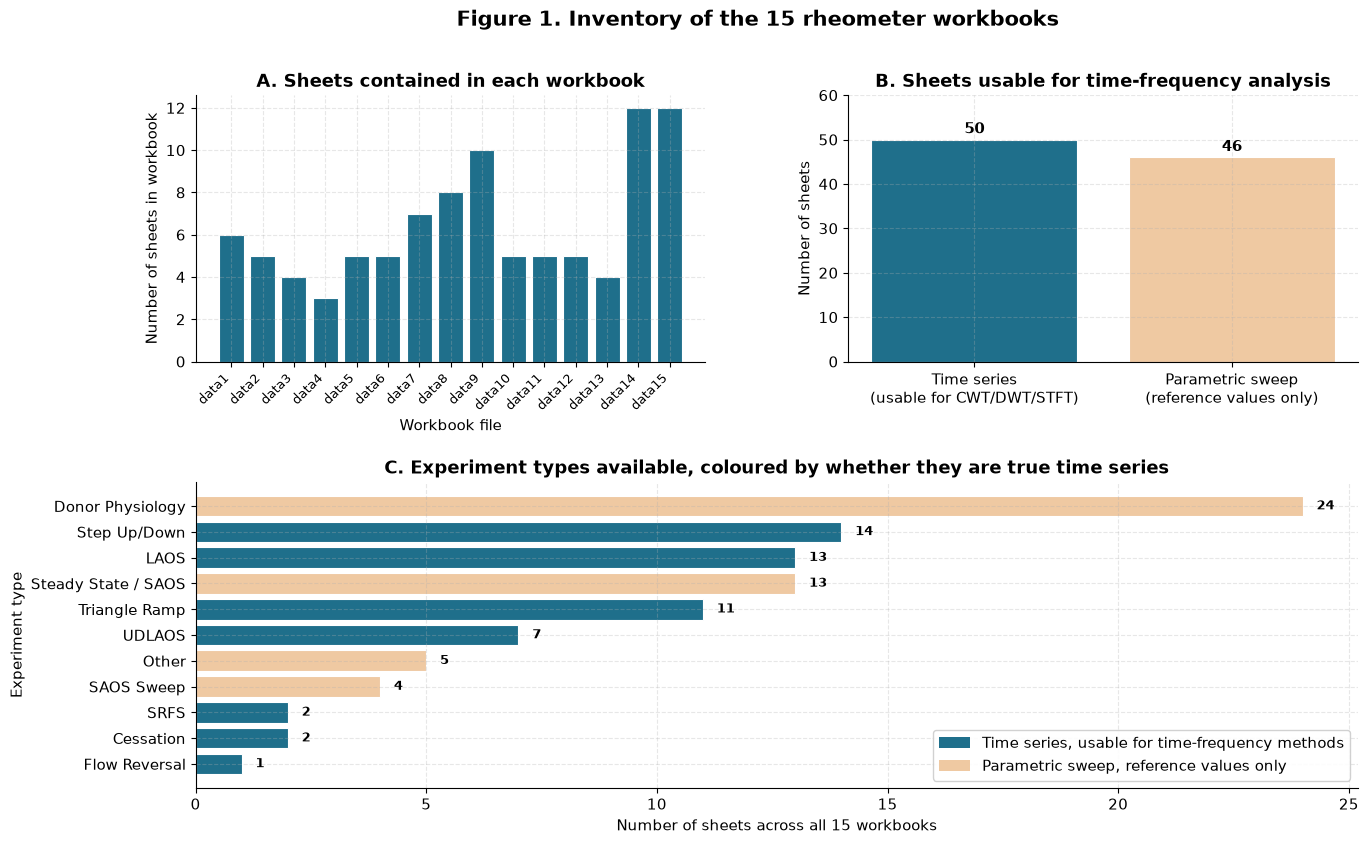

In [8]:
# Visualising the dataset inventory

figure = plt.figure(figsize=(15, 9))
grid = gridspec.GridSpec(2, 2, height_ratios=[1, 1.15], hspace=0.42, wspace=0.28)

# Panel A: number of sheets per workbook
axis_a = figure.add_subplot(grid[0, 0])
sheets_per_file = survey_frame.groupby("file").size()
file_order = sorted(sheets_per_file.index, key=lambda name: int("".join(c for c in name if c.isdigit())))
sheets_per_file = sheets_per_file.reindex(file_order)

axis_a.bar(range(len(sheets_per_file)), sheets_per_file.values,
           color=COLOUR_DEEP_BLUE, edgecolor="white", linewidth=0.8)
axis_a.set_xticks(range(len(sheets_per_file)))
axis_a.set_xticklabels([name.replace(".xlsx", "") for name in sheets_per_file.index],
                       rotation=45, ha="right", fontsize=9)
axis_a.set_xlabel("Workbook file")
axis_a.set_ylabel("Number of sheets in workbook")
axis_a.set_title("A. Sheets contained in each workbook")

# Panel B: time series versus parametric sweep
axis_b = figure.add_subplot(grid[0, 1])
time_series_counts = survey_frame["is_time_series"].value_counts()
bar_labels = ["Time series\n(usable for CWT/DWT/STFT)", "Parametric sweep\n(reference values only)"]
bar_values = [time_series_counts.get(True, 0), time_series_counts.get(False, 0)]
bar_colours = [COLOUR_DEEP_BLUE, COLOUR_SKIN]

bars = axis_b.bar(bar_labels, bar_values, color=bar_colours, edgecolor="white", linewidth=0.8)
for bar_object, value in zip(bars, bar_values):
    axis_b.text(bar_object.get_x() + bar_object.get_width() / 2, value + 0.6,
                str(value), ha="center", va="bottom", fontweight="bold")
axis_b.set_ylabel("Number of sheets")
axis_b.set_title("B. Sheets usable for time-frequency analysis")
axis_b.set_ylim(0, max(bar_values) * 1.2)

# Panel C: sheet count by experiment type
axis_c = figure.add_subplot(grid[1, :])
type_counts = survey_frame["experiment_type"].value_counts().sort_values()
type_is_time_series = {
    experiment_type: classify_sheet_type(experiment_type)[1]
    for experiment_type in type_counts.index
}
panel_c_colours = [
    COLOUR_DEEP_BLUE if survey_frame[survey_frame["experiment_type"] == experiment_type]["is_time_series"].iloc[0]
    else COLOUR_SKIN
    for experiment_type in type_counts.index
]

axis_c.barh(range(len(type_counts)), type_counts.values,
            color=panel_c_colours, edgecolor="white", linewidth=0.8)
axis_c.set_yticks(range(len(type_counts)))
axis_c.set_yticklabels(type_counts.index)
axis_c.set_xlabel("Number of sheets across all 15 workbooks")
axis_c.set_ylabel("Experiment type")
axis_c.set_title("C. Experiment types available, coloured by whether they are true time series")

for bar_index, value in enumerate(type_counts.values):
    axis_c.text(value + 0.3, bar_index, str(value), va="center", fontweight="bold", fontsize=9)

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=COLOUR_DEEP_BLUE, label="Time series, usable for time-frequency methods"),
    plt.Rectangle((0, 0), 1, 1, facecolor=COLOUR_SKIN, label="Parametric sweep, reference values only"),
]
axis_c.legend(handles=legend_handles, loc="lower right")

figure.suptitle("Figure 1. Inventory of the 15 rheometer workbooks",
                fontsize=15, fontweight="bold", y=0.975)
plt.show()

---
# Section 2. Preprocessing Pipeline

## 2.1 Why each preprocessing step is needed

| Step | Reason |
|---|---|
| Block extraction | One sheet holds up to 18 experiments side by side. Each must become its own clean series. |
| Uniform resampling | The rheometer does not sample at perfectly even intervals. Every time-frequency transform assumes a uniform grid, so this is mandatory, not optional. |
| Outlier clipping | Rheometer exports occasionally contain single-sample spikes from instrument artefacts, which would otherwise dominate a wavelet decomposition. |
| Detrending | Step tests contain a large constant offset. For harmonic analysis we care about the fluctuation around the trend, not the offset itself. |
| Normalisation | Different experiments span very different stress magnitudes. Normalising makes metrics comparable across experiments. |

## 2.2 A note on why uniform resampling matters here

We measured the actual sampling intervals in the raw files earlier. They are close to uniform but not exactly uniform, and the nominal rate varies by experiment type from roughly 1 Hz for flow reversal up to 50 Hz for LAOS. Since a wavelet scale maps to a physical frequency only through the sampling rate, a non-uniform grid silently distorts that mapping. Resampling onto a fixed grid removes that error source before any transform is applied.

In [9]:
def extract_time_series(block_dictionary,
                        time_column_candidates=("Step time", "step time", "Time", "time"),
                        value_column_candidates=("Stress", "stress")):
    """
    Extracting a clean (time, value) pair from a parsed block.

    Returning None when the block does not contain both a usable time column
    and a usable value column, so that callers can skip it safely.
    """
    block_frame = block_dictionary["data"]

    # Locating the time column
    time_column_name = None
    for candidate_name in time_column_candidates:
        if candidate_name in block_frame.columns:
            time_column_name = candidate_name
            break

    # Locating the value column
    value_column_name = None
    for candidate_name in value_column_candidates:
        if candidate_name in block_frame.columns:
            value_column_name = candidate_name
            break

    if time_column_name is None or value_column_name is None:
        return None

    time_values  = pd.to_numeric(block_frame[time_column_name], errors="coerce").values
    value_values = pd.to_numeric(block_frame[value_column_name], errors="coerce").values

    # Removing rows where either quantity is missing
    valid_mask = np.isfinite(time_values) & np.isfinite(value_values)
    time_values  = time_values[valid_mask]
    value_values = value_values[valid_mask]

    if len(time_values) < 16:
        return None

    # Sorting by time in case the export is not ordered
    sort_order   = np.argsort(time_values)
    time_values  = time_values[sort_order]
    value_values = value_values[sort_order]

    return time_values, value_values


def resample_to_uniform_grid(time_values, value_values, target_frequency_hz):
    """
    Resampling an irregularly sampled series onto a uniform time grid.

    This is a mandatory step before any wavelet or Fourier transform, because
    every such transform assumes evenly spaced samples.
    """
    start_time = float(np.min(time_values))
    end_time   = float(np.max(time_values))
    duration   = end_time - start_time

    if duration <= 0:
        return None, None

    number_of_samples = int(np.floor(duration * target_frequency_hz)) + 1
    if number_of_samples < 16:
        return None, None

    uniform_time_grid = start_time + np.arange(number_of_samples) / target_frequency_hz

    interpolation_function = interp1d(
        time_values, value_values,
        kind="linear", bounds_error=False,
        fill_value=(value_values[0], value_values[-1])
    )
    uniform_values = interpolation_function(uniform_time_grid)

    return uniform_time_grid, uniform_values


def clip_extreme_outliers(value_values, sigma_threshold=8.0):
    """
    Clipping isolated instrument spikes that sit far outside the normal range.

    A very wide threshold is used deliberately. The goal is only to remove
    obvious instrument artefacts, not to smooth away genuine physical features
    such as the stress overshoot, which is the signal we are trying to detect.
    """
    median_value = np.median(value_values)
    median_absolute_deviation = np.median(np.abs(value_values - median_value))

    if median_absolute_deviation <= 0:
        return value_values.copy(), 0

    robust_standard_deviation = 1.4826 * median_absolute_deviation
    lower_bound = median_value - sigma_threshold * robust_standard_deviation
    upper_bound = median_value + sigma_threshold * robust_standard_deviation

    number_clipped = int(np.sum((value_values < lower_bound) | (value_values > upper_bound)))
    clipped_values = np.clip(value_values, lower_bound, upper_bound)

    return clipped_values, number_clipped


print("Preprocessing helper functions defined:")
print("  extract_time_series")
print("  resample_to_uniform_grid")
print("  clip_extreme_outliers")

Preprocessing helper functions defined:
  extract_time_series
  resample_to_uniform_grid
  clip_extreme_outliers


In [10]:
def preprocess_signal(time_values, value_values,
                      target_frequency_hz=RESAMPLE_FREQUENCY_HZ,
                      apply_detrending=True,
                      apply_normalisation=True):
    """
    Running the full preprocessing chain on one raw signal.

    Returning a dictionary that carries every intermediate stage, so that later
    sections can plot the effect of each individual step rather than only the
    final result.
    """
    preprocessing_record = {}

    # Stage 1, keeping the raw input for reference
    preprocessing_record["raw_time"]   = time_values
    preprocessing_record["raw_value"]  = value_values
    preprocessing_record["raw_length"] = len(time_values)

    # Measuring the true sampling characteristics of the raw signal
    time_differences = np.diff(time_values)
    positive_differences = time_differences[time_differences > 0]
    if len(positive_differences) > 0:
        median_time_step = float(np.median(positive_differences))
        preprocessing_record["native_frequency_hz"] = 1.0 / median_time_step
        preprocessing_record["timing_jitter_percent"] = float(
            100.0 * np.std(positive_differences) / median_time_step
        )
    else:
        preprocessing_record["native_frequency_hz"] = np.nan
        preprocessing_record["timing_jitter_percent"] = np.nan

    # Stage 2, resampling onto a uniform grid
    uniform_time, uniform_value = resample_to_uniform_grid(
        time_values, value_values, target_frequency_hz
    )
    if uniform_time is None:
        return None

    preprocessing_record["uniform_time"]  = uniform_time
    preprocessing_record["uniform_value"] = uniform_value
    preprocessing_record["sampling_frequency_hz"] = target_frequency_hz

    # Stage 3, clipping obvious instrument spikes
    clipped_value, number_clipped = clip_extreme_outliers(uniform_value)
    preprocessing_record["clipped_value"]  = clipped_value
    preprocessing_record["number_clipped"] = number_clipped

    working_signal = clipped_value.copy()

    # Stage 4, removing the linear trend so harmonic content is not dominated by the offset
    if apply_detrending:
        detrended_signal = sp_signal.detrend(working_signal, type="linear")
        preprocessing_record["detrended_value"] = detrended_signal
        working_signal = detrended_signal
    else:
        preprocessing_record["detrended_value"] = working_signal.copy()

    # Stage 5, normalising to zero mean and unit standard deviation
    if apply_normalisation:
        signal_standard_deviation = np.std(working_signal)
        if signal_standard_deviation > 0:
            normalised_signal = (working_signal - np.mean(working_signal)) / signal_standard_deviation
        else:
            normalised_signal = working_signal - np.mean(working_signal)
        preprocessing_record["normalised_value"] = normalised_signal
        working_signal = normalised_signal
    else:
        preprocessing_record["normalised_value"] = working_signal.copy()

    preprocessing_record["processed_value"] = working_signal
    preprocessing_record["processed_time"]  = uniform_time
    preprocessing_record["processed_length"] = len(working_signal)

    return preprocessing_record


print("Function preprocess_signal defined.")
print()
print("Preprocessing stages applied in order:")
print("  1. Raw signal characterisation, measuring true sampling rate and jitter")
print("  2. Resampling onto a uniform time grid")
print("  3. Clipping isolated instrument spikes")
print("  4. Linear detrending")
print("  5. Normalisation to zero mean and unit standard deviation")

Function preprocess_signal defined.

Preprocessing stages applied in order:
  1. Raw signal characterisation, measuring true sampling rate and jitter
  2. Resampling onto a uniform time grid
  3. Clipping isolated instrument spikes
  4. Linear detrending
  5. Normalisation to zero mean and unit standard deviation


## 2.3 Loading the primary dataset

We work primarily with `data8.xlsx`, the JUN18 session. This is deliberate: it is Mendeley reference [42] in the paper and holds the Donor 3 data used for the paper's main figures, which means the published parameter values in Table 3 apply directly to it.

In [11]:
# Loading every time-series sheet from the primary workbook

primary_file_path = os.path.join(DATA_DIRECTORY, PRIMARY_DATA_FILE)
primary_excel_handle = pd.ExcelFile(primary_file_path)

print("Primary workbook :", PRIMARY_DATA_FILE)
print("Sheets present   :", primary_excel_handle.sheet_names)
print()

# Parsing each sheet into its constituent experiment blocks
parsed_sheets = {}

for sheet_name in primary_excel_handle.sheet_names:
    experiment_type, is_time_series = classify_sheet_type(sheet_name)

    if not is_time_series:
        print("Skipping '" + sheet_name + "' -> " + experiment_type + ", not a time series")
        continue

    blocks_in_sheet = parse_multiblock_sheet(primary_file_path, sheet_name)
    parsed_sheets[sheet_name] = {
        "experiment_type" : experiment_type,
        "blocks"          : blocks_in_sheet,
    }
    print("Parsed  '" + sheet_name + "' -> " + experiment_type +
          ", " + str(len(blocks_in_sheet)) + " experiment blocks")

print()
total_blocks = sum(len(entry["blocks"]) for entry in parsed_sheets.values())
print("Total experiment blocks available in this workbook:", total_blocks)

Primary workbook : data8.xlsx
Sheets present   : ['Steady State & SAOS', 'Helton', 'Step Up Step Down', 'LAOS', 'reversal', 'Cessation ', 'SRFS', 'UDLAOS']

Skipping 'Steady State & SAOS' -> Steady State / SAOS, not a time series
Parsed  'Helton' -> Triangle Ramp, 18 experiment blocks
Parsed  'Step Up Step Down' -> Step Up/Down, 14 experiment blocks
Parsed  'LAOS' -> LAOS, 18 experiment blocks
Parsed  'reversal' -> Flow Reversal, 6 experiment blocks
Parsed  'Cessation ' -> Cessation, 10 experiment blocks
Parsed  'SRFS' -> SRFS, 6 experiment blocks
Parsed  'UDLAOS' -> UDLAOS, 6 experiment blocks

Total experiment blocks available in this workbook: 78


In [12]:
# Building a catalogue of every usable individual experiment in the primary workbook

experiment_catalogue = []

for sheet_name, sheet_entry in parsed_sheets.items():
    for block_index, block_dictionary in enumerate(sheet_entry["blocks"]):

        extraction_result = extract_time_series(block_dictionary)
        if extraction_result is None:
            continue

        time_values, stress_values = extraction_result

        time_differences = np.diff(time_values)
        positive_differences = time_differences[time_differences > 0]
        if len(positive_differences) == 0:
            continue

        native_frequency = 1.0 / float(np.median(positive_differences))

        experiment_catalogue.append({
            "sheet"               : sheet_name,
            "experiment_type"     : sheet_entry["experiment_type"],
            "block_index"         : block_index,
            "condition_label"     : block_dictionary["label"],
            "sample_count"        : len(time_values),
            "duration_seconds"    : float(time_values[-1] - time_values[0]),
            "native_frequency_hz" : native_frequency,
            "stress_minimum"      : float(np.min(stress_values)),
            "stress_maximum"      : float(np.max(stress_values)),
            "stress_final"        : float(stress_values[-1]),
        })

catalogue_frame = pd.DataFrame(experiment_catalogue)

# Computing an overshoot ratio, which flags where structural transitions are strongest
catalogue_frame["overshoot_percent"] = (
    100.0 * (catalogue_frame["stress_maximum"] - catalogue_frame["stress_final"])
    / catalogue_frame["stress_final"].abs().replace(0, np.nan)
)

print("Usable individual experiments catalogued:", len(catalogue_frame))
print()
print("Breakdown by experiment type")
print("=" * 74)
summary_by_type = catalogue_frame.groupby("experiment_type").agg(
    experiment_count       = ("condition_label", "count"),
    median_samples         = ("sample_count", "median"),
    median_duration_s      = ("duration_seconds", "median"),
    median_frequency_hz    = ("native_frequency_hz", "median"),
).round(2)
print(summary_by_type.to_string())

Usable individual experiments catalogued: 77

Breakdown by experiment type
                 experiment_count  median_samples  median_duration_s  median_frequency_hz
experiment_type                                                                          
Cessation                      10            47.0              29.11                20.44
Flow Reversal                   6           180.0              44.45                 5.50
LAOS                           17          1996.0              39.98                50.00
SRFS                            6           269.0              53.60                 5.00
Step Up/Down                   14            65.0              63.00                16.30
Triangle Ramp                  18           314.0              62.60                 5.00
UDLAOS                          6           995.0              37.64                26.43


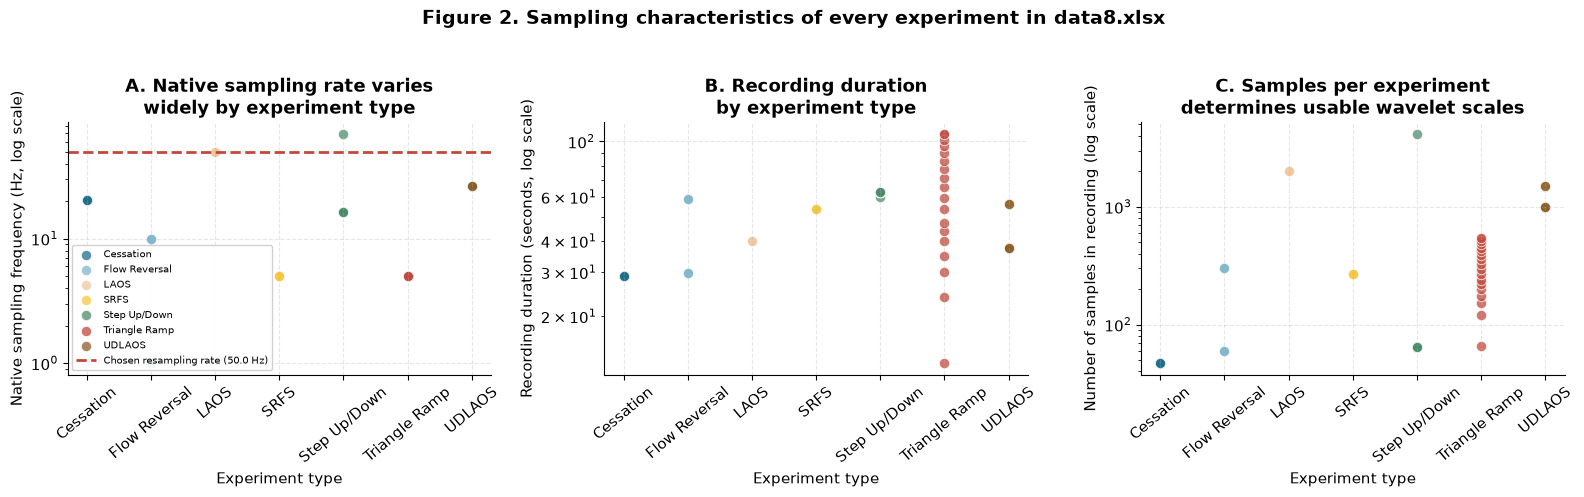


Interpretation
----------------------------------------------------------------------
Panel A shows sampling rate spanning roughly two orders of magnitude across
experiment types. Since a wavelet scale maps to a physical frequency only through
the sampling rate, analysing these on their native grids would make results
incomparable. Resampling everything to 50.0 Hz fixes that.

Panel C matters because the number of samples sets the largest wavelet scale that
can be resolved. Short recordings limit how much low-frequency detail is available.


In [13]:
# Visualising the sampling characteristics of every catalogued experiment.
# This shows concretely why a single fixed resampling rate is required.

figure, axes = plt.subplots(1, 3, figsize=(16, 4.8))

experiment_types_present = sorted(catalogue_frame["experiment_type"].unique())
type_colour_map = {
    experiment_type: colour for experiment_type, colour in zip(
        experiment_types_present,
        [COLOUR_DEEP_BLUE, COLOUR_LIGHT_BLUE, COLOUR_SKIN, COLOUR_YELLOW,
         COLOUR_GREEN, COLOUR_RED_ACCENT, "#8C5E2A", "#A5CDDD"]
    )
}

# Panel A: native sampling frequency by experiment type
axis_a = axes[0]
for experiment_type in experiment_types_present:
    subset = catalogue_frame[catalogue_frame["experiment_type"] == experiment_type]
    axis_a.scatter(
        [experiment_type] * len(subset),
        subset["native_frequency_hz"],
        s=55, alpha=0.75,
        color=type_colour_map[experiment_type],
        edgecolor="white", linewidth=0.7,
        label=experiment_type
    )
axis_a.axhline(RESAMPLE_FREQUENCY_HZ, color=COLOUR_RED_ACCENT, linestyle="--", linewidth=2,
               label="Chosen resampling rate (" + str(RESAMPLE_FREQUENCY_HZ) + " Hz)")
axis_a.set_yscale("log")
axis_a.set_xlabel("Experiment type")
axis_a.set_ylabel("Native sampling frequency (Hz, log scale)")
axis_a.set_title("A. Native sampling rate varies\nwidely by experiment type")
axis_a.tick_params(axis="x", rotation=40)
axis_a.legend(fontsize=7, loc="lower left")

# Panel B: recording duration by experiment type
axis_b = axes[1]
for experiment_type in experiment_types_present:
    subset = catalogue_frame[catalogue_frame["experiment_type"] == experiment_type]
    axis_b.scatter(
        [experiment_type] * len(subset),
        subset["duration_seconds"],
        s=55, alpha=0.75,
        color=type_colour_map[experiment_type],
        edgecolor="white", linewidth=0.7
    )
axis_b.set_yscale("log")
axis_b.set_xlabel("Experiment type")
axis_b.set_ylabel("Recording duration (seconds, log scale)")
axis_b.set_title("B. Recording duration\nby experiment type")
axis_b.tick_params(axis="x", rotation=40)

# Panel C: number of samples per experiment
axis_c = axes[2]
for experiment_type in experiment_types_present:
    subset = catalogue_frame[catalogue_frame["experiment_type"] == experiment_type]
    axis_c.scatter(
        [experiment_type] * len(subset),
        subset["sample_count"],
        s=55, alpha=0.75,
        color=type_colour_map[experiment_type],
        edgecolor="white", linewidth=0.7
    )
axis_c.set_yscale("log")
axis_c.set_xlabel("Experiment type")
axis_c.set_ylabel("Number of samples in recording (log scale)")
axis_c.set_title("C. Samples per experiment\ndetermines usable wavelet scales")
axis_c.tick_params(axis="x", rotation=40)

figure.suptitle("Figure 2. Sampling characteristics of every experiment in " + PRIMARY_DATA_FILE,
                fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

print()
print("Interpretation")
print("-" * 70)
print("Panel A shows sampling rate spanning roughly two orders of magnitude across")
print("experiment types. Since a wavelet scale maps to a physical frequency only through")
print("the sampling rate, analysing these on their native grids would make results")
print("incomparable. Resampling everything to " + str(RESAMPLE_FREQUENCY_HZ) + " Hz fixes that.")
print()
print("Panel C matters because the number of samples sets the largest wavelet scale that")
print("can be resolved. Short recordings limit how much low-frequency detail is available.")

## 2.4 Selecting the primary analysis signal

The step-up-in-shear-rate test is the highest-value target for this project, for three connected reasons:

1. It contains the **stress overshoot**, which is the paper's headline result and the exact behaviour that steady-state models fail to reproduce.
2. The overshoot is a genuine, physically meaningful **structural transition event** with a well-defined timing, giving us ground truth for transition-timing accuracy.
3. The paper explicitly models this test, so we can compare our signal-processing view directly against its mechanical prediction of lambda(t).

Below we rank the available step tests to choose the best one to analyse in detail.

One caution on selection: ranking purely by overshoot percentage is misleading. A small step such as 0.1 to 0.25 per second produces a very large percentage overshoot simply because its final stress sits close to the instrument noise floor, so the percentage is inflated by dividing by a very small number. We therefore rank by a combination of shear-rate ratio and absolute stress amplitude, which identifies the experiment where the structural transition is both physically strongest and comfortably above the noise floor.

In [14]:
# Identifying step-up experiments, which are those where shear rate increases

step_experiments = catalogue_frame[
    catalogue_frame["experiment_type"] == "Step Up/Down"
].copy()


def parse_step_condition(condition_label):
    """
    Parsing a condition label such as '.25-->5(1/s)' into its initial and final shear rates.
    Returning (initial_rate, final_rate, is_step_up).
    """
    cleaned_label = str(condition_label).replace("(1/s)", "").replace(" ", "")

    if "-->" not in cleaned_label:
        return np.nan, np.nan, None

    label_parts = cleaned_label.split("-->")
    if len(label_parts) != 2:
        return np.nan, np.nan, None

    try:
        initial_rate = float(label_parts[0])
        final_rate   = float(label_parts[1])
    except ValueError:
        return np.nan, np.nan, None

    return initial_rate, final_rate, (final_rate > initial_rate)


parsed_conditions = step_experiments["condition_label"].apply(parse_step_condition)
step_experiments["initial_shear_rate"] = [entry[0] for entry in parsed_conditions]
step_experiments["final_shear_rate"]   = [entry[1] for entry in parsed_conditions]
step_experiments["is_step_up"]         = [entry[2] for entry in parsed_conditions]

step_up_experiments = step_experiments[step_experiments["is_step_up"] == True].copy()
step_up_experiments = step_up_experiments.sort_values("overshoot_percent", ascending=False)

print("Step experiments found      :", len(step_experiments))
print("Of which are step-UP tests  :", len(step_up_experiments))
print()
print("Step-up experiments ranked by measured stress overshoot")
print("=" * 96)
display_columns = ["condition_label", "initial_shear_rate", "final_shear_rate",
                   "sample_count", "duration_seconds", "native_frequency_hz",
                   "stress_maximum", "stress_final", "overshoot_percent"]
print(step_up_experiments[display_columns].round(4).to_string(index=False))

Step experiments found      : 14
Of which are step-UP tests  : 9

Step-up experiments ranked by measured stress overshoot
condition_label  initial_shear_rate  final_shear_rate  sample_count  duration_seconds  native_frequency_hz  stress_maximum  stress_final  overshoot_percent
  .1-->.25(1/s)                0.10              0.25            65           63.0003              16.3024          0.0151        0.0078            93.5833
   .1-->5 (1/s)                0.10              5.00            65           62.9997              16.2862          0.0723        0.0462            56.3700
  .25-->.5(1/s)                0.25              0.50            65           62.9999              16.3024          0.0171        0.0115            49.0540
   .1-->.5(1/s)                0.10              0.50            65           62.9997              16.3024          0.0178        0.0121            47.0914
 .1-->2.5 (1/s)                0.10              2.50            65           62.9999             

In [15]:
# Selecting the single strongest step-up experiment as the primary analysis signal

# Ranking by shear-rate ratio and stress amplitude rather than raw overshoot percentage.
#
# Raw overshoot percentage alone is misleading here. A step such as 0.1 -> 0.25 shows a
# very large percentage overshoot only because its final stress is close to the instrument
# noise floor, so the percentage is inflated by dividing by a tiny number. Selecting on
# that basis would give us a noise-dominated signal.
#
# We instead select the experiment with the largest shear-rate ratio and a stress level
# well above the noise floor, which is where the structural transition is genuinely
# strongest and most reliably measurable.

step_up_experiments["shear_rate_ratio"] = (
    step_up_experiments["final_shear_rate"] / step_up_experiments["initial_shear_rate"]
)
step_up_experiments["stress_amplitude"] = step_up_experiments["stress_final"].abs()

# Combining both criteria into a single selection score
normalised_ratio = (
    step_up_experiments["shear_rate_ratio"] / step_up_experiments["shear_rate_ratio"].max()
)
normalised_amplitude = (
    step_up_experiments["stress_amplitude"] / step_up_experiments["stress_amplitude"].max()
)
step_up_experiments["selection_score"] = 0.5 * normalised_ratio + 0.5 * normalised_amplitude

step_up_experiments = step_up_experiments.sort_values("selection_score", ascending=False)

print("Step-up experiments ranked by selection score")
print("=" * 104)
selection_columns = ["condition_label", "initial_shear_rate", "final_shear_rate",
                     "shear_rate_ratio", "stress_amplitude", "overshoot_percent",
                     "selection_score"]
print(step_up_experiments[selection_columns].round(4).to_string(index=False))
print()

primary_experiment_row = step_up_experiments.iloc[0]

primary_sheet_name  = primary_experiment_row["sheet"]
primary_block_index = int(primary_experiment_row["block_index"])
primary_block       = parsed_sheets[primary_sheet_name]["blocks"][primary_block_index]

primary_raw_time, primary_raw_stress = extract_time_series(primary_block)

PRIMARY_INITIAL_SHEAR_RATE = float(primary_experiment_row["initial_shear_rate"])
PRIMARY_FINAL_SHEAR_RATE   = float(primary_experiment_row["final_shear_rate"])

print("PRIMARY ANALYSIS SIGNAL SELECTED")
print("=" * 70)
print("Source workbook        :", PRIMARY_DATA_FILE)
print("Source sheet           :", primary_sheet_name)
print("Condition label        :", primary_experiment_row["condition_label"])
print("Shear rate step        :", PRIMARY_INITIAL_SHEAR_RATE, "->", PRIMARY_FINAL_SHEAR_RATE, "1/s")
print("Raw sample count       :", len(primary_raw_time))
print("Recording duration     :", round(float(primary_experiment_row["duration_seconds"]), 3), "seconds")
print("Native sampling rate   :", round(float(primary_experiment_row["native_frequency_hz"]), 2), "Hz")
print("Measured overshoot     :", round(float(primary_experiment_row["overshoot_percent"]), 1), "percent")
print()
print("This experiment is used for the detailed method comparison in Sections 4 to 8.")
print("Section 9 repeats the full analysis across many experiments to check generality.")

Step-up experiments ranked by selection score
condition_label  initial_shear_rate  final_shear_rate  shear_rate_ratio  stress_amplitude  overshoot_percent  selection_score
   .1-->5 (1/s)                0.10              5.00              50.0            0.0462            56.3700           1.0000
   .25-->5(1/s)                0.25              5.00              20.0            0.0459            41.1982           0.6968
 .1-->2.5 (1/s)                0.10              2.50              25.0            0.0310            45.9071           0.5853
 .25-->2.5(1/s)                0.25              2.50              10.0            0.0310            35.0459           0.4354
   .1-->1 (1/s)                0.10              1.00              10.0            0.0182            34.1675           0.2972
   .25-->1(1/s)                0.25              1.00               4.0            0.0180            25.2301           0.2348
   .1-->.5(1/s)                0.10              0.50               5.0 

Preprocessing report for the primary signal
Raw sample count            : 65
Native sampling rate        : 16.29 Hz
Sampling interval jitter    : 3242.86 percent
Resampled sample count      : 3150
Resampled sampling rate     : 50.0 Hz
Outlier samples clipped     : 48



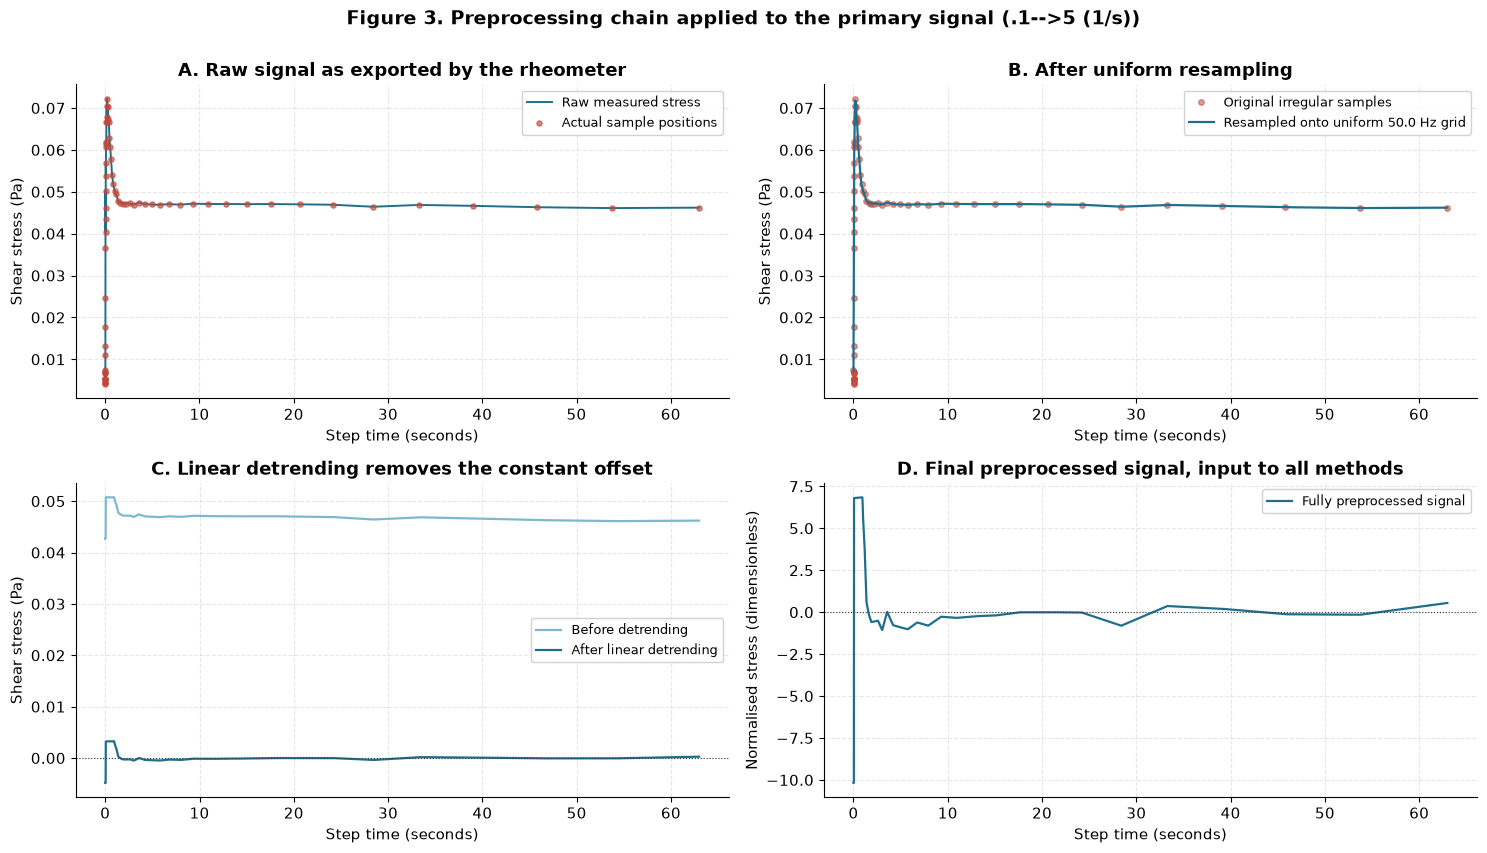

In [16]:
# Running the preprocessing chain on the primary signal and visualising every stage

primary_preprocessing = preprocess_signal(primary_raw_time, primary_raw_stress)

print("Preprocessing report for the primary signal")
print("=" * 70)
print("Raw sample count            :", primary_preprocessing["raw_length"])
print("Native sampling rate        :", round(primary_preprocessing["native_frequency_hz"], 2), "Hz")
print("Sampling interval jitter    :", round(primary_preprocessing["timing_jitter_percent"], 2), "percent")
print("Resampled sample count      :", primary_preprocessing["processed_length"])
print("Resampled sampling rate     :", primary_preprocessing["sampling_frequency_hz"], "Hz")
print("Outlier samples clipped     :", primary_preprocessing["number_clipped"])
print()

figure, axes = plt.subplots(2, 2, figsize=(15, 8.5))

# Panel A: raw signal with actual sample positions marked
axis_a = axes[0, 0]
axis_a.plot(primary_preprocessing["raw_time"], primary_preprocessing["raw_value"],
            color=COLOUR_DEEP_BLUE, linewidth=1.4, label="Raw measured stress")
axis_a.scatter(primary_preprocessing["raw_time"], primary_preprocessing["raw_value"],
               s=14, color=COLOUR_RED_ACCENT, zorder=5, alpha=0.65,
               label="Actual sample positions")
axis_a.set_xlabel("Step time (seconds)")
axis_a.set_ylabel("Shear stress (Pa)")
axis_a.set_title("A. Raw signal as exported by the rheometer")
axis_a.legend(fontsize=9)

# Panel B: uniform resampling result
axis_b = axes[0, 1]
axis_b.plot(primary_preprocessing["raw_time"], primary_preprocessing["raw_value"],
            "o", markersize=4, color=COLOUR_RED_ACCENT, alpha=0.55,
            label="Original irregular samples")
axis_b.plot(primary_preprocessing["uniform_time"], primary_preprocessing["uniform_value"],
            color=COLOUR_DEEP_BLUE, linewidth=1.6,
            label="Resampled onto uniform " + str(RESAMPLE_FREQUENCY_HZ) + " Hz grid")
axis_b.set_xlabel("Step time (seconds)")
axis_b.set_ylabel("Shear stress (Pa)")
axis_b.set_title("B. After uniform resampling")
axis_b.legend(fontsize=9)

# Panel C: detrending
axis_c = axes[1, 0]
axis_c.plot(primary_preprocessing["uniform_time"], primary_preprocessing["clipped_value"],
            color=COLOUR_LIGHT_BLUE, linewidth=1.6, label="Before detrending")
axis_c.plot(primary_preprocessing["uniform_time"], primary_preprocessing["detrended_value"],
            color=COLOUR_DEEP_BLUE, linewidth=1.6, label="After linear detrending")
axis_c.axhline(0, color=COLOUR_TEXT_DARK, linewidth=0.8, linestyle=":")
axis_c.set_xlabel("Step time (seconds)")
axis_c.set_ylabel("Shear stress (Pa)")
axis_c.set_title("C. Linear detrending removes the constant offset")
axis_c.legend(fontsize=9)

# Panel D: final normalised signal
axis_d = axes[1, 1]
axis_d.plot(primary_preprocessing["processed_time"], primary_preprocessing["processed_value"],
            color=COLOUR_DEEP_BLUE, linewidth=1.6,
            label="Fully preprocessed signal")
axis_d.axhline(0, color=COLOUR_TEXT_DARK, linewidth=0.8, linestyle=":")
axis_d.set_xlabel("Step time (seconds)")
axis_d.set_ylabel("Normalised stress (dimensionless)")
axis_d.set_title("D. Final preprocessed signal, input to all methods")
axis_d.legend(fontsize=9)

figure.suptitle(
    "Figure 3. Preprocessing chain applied to the primary signal (" +
    str(primary_experiment_row["condition_label"]) + ")",
    fontsize=14, fontweight="bold", y=1.0
)
plt.tight_layout()
plt.show()

---
# Section 3. The Physical Model from the Reference Paper

This section implements the ethixo-EVP model described in the paper. There is no public code release for this paper, so this is a fresh implementation directly from the published equations.

## 3.1 Why we need this in a wavelet project

The purpose is not to compete with the wavelet methods. The purpose is to produce an **independent reference signal**.

The structure parameter lambda(t) is obtained by solving a differential equation driven only by the imposed shear rate and the measured stress. It involves no Fourier transform, no wavelet basis, and no frequency decomposition of any kind. That independence is exactly what makes it useful: if a wavelet-derived feature correlates strongly with lambda(t), the correlation cannot be an artefact of shared mathematical machinery.

## 3.2 The equations implemented

**Structure evolution (paper Equation 13).** This governs how the microstructure parameter lambda changes through time:

$$\dot{\lambda} = k_{\lambda}\left[\, -tr_{1}\,|\dot{\gamma}_{p}|\,\lambda \;+\; tr_{2}\,|\dot{\gamma}_{p}|^{1/2}(1-\lambda) \;+\; (1-\lambda) \,\right]$$

The three bracketed terms are three competing physical processes:

| Term | Physical meaning |
|---|---|
| $-tr_{1}\,\|\dot{\gamma}_p\|\,\lambda$ | Shear breakdown. Structure is torn apart faster when shear is high and structure is intact. |
| $+tr_{2}\,\|\dot{\gamma}_p\|^{1/2}(1-\lambda)$ | Shear-driven aggregation. Flow brings particles together so they re-stick. |
| $+(1-\lambda)$ | Brownian build-up. Structure reforms from random thermal collisions even with no flow. |

**Constitutive equation, version 1 (paper Equation 11).** This links stress to shear rate through the current structure level:

$$\frac{1}{G}\dot{\sigma}_{tot} + \max\!\left(0,\; \frac{|\sigma_{tot}| - \lambda\sigma_{y0}}{(\lambda\eta_{ST} + \eta_{\infty})|\sigma_{tot}|}\right)\sigma_{tot} = \dot{\gamma}$$

**Constitutive equation, version 2 (paper Equation 12).** Here only the rouleaux stress evolves, and the plasma contribution is added on afterwards:

$$\frac{1}{G_{R}}\dot{\sigma}_{s} + \max\!\left(0,\; \frac{|\sigma_{s}| - \lambda\sigma_{y0}}{(\lambda\eta_{ST})|\sigma_{s}|}\right)\sigma_{s} = \dot{\gamma}_{p}, \qquad \sigma_{tot} = \sigma_{s} + \eta_{\infty}\dot{\gamma}$$

**Steady-state structure (paper Equation 16).** Setting the evolution equation to zero gives the equilibrium structure at any constant shear rate, which we use to set initial conditions:

$$\lambda_{ss} = \frac{tr_{2}|\dot{\gamma}|^{1/2} + 1}{tr_{1}|\dot{\gamma}| + tr_{2}|\dot{\gamma}|^{1/2} + 1}$$

**Baseline model, EVP-only (paper Equation 5).** This is the Stickel model with no thixotropy at all, included so we can show what is lost without a structure parameter.

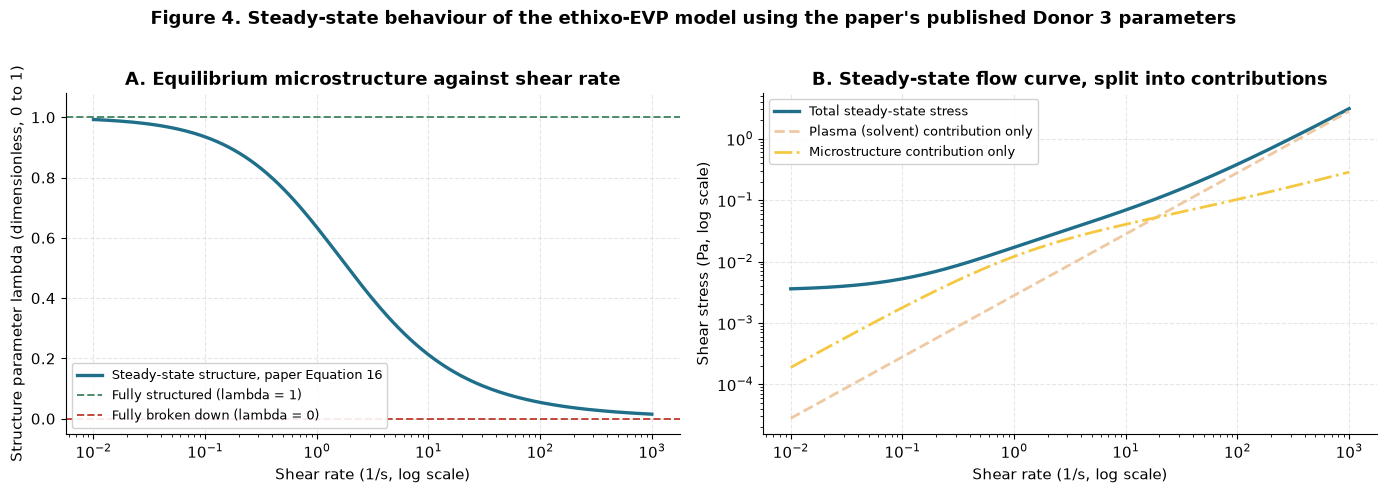

Interpretation
--------------------------------------------------------------------------
Panel A shows the physical core of the model. At low shear rate the blood is almost
fully structured, with rouleaux intact. As shear rate rises, lambda falls toward zero
as those stacks are torn apart. This single number is what the wavelet features
will later be validated against.


In [17]:
def compute_steady_state_lambda(shear_rate, tr1, tr2):
    """
    Computing the equilibrium structure parameter at a constant shear rate.

    This is paper Equation 16, obtained by setting the structure evolution
    equation to zero. It gives the structure level the material settles at
    if held at one shear rate indefinitely.
    """
    absolute_shear_rate = abs(float(shear_rate))
    numerator   = tr2 * np.sqrt(absolute_shear_rate) + 1.0
    denominator = tr1 * absolute_shear_rate + tr2 * np.sqrt(absolute_shear_rate) + 1.0
    return numerator / denominator


def compute_steady_state_stress(shear_rate, parameters):
    """
    Computing the steady-state stress at a constant shear rate.

    This is paper Equation 10, the steady-state constitutive equation:
        sigma_ss = lambda * sigma_y0 + lambda * eta_ST * gamma_dot + eta_infinity * gamma_dot
    """
    steady_lambda = compute_steady_state_lambda(
        shear_rate, parameters["tr1"], parameters["tr2"]
    )
    yield_contribution      = steady_lambda * parameters["sigma_y0"]
    structural_contribution = steady_lambda * parameters["eta_structural"] * abs(shear_rate)
    solvent_contribution    = parameters["eta_infinity"] * abs(shear_rate)

    return yield_contribution + structural_contribution + solvent_contribution


# Demonstrating how structure depends on shear rate
demonstration_shear_rates = np.logspace(-2, 3, 200)
demonstration_lambda = np.array([
    compute_steady_state_lambda(rate, PAPER_PARAMETERS_DONOR3["tr1"], PAPER_PARAMETERS_DONOR3["tr2"])
    for rate in demonstration_shear_rates
])
demonstration_stress = np.array([
    compute_steady_state_stress(rate, PAPER_PARAMETERS_DONOR3)
    for rate in demonstration_shear_rates
])

figure, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axis_a = axes[0]
axis_a.semilogx(demonstration_shear_rates, demonstration_lambda,
                color=COLOUR_DEEP_BLUE, linewidth=2.4,
                label="Steady-state structure, paper Equation 16")
axis_a.axhline(1.0, color=COLOUR_GREEN, linestyle="--", linewidth=1.4,
               label="Fully structured (lambda = 1)")
axis_a.axhline(0.0, color=COLOUR_RED_ACCENT, linestyle="--", linewidth=1.4,
               label="Fully broken down (lambda = 0)")
axis_a.set_xlabel("Shear rate (1/s, log scale)")
axis_a.set_ylabel("Structure parameter lambda (dimensionless, 0 to 1)")
axis_a.set_title("A. Equilibrium microstructure against shear rate")
axis_a.set_ylim(-0.05, 1.08)
axis_a.legend(fontsize=9, loc="lower left")

axis_b = axes[1]
axis_b.loglog(demonstration_shear_rates, demonstration_stress,
              color=COLOUR_DEEP_BLUE, linewidth=2.4,
              label="Total steady-state stress")
axis_b.loglog(demonstration_shear_rates,
              PAPER_PARAMETERS_DONOR3["eta_infinity"] * demonstration_shear_rates,
              color=COLOUR_SKIN, linewidth=2.0, linestyle="--",
              label="Plasma (solvent) contribution only")
axis_b.loglog(demonstration_shear_rates,
              demonstration_lambda * PAPER_PARAMETERS_DONOR3["eta_structural"] * demonstration_shear_rates,
              color=COLOUR_YELLOW, linewidth=2.0, linestyle="-.",
              label="Microstructure contribution only")
axis_b.set_xlabel("Shear rate (1/s, log scale)")
axis_b.set_ylabel("Shear stress (Pa, log scale)")
axis_b.set_title("B. Steady-state flow curve, split into contributions")
axis_b.legend(fontsize=9, loc="upper left")

figure.suptitle("Figure 4. Steady-state behaviour of the ethixo-EVP model using the paper's published Donor 3 parameters",
                fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("Interpretation")
print("-" * 74)
print("Panel A shows the physical core of the model. At low shear rate the blood is almost")
print("fully structured, with rouleaux intact. As shear rate rises, lambda falls toward zero")
print("as those stacks are torn apart. This single number is what the wavelet features")
print("will later be validated against.")

In [18]:
def simulate_ethixo_evp(shear_rate_function,
                        time_span,
                        parameters,
                        initial_shear_rate,
                        model_version=1,
                        number_of_output_points=2000):
    """
    Simulating the ethixo-EVP model through a transient shear-rate history.

    Solving the coupled system of paper Equation 11 or 12 for stress, together
    with paper Equation 13 for the structure parameter lambda.

    Returning time, total stress and lambda evaluated on a uniform grid.
    """
    sigma_y0       = parameters["sigma_y0"]
    eta_infinity   = parameters["eta_infinity"]
    eta_structural = parameters["eta_structural"]
    tr1            = parameters["tr1"]
    tr2            = parameters["tr2"]

    if model_version == 1:
        elastic_modulus         = parameters["G_elastic"]
        brownian_rate_constant  = parameters["k_lambda"]
    else:
        elastic_modulus         = parameters["G_rouleaux"]
        brownian_rate_constant  = parameters["k_lambda_v2"]

    def system_derivatives(current_time, state_vector):
        """
        Computing the time derivatives of stress and structure at one instant.
        """
        current_stress, current_lambda = state_vector
        current_lambda = min(max(current_lambda, 1e-9), 1.0)

        applied_shear_rate = shear_rate_function(current_time)

        # Building the plastic flow term, which is the max(0, ...) expression in the paper
        if model_version == 1:
            viscosity_term = (current_lambda * eta_structural + eta_infinity)
            stress_for_yield = current_stress
        else:
            viscosity_term = (current_lambda * eta_structural)
            stress_for_yield = current_stress

        absolute_stress = abs(stress_for_yield)
        denominator = viscosity_term * absolute_stress

        if denominator > 1e-14:
            yield_expression = (absolute_stress - current_lambda * sigma_y0) / denominator
            plastic_term = max(0.0, yield_expression)
        else:
            plastic_term = 0.0

        # Stress rate of change, rearranged from the paper's constitutive equation
        stress_derivative = elastic_modulus * (applied_shear_rate - plastic_term * stress_for_yield)

        # Plastic shear rate drives structure evolution
        plastic_shear_rate = plastic_term * abs(stress_for_yield)
        absolute_plastic_rate = abs(plastic_shear_rate)

        # Structure evolution, paper Equation 13, with its three physical terms
        shear_breakdown_term  = -tr1 * absolute_plastic_rate * current_lambda
        shear_aggregation_term = tr2 * np.sqrt(absolute_plastic_rate) * (1.0 - current_lambda)
        brownian_buildup_term  = (1.0 - current_lambda)

        lambda_derivative = brownian_rate_constant * (
            shear_breakdown_term + shear_aggregation_term + brownian_buildup_term
        )

        return [stress_derivative, lambda_derivative]

    # Setting initial conditions from the steady state at the starting shear rate
    initial_lambda = compute_steady_state_lambda(initial_shear_rate, tr1, tr2)

    if model_version == 1:
        initial_stress = (initial_lambda * sigma_y0
                          + (initial_lambda * eta_structural + eta_infinity) * initial_shear_rate)
    else:
        initial_stress = (initial_lambda * sigma_y0
                          + initial_lambda * eta_structural * initial_shear_rate)

    output_time_grid = np.linspace(time_span[0], time_span[1], number_of_output_points)

    solution = solve_ivp(
        system_derivatives,
        time_span,
        [initial_stress, initial_lambda],
        t_eval=output_time_grid,
        method="LSODA",
        rtol=1e-8,
        atol=1e-11,
    )

    simulated_stress = solution.y[0]
    simulated_lambda = np.clip(solution.y[1], 0.0, 1.0)

    # For version 2 the plasma contribution is superimposed after solving
    if model_version == 2:
        applied_rates = np.array([shear_rate_function(t) for t in solution.t])
        simulated_stress = simulated_stress + eta_infinity * applied_rates

    return solution.t, simulated_stress, simulated_lambda


print("Function simulate_ethixo_evp defined.")
print("Supports model_version = 1 (paper Equation 11) and model_version = 2 (paper Equation 12).")

Function simulate_ethixo_evp defined.
Supports model_version = 1 (paper Equation 11) and model_version = 2 (paper Equation 12).


In [19]:
def simulate_evp_only_baseline(shear_rate_function,
                               time_span,
                               parameters,
                               initial_shear_rate,
                               number_of_output_points=2000):
    """
    Simulating the baseline EVP-only model of Stickel and coworkers, paper Equation 5.

    This model has no structure parameter and therefore no thixotropy. It is
    included to demonstrate what behaviour is lost when structure is not tracked.
    """
    sigma_y0        = parameters["sigma_y0"]
    consistency_k   = parameters.get("consistency_k", 0.0117)
    power_law_index = parameters.get("power_law_n", 0.774)
    elastic_modulus = parameters.get("G_evp_only", 0.45)

    def system_derivative(current_time, state_vector):
        current_stress = state_vector[0]
        applied_shear_rate = shear_rate_function(current_time)

        absolute_stress = abs(current_stress)

        if absolute_stress > 1e-14:
            yield_numerator = absolute_stress - sigma_y0
            if yield_numerator > 0:
                plastic_term = (yield_numerator / (consistency_k * absolute_stress ** power_law_index))
                plastic_term = max(0.0, plastic_term) ** (1.0 / power_law_index)
            else:
                plastic_term = 0.0
        else:
            plastic_term = 0.0

        stress_derivative = elastic_modulus * (applied_shear_rate - plastic_term * current_stress)
        return [stress_derivative]

    initial_stress = sigma_y0 + consistency_k * (abs(initial_shear_rate) ** power_law_index)
    output_time_grid = np.linspace(time_span[0], time_span[1], number_of_output_points)

    solution = solve_ivp(
        system_derivative,
        time_span,
        [initial_stress],
        t_eval=output_time_grid,
        method="LSODA",
        rtol=1e-8,
        atol=1e-11,
    )

    return solution.t, solution.y[0]


# Adding the baseline model parameters from Table 3 of the paper
PAPER_PARAMETERS_DONOR3["consistency_k"] = 0.0117
PAPER_PARAMETERS_DONOR3["power_law_n"]   = 0.774
PAPER_PARAMETERS_DONOR3["G_evp_only"]    = 0.45

print("Function simulate_evp_only_baseline defined.")
print("Baseline parameters added from paper Table 3:")
print("   consistency parameter k :", PAPER_PARAMETERS_DONOR3["consistency_k"], "Pa s^n")
print("   power law index n       :", PAPER_PARAMETERS_DONOR3["power_law_n"])
print("   elastic modulus G       :", PAPER_PARAMETERS_DONOR3["G_evp_only"], "Pa")

Function simulate_evp_only_baseline defined.
Baseline parameters added from paper Table 3:
   consistency parameter k : 0.0117 Pa s^n
   power law index n       : 0.774
   elastic modulus G       : 0.45 Pa


## 3.3 Reproducing the paper's key result: the stress overshoot

This is the central validation of our implementation. The paper's headline finding is that models without a structure parameter cannot reproduce the stress overshoot that real blood shows during a step increase in shear rate.

If our implementation is correct, we should see the two ethixo-EVP versions produce an overshoot while the EVP-only baseline does not.

In [20]:
# Simulating all three models through the same step-up in shear rate as our primary experiment

step_transition_time = 0.0
simulation_time_span = (0.0, float(primary_preprocessing["processed_time"][-1]))


def primary_shear_rate_history(current_time):
    """
    Defining the imposed shear rate history for the primary experiment.
    The rheometer steps instantly from the initial to the final shear rate at time zero.
    """
    if current_time < step_transition_time:
        return PRIMARY_INITIAL_SHEAR_RATE
    return PRIMARY_FINAL_SHEAR_RATE


# Running the two proposed models and the baseline
model_time_v1, model_stress_v1, model_lambda_v1 = simulate_ethixo_evp(
    primary_shear_rate_history, simulation_time_span, PAPER_PARAMETERS_DONOR3,
    PRIMARY_INITIAL_SHEAR_RATE, model_version=1
)

model_time_v2, model_stress_v2, model_lambda_v2 = simulate_ethixo_evp(
    primary_shear_rate_history, simulation_time_span, PAPER_PARAMETERS_DONOR3,
    PRIMARY_INITIAL_SHEAR_RATE, model_version=2
)

model_time_evp, model_stress_evp = simulate_evp_only_baseline(
    primary_shear_rate_history, simulation_time_span, PAPER_PARAMETERS_DONOR3,
    PRIMARY_INITIAL_SHEAR_RATE
)


def compute_overshoot_percent(stress_array):
    """
    Computing the stress overshoot as a percentage above the final settled value.
    """
    final_stress = stress_array[-1]
    if abs(final_stress) < 1e-12:
        return np.nan
    return 100.0 * (np.max(stress_array) - final_stress) / abs(final_stress)


measured_overshoot   = compute_overshoot_percent(primary_raw_stress)
overshoot_model_v1   = compute_overshoot_percent(model_stress_v1)
overshoot_model_v2   = compute_overshoot_percent(model_stress_v2)
overshoot_model_evp  = compute_overshoot_percent(model_stress_evp)

print("STRESS OVERSHOOT COMPARISON")
print("=" * 70)
print("Experiment                     :", primary_experiment_row["condition_label"])
print()
print("Measured in real blood data    :", round(measured_overshoot, 1), "percent")
print("ethixo-EVP version 1 predicts  :", round(overshoot_model_v1, 1), "percent")
print("ethixo-EVP version 2 predicts  :", round(overshoot_model_v2, 1), "percent")
print("EVP-only baseline predicts     :", round(overshoot_model_evp, 1), "percent")
print()
if overshoot_model_evp < 1.0 and overshoot_model_v1 > 1.0:
    print("Result: the two thixotropic models reproduce an overshoot, the baseline does not.")
    print("This reproduces the paper's central qualitative finding.")
print()
print("Note on comparing the magnitudes")
print("-" * 70)
print("The measured and predicted overshoot percentages are not expected to match exactly.")
print("Two reasons matter here. First, we are using the paper's published Donor 3 parameters")
print("without refitting them to this specific step, so the model is not tuned to this")
print("experiment. Second, the measured percentage is sensitive to the noise floor, since it")
print("divides by the final stress value. The qualitative result, that thixotropic models")
print("produce an overshoot and the baseline produces none, is the robust finding.")

STRESS OVERSHOOT COMPARISON
Experiment                     : .1-->5 (1/s)

Measured in real blood data    : 56.4 percent
ethixo-EVP version 1 predicts  : 85.5 percent
ethixo-EVP version 2 predicts  : 82.3 percent
EVP-only baseline predicts     : 0.0 percent

Result: the two thixotropic models reproduce an overshoot, the baseline does not.
This reproduces the paper's central qualitative finding.

Note on comparing the magnitudes
----------------------------------------------------------------------
The measured and predicted overshoot percentages are not expected to match exactly.
Two reasons matter here. First, we are using the paper's published Donor 3 parameters
without refitting them to this specific step, so the model is not tuned to this
experiment. Second, the measured percentage is sensitive to the noise floor, since it
divides by the final stress value. The qualitative result, that thixotropic models
produce an overshoot and the baseline produces none, is the robust finding.


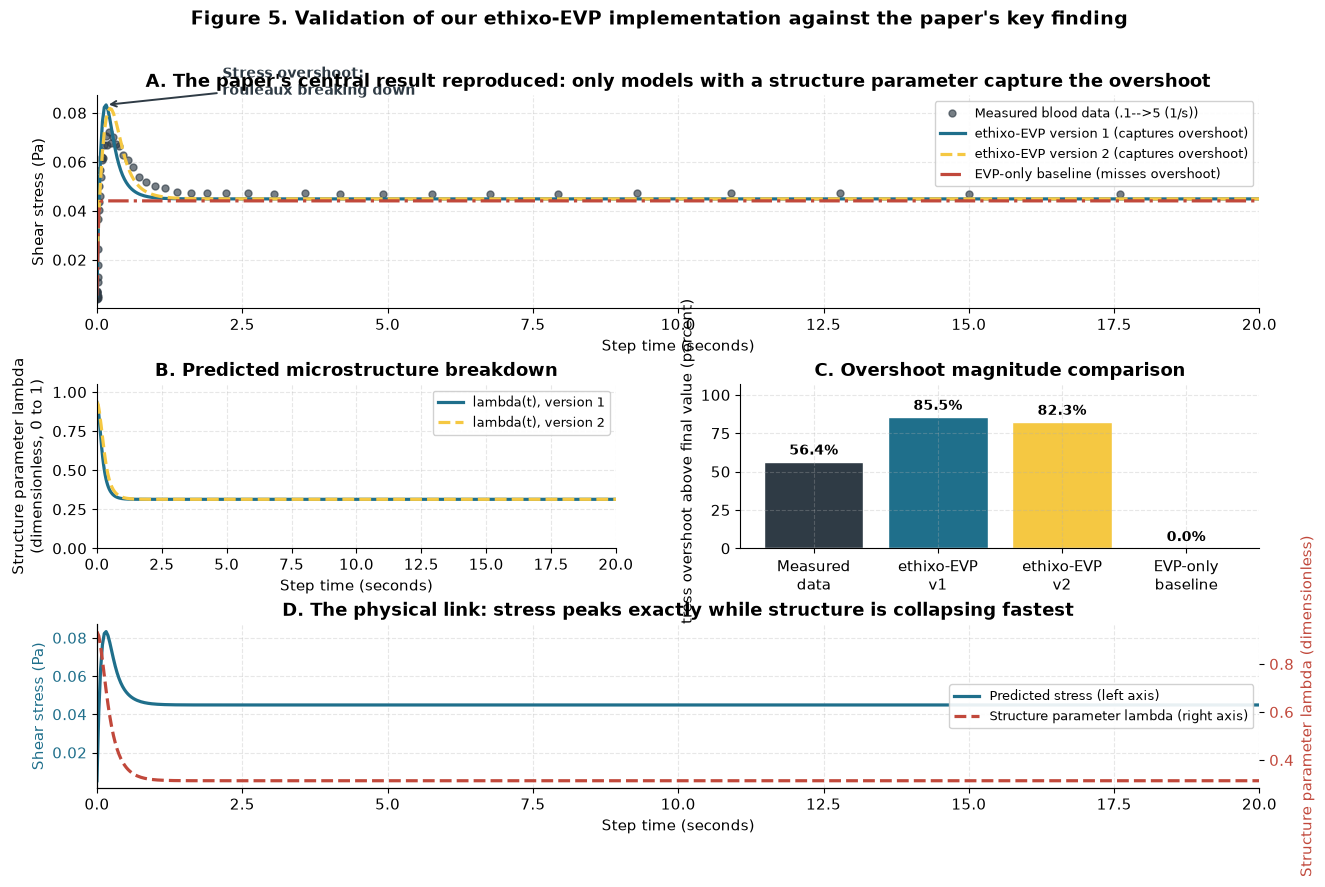


Why panel D matters for this project
--------------------------------------------------------------------------
The stress peak coincides with the steepest fall in lambda. This is the physical
event our wavelet methods must detect. Because lambda(t) is computed here without
any frequency-domain mathematics, it serves as an independent ground-truth signal
for validating whatever the wavelet transforms extract from the same raw data.


In [21]:
# Visualising the overshoot result, which is the paper's headline figure

figure = plt.figure(figsize=(15, 9))
grid = gridspec.GridSpec(3, 2, height_ratios=[1.3, 1.0, 1.0], hspace=0.42, wspace=0.24)

# Panel A, spanning the full width: measured data against all three model predictions
axis_a = figure.add_subplot(grid[0, :])
axis_a.plot(primary_raw_time, primary_raw_stress,
            "o", markersize=5, color=COLOUR_TEXT_DARK, alpha=0.65,
            label="Measured blood data (" + str(primary_experiment_row["condition_label"]) + ")")
axis_a.plot(model_time_v1, model_stress_v1,
            color=COLOUR_DEEP_BLUE, linewidth=2.3,
            label="ethixo-EVP version 1 (captures overshoot)")
axis_a.plot(model_time_v2, model_stress_v2,
            color=COLOUR_YELLOW, linewidth=2.3, linestyle="--",
            label="ethixo-EVP version 2 (captures overshoot)")
axis_a.plot(model_time_evp, model_stress_evp,
            color=COLOUR_RED_ACCENT, linewidth=2.3, linestyle="-.",
            label="EVP-only baseline (misses overshoot)")

peak_index_v1 = int(np.argmax(model_stress_v1))
axis_a.annotate(
    "Stress overshoot:\nrouleaux breaking down",
    xy=(model_time_v1[peak_index_v1], model_stress_v1[peak_index_v1]),
    xytext=(model_time_v1[peak_index_v1] + 2.0, model_stress_v1[peak_index_v1] * 1.05),
    arrowprops=dict(arrowstyle="->", color=COLOUR_TEXT_DARK, linewidth=1.4),
    fontsize=10, fontweight="bold", color=COLOUR_TEXT_DARK
)

axis_a.set_xlabel("Step time (seconds)")
axis_a.set_ylabel("Shear stress (Pa)")
axis_a.set_title("A. The paper's central result reproduced: only models with a structure parameter capture the overshoot")
axis_a.set_xlim(0, min(20, simulation_time_span[1]))
axis_a.legend(fontsize=9, loc="upper right")

# Panel B: structure parameter evolution for both versions
axis_b = figure.add_subplot(grid[1, 0])
axis_b.plot(model_time_v1, model_lambda_v1,
            color=COLOUR_DEEP_BLUE, linewidth=2.3, label="lambda(t), version 1")
axis_b.plot(model_time_v2, model_lambda_v2,
            color=COLOUR_YELLOW, linewidth=2.3, linestyle="--", label="lambda(t), version 2")
axis_b.set_xlabel("Step time (seconds)")
axis_b.set_ylabel("Structure parameter lambda\n(dimensionless, 0 to 1)")
axis_b.set_title("B. Predicted microstructure breakdown")
axis_b.set_xlim(0, min(20, simulation_time_span[1]))
axis_b.set_ylim(0, 1.05)
axis_b.legend(fontsize=9)

# Panel C: overshoot magnitude comparison
axis_c = figure.add_subplot(grid[1, 1])
overshoot_labels = ["Measured\ndata", "ethixo-EVP\nv1", "ethixo-EVP\nv2", "EVP-only\nbaseline"]
overshoot_values = [measured_overshoot, overshoot_model_v1, overshoot_model_v2, overshoot_model_evp]
overshoot_colours = [COLOUR_TEXT_DARK, COLOUR_DEEP_BLUE, COLOUR_YELLOW, COLOUR_RED_ACCENT]

bars = axis_c.bar(overshoot_labels, overshoot_values,
                  color=overshoot_colours, edgecolor="white", linewidth=1.0)
for bar_object, value in zip(bars, overshoot_values):
    axis_c.text(bar_object.get_x() + bar_object.get_width() / 2,
                value + max(overshoot_values) * 0.03,
                str(round(value, 1)) + "%", ha="center", va="bottom",
                fontweight="bold", fontsize=10)
axis_c.set_ylabel("Stress overshoot above final value (percent)")
axis_c.set_title("C. Overshoot magnitude comparison")
axis_c.set_ylim(0, max(overshoot_values) * 1.25)

# Panel D: relationship between stress and structure
axis_d = figure.add_subplot(grid[2, :])
twin_axis = axis_d.twinx()

stress_line, = axis_d.plot(model_time_v1, model_stress_v1,
                           color=COLOUR_DEEP_BLUE, linewidth=2.3,
                           label="Predicted stress (left axis)")
lambda_line, = twin_axis.plot(model_time_v1, model_lambda_v1,
                              color=COLOUR_RED_ACCENT, linewidth=2.3, linestyle="--",
                              label="Structure parameter lambda (right axis)")

axis_d.set_xlabel("Step time (seconds)")
axis_d.set_ylabel("Shear stress (Pa)", color=COLOUR_DEEP_BLUE)
twin_axis.set_ylabel("Structure parameter lambda (dimensionless)", color=COLOUR_RED_ACCENT)
axis_d.tick_params(axis="y", labelcolor=COLOUR_DEEP_BLUE)
twin_axis.tick_params(axis="y", labelcolor=COLOUR_RED_ACCENT)
twin_axis.grid(False)
axis_d.set_xlim(0, min(20, simulation_time_span[1]))
axis_d.set_title("D. The physical link: stress peaks exactly while structure is collapsing fastest")
axis_d.legend(handles=[stress_line, lambda_line], fontsize=9, loc="center right")

figure.suptitle("Figure 5. Validation of our ethixo-EVP implementation against the paper's key finding",
                fontsize=14, fontweight="bold", y=0.975)
plt.show()

print()
print("Why panel D matters for this project")
print("-" * 74)
print("The stress peak coincides with the steepest fall in lambda. This is the physical")
print("event our wavelet methods must detect. Because lambda(t) is computed here without")
print("any frequency-domain mathematics, it serves as an independent ground-truth signal")
print("for validating whatever the wavelet transforms extract from the same raw data.")

In [22]:
# Generating the lambda(t) reference signal on exactly the same time grid as our
# preprocessed signal, so it can be compared point by point with wavelet features later.

lambda_interpolator = interp1d(
    model_time_v1, model_lambda_v1,
    kind="linear", bounds_error=False,
    fill_value=(model_lambda_v1[0], model_lambda_v1[-1])
)

LAMBDA_REFERENCE_SIGNAL = lambda_interpolator(primary_preprocessing["processed_time"])

# Also computing the rate of structural change, which marks the transition most sharply
LAMBDA_RATE_OF_CHANGE = np.gradient(
    LAMBDA_REFERENCE_SIGNAL,
    primary_preprocessing["processed_time"]
)

# The ground-truth transition time is where structure changes fastest
GROUND_TRUTH_TRANSITION_INDEX = int(np.argmax(np.abs(LAMBDA_RATE_OF_CHANGE)))
GROUND_TRUTH_TRANSITION_TIME  = float(
    primary_preprocessing["processed_time"][GROUND_TRUTH_TRANSITION_INDEX]
)

# The measured stress peak gives a second, purely experimental transition reference
MEASURED_PEAK_INDEX = int(np.argmax(primary_preprocessing["uniform_value"]))
MEASURED_PEAK_TIME  = float(primary_preprocessing["processed_time"][MEASURED_PEAK_INDEX])

print("GROUND-TRUTH REFERENCE SIGNALS PREPARED")
print("=" * 70)
print("Reference signal length            :", len(LAMBDA_REFERENCE_SIGNAL), "samples")
print("Lambda range across the experiment :",
      round(float(LAMBDA_REFERENCE_SIGNAL.min()), 4), "to",
      round(float(LAMBDA_REFERENCE_SIGNAL.max()), 4))
print()
print("Transition event references, used later for timing accuracy")
print("-" * 70)
print("From model, fastest structural change :", round(GROUND_TRUTH_TRANSITION_TIME, 4), "seconds")
print("From data, measured stress peak       :", round(MEASURED_PEAK_TIME, 4), "seconds")
print()
print("These two references are independent of each other. One comes from the physical")
print("model, the other directly from the measurement. Both will be used to score how")
print("accurately each time-frequency method locates the structural transition.")

GROUND-TRUTH REFERENCE SIGNALS PREPARED
Reference signal length            : 3150 samples
Lambda range across the experiment : 0.3138 to 0.9344

Transition event references, used later for timing accuracy
----------------------------------------------------------------------
From model, fastest structural change : 0.121 seconds
From data, measured stress peak       : 0.201 seconds

These two references are independent of each other. One comes from the physical
model, the other directly from the measurement. Both will be used to score how
accurately each time-frequency method locates the structural transition.


---
# Section 4. Time-Frequency Analysis Methods

This section implements every method in the project scope behind a single common interface, so they can be compared fairly on identical input.

## 4.1 Methods implemented

| Family | Variants | Library |
|---|---|---|
| Continuous Wavelet Transform | Morlet, Paul, DOG, Shannon, Morse | PyWavelets, custom Paul, ssqueezepy for Morse |
| Discrete Wavelet Transform | db4, sym4, coif1, bior2.2, rbio2.2 | PyWavelets |
| Short-Time Fourier Transform | Hanning window, Gaussian window | SciPy |
| Fast CWT | fCWT | fcwt |

## 4.2 A note on the Paul wavelet

The Paul wavelet is not available in PyWavelets or any other maintained package we could find. It has a clean closed-form definition in the frequency domain, so it is implemented directly below following Torrence and Compo (1998), which is the standard reference for it.

## 4.3 What each family gives us

| Family | Time-frequency resolution | Best suited to |
|---|---|---|
| CWT | Continuous scales, good frequency resolution at low frequency and good time resolution at high frequency | Locating transient events precisely |
| DWT | Dyadic scales only, fast and non-redundant | Denoising and multiresolution energy decomposition |
| STFT | Fixed resolution set by window length, uniform across all frequencies | Steady oscillatory signals such as LAOS |
| fCWT | Same output as CWT but computed much faster | Large datasets where CWT would be too slow |

In [23]:
def compute_paul_wavelet_cwt(signal_values, scales, sampling_period, paul_order=4):
    """
    Computing the Continuous Wavelet Transform using the Paul wavelet.

    The Paul wavelet is not provided by PyWavelets, so it is implemented here
    directly in the frequency domain following Torrence and Compo (1998).

    The Paul mother wavelet in the frequency domain is:
        psi_hat(s * omega) = A * (s * omega)^m * exp(-s * omega)   for omega > 0
                           = 0                                     for omega <= 0

    where m is the wavelet order and A is a normalisation constant.
    """
    signal_length = len(signal_values)

    # Removing the mean before transforming, standard practice for CWT
    centred_signal = signal_values - np.mean(signal_values)

    # Transforming the signal into the frequency domain
    signal_spectrum = np.fft.fft(centred_signal)

    # Building the angular frequency axis
    angular_frequencies = np.fft.fftfreq(signal_length, d=sampling_period) * 2.0 * np.pi

    # Normalisation constant for the Paul wavelet
    order_factorial_ratio = 1.0
    for factor_index in range(2, 2 * paul_order):
        order_factorial_ratio = order_factorial_ratio * factor_index
    normalisation = (2.0 ** paul_order) / np.sqrt(paul_order * order_factorial_ratio)

    coefficient_matrix = np.zeros((len(scales), signal_length), dtype=complex)

    for scale_index, scale_value in enumerate(scales):
        scaled_frequencies = scale_value * angular_frequencies

        # The Paul wavelet is one sided, defined only for positive frequencies
        positive_frequency_mask = scaled_frequencies > 0

        wavelet_spectrum = np.zeros(signal_length, dtype=complex)
        wavelet_spectrum[positive_frequency_mask] = (
            normalisation
            * (scaled_frequencies[positive_frequency_mask] ** paul_order)
            * np.exp(-scaled_frequencies[positive_frequency_mask])
        )

        # Applying the energy normalisation across scales
        energy_normalisation = np.sqrt(2.0 * np.pi * scale_value / sampling_period)
        wavelet_spectrum = wavelet_spectrum * energy_normalisation

        # Convolving in the frequency domain, then returning to the time domain
        coefficient_matrix[scale_index, :] = np.fft.ifft(signal_spectrum * wavelet_spectrum)

    # Converting scales to their equivalent Fourier frequencies for the Paul wavelet.
    # The scales are expressed in samples, so the sampling period must be included to
    # obtain frequencies in Hz. Omitting it would shift the whole frequency axis.
    fourier_factor = 4.0 * np.pi / (2.0 * paul_order + 1.0)
    equivalent_frequencies = 1.0 / (fourier_factor * scales * sampling_period)

    return coefficient_matrix, equivalent_frequencies


print("Function compute_paul_wavelet_cwt defined.")
print("Paul wavelet implemented from first principles, following Torrence and Compo (1998).")

Function compute_paul_wavelet_cwt defined.
Paul wavelet implemented from first principles, following Torrence and Compo (1998).


In [24]:
def run_continuous_wavelet_transform(signal_values,
                                     sampling_frequency,
                                     wavelet_name,
                                     number_of_scales=64):
    """
    Running a Continuous Wavelet Transform with the requested wavelet family.

    Providing a single interface across PyWavelets wavelets, the custom Paul
    implementation, and the ssqueezepy Morse wavelet, so that all CWT variants
    can be called identically.

    Returning a dictionary with the coefficient matrix, the frequency axis,
    and metadata describing what was computed.
    """
    sampling_period = 1.0 / sampling_frequency
    signal_length = len(signal_values)

    # Building a logarithmic scale range appropriate to the signal length
    minimum_scale = 2.0
    maximum_scale = max(4.0, signal_length / 8.0)
    scales = np.logspace(np.log10(minimum_scale), np.log10(maximum_scale), number_of_scales)

    result_record = {
        "wavelet_name" : wavelet_name,
        "success"      : False,
        "message"      : "",
    }

    try:
        if wavelet_name == "Morlet":
            coefficients, frequencies = pywt.cwt(
                signal_values, scales, "morl", sampling_period=sampling_period
            )
            coefficients = np.asarray(coefficients)

        elif wavelet_name == "Paul":
            coefficients, frequencies = compute_paul_wavelet_cwt(
                signal_values, scales, sampling_period, paul_order=4
            )

        elif wavelet_name == "DOG":
            # DOG is the Derivative of Gaussian family.
            # gaus4 is the fourth derivative of a Gaussian.
            coefficients, frequencies = pywt.cwt(
                signal_values, scales, "gaus4", sampling_period=sampling_period
            )
            coefficients = np.asarray(coefficients)

        elif wavelet_name == "Shannon":
            coefficients, frequencies = pywt.cwt(
                signal_values, scales, "shan1.0-1.0", sampling_period=sampling_period
            )
            coefficients = np.asarray(coefficients)

        elif wavelet_name == "Morse":
            if not HAS_SSQ:
                result_record["message"] = "ssqueezepy not installed, Morse wavelet unavailable"
                return result_record
            coefficient_matrix, ssq_scales = ssq_cwt(
                signal_values.astype(np.float64), wavelet="gmw", nv=8
            )
            coefficients = np.asarray(coefficient_matrix)
            # Converting ssqueezepy scales into approximate frequencies
            ssq_scales = np.asarray(ssq_scales).ravel()
            frequencies = sampling_frequency / (2.0 * np.pi * ssq_scales)

        else:
            result_record["message"] = "Unrecognised wavelet name: " + str(wavelet_name)
            return result_record

        magnitude = np.abs(coefficients)

        result_record["success"]      = True
        result_record["coefficients"] = coefficients
        result_record["magnitude"]    = magnitude
        result_record["frequencies"]  = np.asarray(frequencies).ravel()
        result_record["scales"]       = scales
        result_record["method_family"] = "CWT"
        result_record["message"]      = "Computed successfully"

    except Exception as exception_message:
        result_record["message"] = "Failed: " + str(exception_message)

    return result_record


print("Function run_continuous_wavelet_transform defined.")
print("Supported CWT wavelets: Morlet, Paul, DOG, Shannon, Morse")

Function run_continuous_wavelet_transform defined.
Supported CWT wavelets: Morlet, Paul, DOG, Shannon, Morse


In [25]:
def run_discrete_wavelet_transform(signal_values,
                                   sampling_frequency,
                                   wavelet_name,
                                   decomposition_level=None):
    """
    Running a multilevel Discrete Wavelet Transform decomposition.

    Unlike the CWT, the DWT produces a small number of dyadic frequency bands
    rather than a continuous scalogram. Each level corresponds to a frequency
    band spanning one octave.

    Returning the detail and approximation coefficients together with the
    frequency band each level represents.
    """
    result_record = {
        "wavelet_name" : wavelet_name,
        "success"      : False,
        "message"      : "",
    }

    try:
        wavelet_object = pywt.Wavelet(wavelet_name)

        maximum_level = pywt.dwt_max_level(len(signal_values), wavelet_object.dec_len)
        if decomposition_level is None:
            decomposition_level = min(6, maximum_level)
        decomposition_level = max(1, min(decomposition_level, maximum_level))

        # Performing the multilevel decomposition
        coefficient_list = pywt.wavedec(signal_values, wavelet_object, level=decomposition_level)

        approximation_coefficients = coefficient_list[0]
        detail_coefficient_list    = coefficient_list[1:]

        # Computing the nominal frequency band for each detail level
        band_information = []
        for level_number in range(1, decomposition_level + 1):
            upper_frequency = sampling_frequency / (2.0 ** level_number)
            lower_frequency = sampling_frequency / (2.0 ** (level_number + 1))
            band_information.append({
                "level"           : level_number,
                "lower_frequency" : lower_frequency,
                "upper_frequency" : upper_frequency,
            })

        # Computing the energy held in each level, a standard multiresolution feature
        level_energies = []
        for detail_coefficients in detail_coefficient_list:
            level_energies.append(float(np.sum(np.asarray(detail_coefficients) ** 2)))
        approximation_energy = float(np.sum(np.asarray(approximation_coefficients) ** 2))

        total_energy = sum(level_energies) + approximation_energy
        if total_energy > 0:
            relative_energies = [energy / total_energy for energy in level_energies]
        else:
            relative_energies = [0.0 for _ in level_energies]

        # Reconstructing the signal to measure how faithfully the DWT represents it
        reconstructed_signal = pywt.waverec(coefficient_list, wavelet_object)
        reconstructed_signal = reconstructed_signal[:len(signal_values)]

        result_record["success"]                   = True
        result_record["approximation_coefficients"] = approximation_coefficients
        result_record["detail_coefficients"]        = detail_coefficient_list
        result_record["decomposition_level"]        = decomposition_level
        result_record["band_information"]           = band_information
        result_record["level_energies"]             = level_energies
        result_record["relative_energies"]          = relative_energies
        result_record["approximation_energy"]       = approximation_energy
        result_record["reconstructed_signal"]       = reconstructed_signal
        result_record["method_family"]              = "DWT"
        result_record["message"]                    = "Computed successfully"

    except Exception as exception_message:
        result_record["message"] = "Failed: " + str(exception_message)

    return result_record


print("Function run_discrete_wavelet_transform defined.")
print("Supported DWT wavelets: db4, sym4, coif1, bior2.2, rbio2.2")

Function run_discrete_wavelet_transform defined.
Supported DWT wavelets: db4, sym4, coif1, bior2.2, rbio2.2


In [26]:
def run_short_time_fourier_transform(signal_values,
                                     sampling_frequency,
                                     window_name,
                                     segment_length=None,
                                     overlap_fraction=0.85):
    """
    Running a Short-Time Fourier Transform with the requested window function.

    The STFT is the conventional baseline this project is testing wavelets against.
    Its defining limitation is that time and frequency resolution are fixed by the
    window length and stay uniform across all frequencies, unlike a wavelet transform.

    Returning the spectrogram magnitude together with its time and frequency axes.
    """
    result_record = {
        "window_name" : window_name,
        "success"     : False,
        "message"     : "",
    }

    try:
        signal_length = len(signal_values)

        if segment_length is None:
            # Choosing a segment length that balances time and frequency resolution
            segment_length = max(16, min(256, signal_length // 8))

        segment_length = int(min(segment_length, signal_length))
        overlap_samples = int(segment_length * overlap_fraction)
        overlap_samples = min(overlap_samples, segment_length - 1)

        if window_name == "Hanning":
            window_array = sp_signal.get_window("hann", segment_length)
        elif window_name == "Gaussian":
            # Standard deviation set to one seventh of the segment, a common choice
            window_array = sp_signal.windows.gaussian(segment_length, std=segment_length / 7.0)
        else:
            result_record["message"] = "Unrecognised window name: " + str(window_name)
            return result_record

        frequency_axis, time_axis, complex_spectrogram = sp_signal.stft(
            signal_values,
            fs=sampling_frequency,
            window=window_array,
            nperseg=segment_length,
            noverlap=overlap_samples,
            return_onesided=True,
        )

        result_record["success"]        = True
        result_record["coefficients"]   = complex_spectrogram
        result_record["magnitude"]      = np.abs(complex_spectrogram)
        result_record["frequencies"]    = frequency_axis
        result_record["time_axis"]      = time_axis
        result_record["segment_length"] = segment_length
        result_record["method_family"]  = "STFT"
        result_record["message"]        = "Computed successfully"

    except Exception as exception_message:
        result_record["message"] = "Failed: " + str(exception_message)

    return result_record


print("Function run_short_time_fourier_transform defined.")
print("Supported STFT windows: Hanning, Gaussian")

Function run_short_time_fourier_transform defined.
Supported STFT windows: Hanning, Gaussian


In [27]:
def run_fast_continuous_wavelet_transform(signal_values,
                                          sampling_frequency,
                                          minimum_frequency=None,
                                          maximum_frequency=None,
                                          number_of_frequencies=64):
    """
    Running the Fast Continuous Wavelet Transform using the fcwt library.

    fCWT computes a Morlet CWT using an optimised FFT based algorithm. It produces
    equivalent output to a standard CWT but is substantially faster, which matters
    when scaling this pipeline across many experiments.

    Returning the same structure as the other CWT functions so it can be compared
    on identical terms.
    """
    result_record = {
        "wavelet_name" : "fCWT",
        "success"      : False,
        "message"      : "",
    }

    if not HAS_FCWT:
        result_record["message"] = "fcwt library not installed"
        return result_record

    try:
        signal_length = len(signal_values)

        if minimum_frequency is None:
            # Lowest frequency resolvable given the recording length
            minimum_frequency = max(0.01, 4.0 * sampling_frequency / signal_length)
        if maximum_frequency is None:
            # Nyquist limit, with a small safety margin
            maximum_frequency = sampling_frequency / 2.2

        signal_as_float32 = np.asarray(signal_values, dtype=np.float32)

        frequency_axis, coefficient_matrix = fcwt.cwt(
            signal_as_float32,
            int(sampling_frequency),
            float(minimum_frequency),
            float(maximum_frequency),
            int(number_of_frequencies),
        )

        result_record["success"]       = True
        result_record["coefficients"]  = coefficient_matrix
        result_record["magnitude"]     = np.abs(coefficient_matrix)
        result_record["frequencies"]   = np.asarray(frequency_axis).ravel()
        result_record["method_family"] = "fCWT"
        result_record["message"]       = "Computed successfully"

    except Exception as exception_message:
        result_record["message"] = "Failed: " + str(exception_message)

    return result_record


print("Function run_fast_continuous_wavelet_transform defined.")

Function run_fast_continuous_wavelet_transform defined.


## 4.4 Running every method on the primary signal

All methods now receive exactly the same preprocessed input, so any difference in their output comes from the method itself rather than from differing preparation.

In [28]:
# Defining the complete method registry for this project

CWT_WAVELET_NAMES  = ["Morlet", "Paul", "DOG", "Shannon", "Morse"]
DWT_WAVELET_NAMES  = ["db4", "sym4", "coif1", "bior2.2", "rbio2.2"]
STFT_WINDOW_NAMES  = ["Hanning", "Gaussian"]

# The signal every method will analyse
analysis_signal    = primary_preprocessing["processed_value"]
analysis_time      = primary_preprocessing["processed_time"]
analysis_frequency = primary_preprocessing["sampling_frequency_hz"]

print("Input signal for all methods")
print("=" * 70)
print("Sample count       :", len(analysis_signal))
print("Sampling frequency :", analysis_frequency, "Hz")
print("Duration           :", round(analysis_time[-1] - analysis_time[0], 3), "seconds")
print()

# Running all methods and collecting the results in one dictionary
method_results = {}

print("Running CWT methods")
print("-" * 70)
for wavelet_name in CWT_WAVELET_NAMES:
    method_key = "CWT-" + wavelet_name
    method_results[method_key] = run_continuous_wavelet_transform(
        analysis_signal, analysis_frequency, wavelet_name
    )
    status_text = "OK" if method_results[method_key]["success"] else "SKIPPED"
    print("  " + method_key.ljust(16) + status_text.ljust(10) + method_results[method_key]["message"])

print()
print("Running DWT methods")
print("-" * 70)
for wavelet_name in DWT_WAVELET_NAMES:
    method_key = "DWT-" + wavelet_name
    method_results[method_key] = run_discrete_wavelet_transform(
        analysis_signal, analysis_frequency, wavelet_name
    )
    status_text = "OK" if method_results[method_key]["success"] else "SKIPPED"
    print("  " + method_key.ljust(16) + status_text.ljust(10) + method_results[method_key]["message"])

print()
print("Running STFT methods")
print("-" * 70)
for window_name in STFT_WINDOW_NAMES:
    method_key = "STFT-" + window_name
    method_results[method_key] = run_short_time_fourier_transform(
        analysis_signal, analysis_frequency, window_name
    )
    status_text = "OK" if method_results[method_key]["success"] else "SKIPPED"
    print("  " + method_key.ljust(16) + status_text.ljust(10) + method_results[method_key]["message"])

print()
print("Running fCWT")
print("-" * 70)
method_results["fCWT"] = run_fast_continuous_wavelet_transform(
    analysis_signal, analysis_frequency
)
status_text = "OK" if method_results["fCWT"]["success"] else "SKIPPED"
print("  " + "fCWT".ljust(16) + status_text.ljust(10) + method_results["fCWT"]["message"])

print()
successful_methods = [name for name, record in method_results.items() if record["success"]]
print("Methods that ran successfully:", len(successful_methods), "of", len(method_results))

Input signal for all methods
Sample count       : 3150
Sampling frequency : 50.0 Hz
Duration           : 62.98 seconds

Running CWT methods
----------------------------------------------------------------------
  CWT-Morlet      OK        Computed successfully
  CWT-Paul        OK        Computed successfully
  CWT-DOG         OK        Computed successfully
  CWT-Shannon     OK        Computed successfully
  CWT-Morse       OK        Computed successfully

Running DWT methods
----------------------------------------------------------------------
  DWT-db4         OK        Computed successfully
  DWT-sym4        OK        Computed successfully
  DWT-coif1       OK        Computed successfully
  DWT-bior2.2     OK        Computed successfully
  DWT-rbio2.2     OK        Computed successfully

Running STFT methods
----------------------------------------------------------------------
  STFT-Hanning    OK        Computed successfully
  STFT-Gaussian   OK        Computed successfully

Run

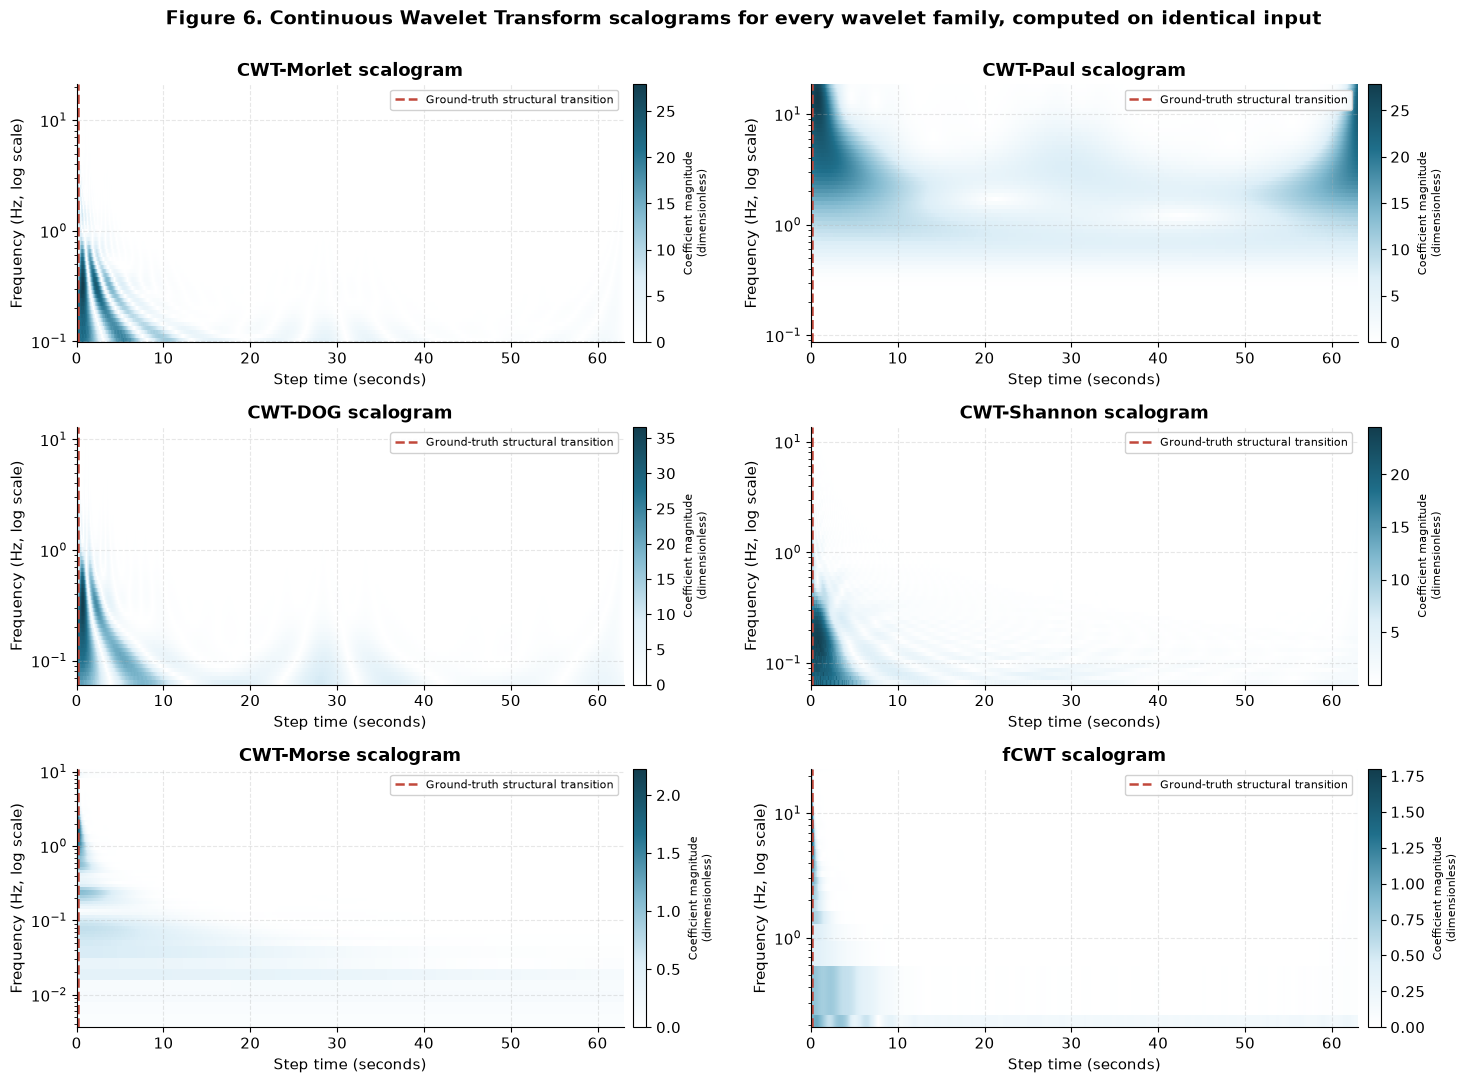


How to read these figures
--------------------------------------------------------------------------
Brighter regions indicate more signal energy at that frequency and time.
A method that resolves the structural transition well should show a clear, sharply
localised change in energy at the red dashed line. A method that smears energy
broadly in time is resolving the transition poorly.


In [29]:
# Visualising the CWT scalograms side by side.
# A scalogram shows how much energy sits at each frequency at each moment in time.

available_cwt_methods = [
    "CWT-" + name for name in CWT_WAVELET_NAMES
    if method_results.get("CWT-" + name, {}).get("success", False)
]
if method_results.get("fCWT", {}).get("success", False):
    available_cwt_methods.append("fCWT")

number_of_panels = len(available_cwt_methods)
panel_rows = int(np.ceil(number_of_panels / 2))

figure, axes = plt.subplots(panel_rows, 2, figsize=(15, 3.6 * panel_rows))
axes = np.atleast_1d(axes).ravel()

for panel_index, method_key in enumerate(available_cwt_methods):
    axis_object = axes[panel_index]
    record = method_results[method_key]

    magnitude_matrix = record["magnitude"]
    frequency_values = record["frequencies"]

    # Keeping only physically meaningful positive frequencies
    valid_frequency_mask = (frequency_values > 0) & np.isfinite(frequency_values)
    magnitude_matrix = magnitude_matrix[valid_frequency_mask, :]
    frequency_values = frequency_values[valid_frequency_mask]

    # Sorting by frequency so the vertical axis increases upward
    frequency_sort_order = np.argsort(frequency_values)
    frequency_values = frequency_values[frequency_sort_order]
    magnitude_matrix = magnitude_matrix[frequency_sort_order, :]

    time_extent_start = analysis_time[0]
    time_extent_end   = analysis_time[-1]

    image = axis_object.pcolormesh(
        np.linspace(time_extent_start, time_extent_end, magnitude_matrix.shape[1]),
        frequency_values,
        magnitude_matrix,
        shading="auto",
        cmap=SCALOGRAM_COLORMAP,
    )

    axis_object.set_yscale("log")
    axis_object.set_xlabel("Step time (seconds)")
    axis_object.set_ylabel("Frequency (Hz, log scale)")
    axis_object.set_title(method_key + " scalogram")

    # Marking the ground-truth transition time on every panel
    axis_object.axvline(
        GROUND_TRUTH_TRANSITION_TIME,
        color=COLOUR_RED_ACCENT, linestyle="--", linewidth=1.8,
        label="Ground-truth structural transition"
    )
    axis_object.legend(fontsize=8, loc="upper right")

    colour_bar = figure.colorbar(image, ax=axis_object, pad=0.015)
    colour_bar.set_label("Coefficient magnitude\n(dimensionless)", fontsize=8)

# Hiding any unused panels
for unused_index in range(number_of_panels, len(axes)):
    axes[unused_index].axis("off")

figure.suptitle(
    "Figure 6. Continuous Wavelet Transform scalograms for every wavelet family, computed on identical input",
    fontsize=14, fontweight="bold", y=1.0
)
plt.tight_layout()
plt.show()

print()
print("How to read these figures")
print("-" * 74)
print("Brighter regions indicate more signal energy at that frequency and time.")
print("A method that resolves the structural transition well should show a clear, sharply")
print("localised change in energy at the red dashed line. A method that smears energy")
print("broadly in time is resolving the transition poorly.")

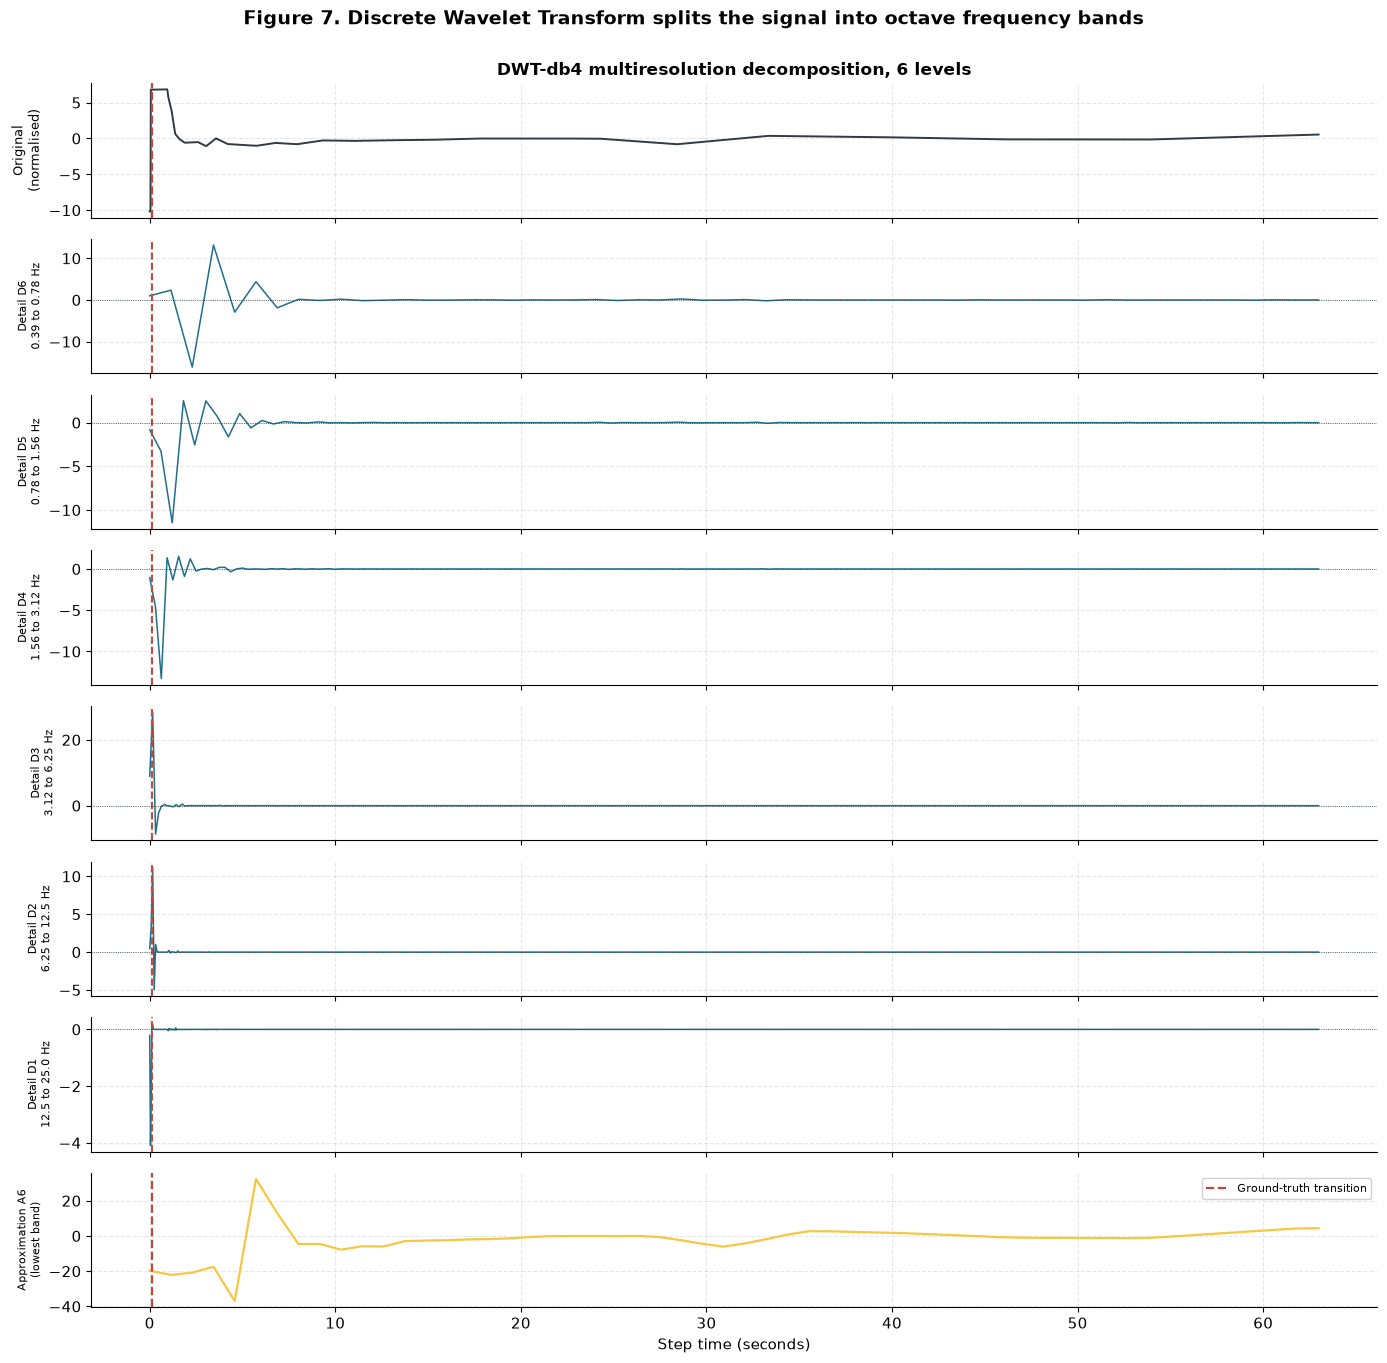


How to read this figure
--------------------------------------------------------------------------
Each detail level holds one octave of frequency content. Reading downward, the
bands move from high frequency to low frequency. A structural transition typically
appears as a burst of energy in the mid-level details at the moment it occurs.


In [30]:
# Visualising the DWT multiresolution decomposition.
# Unlike the CWT, this splits the signal into a few discrete octave bands.

available_dwt_methods = [
    "DWT-" + name for name in DWT_WAVELET_NAMES
    if method_results.get("DWT-" + name, {}).get("success", False)
]

# Using the first available DWT wavelet to show the decomposition in detail
reference_dwt_key = available_dwt_methods[0]
reference_dwt = method_results[reference_dwt_key]

number_of_levels = reference_dwt["decomposition_level"]

figure, axes = plt.subplots(number_of_levels + 2, 1,
                            figsize=(14, 1.7 * (number_of_levels + 2)),
                            sharex=False)

# Top panel: the original signal
axes[0].plot(analysis_time, analysis_signal, color=COLOUR_TEXT_DARK, linewidth=1.4)
axes[0].axvline(GROUND_TRUTH_TRANSITION_TIME, color=COLOUR_RED_ACCENT,
                linestyle="--", linewidth=1.6)
axes[0].set_ylabel("Original\n(normalised)", fontsize=9)
axes[0].set_title(reference_dwt_key + " multiresolution decomposition, "
                  + str(number_of_levels) + " levels", fontsize=12, fontweight="bold")
axes[0].tick_params(labelbottom=False)

# Middle panels: detail coefficients at each level, from finest to coarsest
for level_index, detail_coefficients in enumerate(reference_dwt["detail_coefficients"]):
    axis_object = axes[level_index + 1]

    # Detail coefficients are downsampled, so a matching time axis is built for them
    coefficient_time_axis = np.linspace(
        analysis_time[0], analysis_time[-1], len(detail_coefficients)
    )

    band = reference_dwt["band_information"][number_of_levels - 1 - level_index]

    axis_object.plot(coefficient_time_axis, detail_coefficients,
                     color=COLOUR_DEEP_BLUE, linewidth=1.1)
    axis_object.axvline(GROUND_TRUTH_TRANSITION_TIME, color=COLOUR_RED_ACCENT,
                        linestyle="--", linewidth=1.4)
    axis_object.axhline(0, color=COLOUR_TEXT_DARK, linewidth=0.6, linestyle=":")
    axis_object.set_ylabel(
        "Detail D" + str(number_of_levels - level_index) + "\n"
        + str(round(band["lower_frequency"], 2)) + " to "
        + str(round(band["upper_frequency"], 2)) + " Hz",
        fontsize=8
    )
    axis_object.tick_params(labelbottom=False)

# Bottom panel: the approximation, holding the lowest frequency content
approximation_time_axis = np.linspace(
    analysis_time[0], analysis_time[-1], len(reference_dwt["approximation_coefficients"])
)
axes[-1].plot(approximation_time_axis, reference_dwt["approximation_coefficients"],
              color=COLOUR_YELLOW, linewidth=1.6)
axes[-1].axvline(GROUND_TRUTH_TRANSITION_TIME, color=COLOUR_RED_ACCENT,
                 linestyle="--", linewidth=1.6, label="Ground-truth transition")
axes[-1].set_ylabel("Approximation A" + str(number_of_levels) + "\n(lowest band)", fontsize=8)
axes[-1].set_xlabel("Step time (seconds)")
axes[-1].legend(fontsize=8, loc="upper right")

figure.suptitle("Figure 7. Discrete Wavelet Transform splits the signal into octave frequency bands",
                fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

print()
print("How to read this figure")
print("-" * 74)
print("Each detail level holds one octave of frequency content. Reading downward, the")
print("bands move from high frequency to low frequency. A structural transition typically")
print("appears as a burst of energy in the mid-level details at the moment it occurs.")

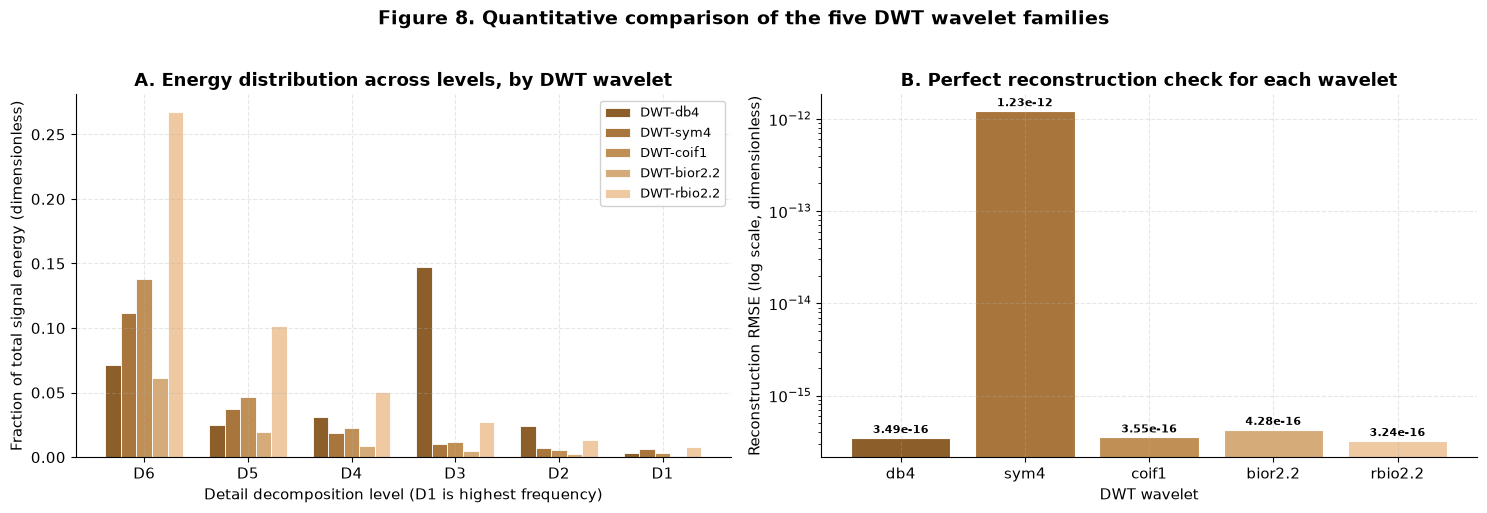


Interpretation
--------------------------------------------------------------------------
Panel B verifies that each DWT is numerically sound. All five wavelets are
orthogonal or biorthogonal, so reconstruction error should sit near machine
precision. Any wavelet showing a materially larger error would indicate a problem.


In [31]:
# Comparing how DWT wavelets distribute signal energy across frequency bands.
# This is a direct, quantitative comparison of the five DWT variants.

figure, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: relative energy per decomposition level, all wavelets overlaid
axis_a = axes[0]
bar_width = 0.15

for wavelet_index, method_key in enumerate(available_dwt_methods):
    record = method_results[method_key]
    relative_energies = record["relative_energies"]
    level_positions = np.arange(len(relative_energies))

    axis_a.bar(
        level_positions + wavelet_index * bar_width,
        relative_energies,
        width=bar_width,
        label=method_key,
        color=METHOD_COLOURS.get(method_key, COLOUR_DEEP_BLUE),
        edgecolor="white", linewidth=0.6,
    )

level_labels = ["D" + str(len(reference_dwt["detail_coefficients"]) - i)
                for i in range(len(reference_dwt["detail_coefficients"]))]
axis_a.set_xticks(np.arange(len(level_labels)) + bar_width * (len(available_dwt_methods) - 1) / 2)
axis_a.set_xticklabels(level_labels)
axis_a.set_xlabel("Detail decomposition level (D1 is highest frequency)")
axis_a.set_ylabel("Fraction of total signal energy (dimensionless)")
axis_a.set_title("A. Energy distribution across levels, by DWT wavelet")
axis_a.legend(fontsize=9)

# Panel B: reconstruction error for each wavelet
axis_b = axes[1]
reconstruction_errors = []
reconstruction_labels = []

for method_key in available_dwt_methods:
    record = method_results[method_key]
    reconstructed = record["reconstructed_signal"]
    error_value = float(np.sqrt(np.mean((analysis_signal - reconstructed) ** 2)))
    reconstruction_errors.append(error_value)
    reconstruction_labels.append(method_key.replace("DWT-", ""))

bars = axis_b.bar(
    reconstruction_labels, reconstruction_errors,
    color=[METHOD_COLOURS.get("DWT-" + label, COLOUR_DEEP_BLUE) for label in reconstruction_labels],
    edgecolor="white", linewidth=0.8,
)
for bar_object, value in zip(bars, reconstruction_errors):
    axis_b.text(bar_object.get_x() + bar_object.get_width() / 2,
                value * 1.05 if value > 0 else 1e-18,
                "{:.2e}".format(value), ha="center", va="bottom", fontsize=8, fontweight="bold")

axis_b.set_yscale("log")
axis_b.set_xlabel("DWT wavelet")
axis_b.set_ylabel("Reconstruction RMSE (log scale, dimensionless)")
axis_b.set_title("B. Perfect reconstruction check for each wavelet")

figure.suptitle("Figure 8. Quantitative comparison of the five DWT wavelet families",
                fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print()
print("Interpretation")
print("-" * 74)
print("Panel B verifies that each DWT is numerically sound. All five wavelets are")
print("orthogonal or biorthogonal, so reconstruction error should sit near machine")
print("precision. Any wavelet showing a materially larger error would indicate a problem.")

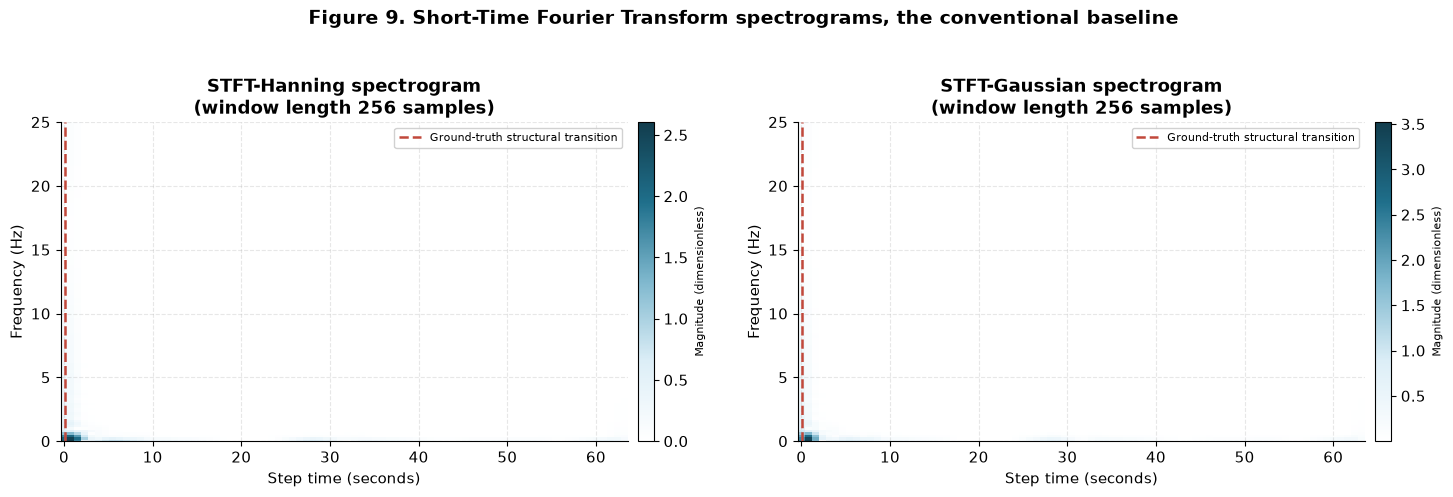


The key limitation being tested
--------------------------------------------------------------------------
Notice that the STFT resolution is uniform across all frequencies, because it is
fixed by a single window length. A wavelet transform instead adapts its resolution
with frequency, using short windows at high frequency and long windows at low
frequency. Whether that adaptivity gives measurably better transition detection on
real rheometer data is precisely the question this project is asking.


In [32]:
# Visualising the STFT spectrograms, the conventional baseline this project tests against

available_stft_methods = [
    "STFT-" + name for name in STFT_WINDOW_NAMES
    if method_results.get("STFT-" + name, {}).get("success", False)
]

figure, axes = plt.subplots(1, len(available_stft_methods),
                            figsize=(7.5 * len(available_stft_methods), 4.8))
axes = np.atleast_1d(axes)

for panel_index, method_key in enumerate(available_stft_methods):
    axis_object = axes[panel_index]
    record = method_results[method_key]

    magnitude_matrix = record["magnitude"]
    frequency_values = record["frequencies"]
    time_values      = record["time_axis"] + analysis_time[0]

    image = axis_object.pcolormesh(
        time_values, frequency_values, magnitude_matrix,
        shading="auto", cmap=SCALOGRAM_COLORMAP
    )

    axis_object.set_xlabel("Step time (seconds)")
    axis_object.set_ylabel("Frequency (Hz)")
    axis_object.set_title(
        method_key + " spectrogram\n(window length "
        + str(record["segment_length"]) + " samples)"
    )
    axis_object.axvline(GROUND_TRUTH_TRANSITION_TIME, color=COLOUR_RED_ACCENT,
                        linestyle="--", linewidth=1.8,
                        label="Ground-truth structural transition")
    axis_object.set_ylim(0, analysis_frequency / 2)
    axis_object.legend(fontsize=8, loc="upper right")

    colour_bar = figure.colorbar(image, ax=axis_object, pad=0.015)
    colour_bar.set_label("Magnitude (dimensionless)", fontsize=8)

figure.suptitle("Figure 9. Short-Time Fourier Transform spectrograms, the conventional baseline",
                fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

print()
print("The key limitation being tested")
print("-" * 74)
print("Notice that the STFT resolution is uniform across all frequencies, because it is")
print("fixed by a single window length. A wavelet transform instead adapts its resolution")
print("with frequency, using short windows at high frequency and long windows at low")
print("frequency. Whether that adaptivity gives measurably better transition detection on")
print("real rheometer data is precisely the question this project is asking.")

---
# Section 5. Feature Engineering

Having computed the transforms, we now extract interpretable features from them. These are the quantities the project brief asks for: instantaneous modulus evolution, harmonic content, scale drift, entropy measures, and structural transition markers.

## 5.1 Features extracted and why each one matters

| Feature | Definition | Why it matters for this project |
|---|---|---|
| Instantaneous amplitude | Total energy across all scales at each instant | The direct analogue of the paper's instantaneous modulus |
| Dominant frequency | Frequency carrying most energy at each instant | Tracks how the characteristic timescale shifts as structure changes |
| Scale drift | Rate of change of the dominant frequency | The brief names this explicitly, it flags when the material's timescale is shifting |
| Wavelet entropy | Shannon entropy of the normalised energy distribution across scales | Low entropy means energy is concentrated at one scale, high entropy means it is spread out, so a structural transition typically shows as an entropy jump |
| Harmonic energy redistribution | Change in how energy divides between frequency bands | The brief names this explicitly, it is the wavelet analogue of harmonic distortion |
| Energy concentration | Fraction of total energy in the dominant band | Measures how sharply localised the signal is in frequency |

In [33]:
def extract_time_frequency_features(magnitude_matrix, frequency_values, time_values):
    """
    Extracting interpretable time-resolved features from a time-frequency magnitude matrix.

    Working for any method that produces a two dimensional magnitude array of shape
    (number_of_frequencies, number_of_time_points), which covers CWT, fCWT and STFT.

    Returning a dictionary of one dimensional feature arrays, each aligned to time.
    """
    # Keeping only valid positive frequencies
    valid_mask = (frequency_values > 0) & np.isfinite(frequency_values)
    magnitude_matrix = magnitude_matrix[valid_mask, :]
    frequency_values = frequency_values[valid_mask]

    # Sorting into ascending frequency order
    sort_order = np.argsort(frequency_values)
    frequency_values = frequency_values[sort_order]
    magnitude_matrix = magnitude_matrix[sort_order, :]

    # Working with energy, which is magnitude squared
    energy_matrix = magnitude_matrix ** 2

    feature_dictionary = {}

    # Feature 1, instantaneous amplitude, the total energy present at each moment
    instantaneous_amplitude = np.sqrt(np.sum(energy_matrix, axis=0))
    feature_dictionary["instantaneous_amplitude"] = instantaneous_amplitude

    # Feature 2, dominant frequency, where most energy sits at each moment
    dominant_frequency_indices = np.argmax(energy_matrix, axis=0)
    dominant_frequency = frequency_values[dominant_frequency_indices]
    feature_dictionary["dominant_frequency"] = dominant_frequency

    # Feature 3, energy weighted mean frequency, a smoother alternative to the peak
    total_energy_per_time = np.sum(energy_matrix, axis=0)
    total_energy_per_time_safe = np.where(total_energy_per_time > 0, total_energy_per_time, 1.0)
    mean_frequency = np.sum(
        energy_matrix * frequency_values[:, np.newaxis], axis=0
    ) / total_energy_per_time_safe
    feature_dictionary["mean_frequency"] = mean_frequency

    # Feature 4, wavelet entropy, measuring how spread out the energy is across scales
    normalised_energy = energy_matrix / total_energy_per_time_safe[np.newaxis, :]
    normalised_energy_safe = np.where(normalised_energy > 1e-15, normalised_energy, 1e-15)
    wavelet_entropy = -np.sum(normalised_energy_safe * np.log(normalised_energy_safe), axis=0)
    feature_dictionary["wavelet_entropy"] = wavelet_entropy

    # Feature 5, energy concentration, the share held by the single strongest band
    peak_energy_per_time = np.max(energy_matrix, axis=0)
    energy_concentration = peak_energy_per_time / total_energy_per_time_safe
    feature_dictionary["energy_concentration"] = energy_concentration

    # Feature 6, scale drift, how quickly the dominant frequency is moving
    if len(time_values) == len(dominant_frequency):
        scale_drift = np.gradient(dominant_frequency, time_values)
    else:
        interpolated_time = np.linspace(time_values[0], time_values[-1], len(dominant_frequency))
        scale_drift = np.gradient(dominant_frequency, interpolated_time)
    feature_dictionary["scale_drift"] = scale_drift

    # Feature 7, low against high band energy ratio, capturing harmonic redistribution
    frequency_midpoint = len(frequency_values) // 2
    low_band_energy  = np.sum(energy_matrix[:frequency_midpoint, :], axis=0)
    high_band_energy = np.sum(energy_matrix[frequency_midpoint:, :], axis=0)
    high_band_energy_safe = np.where(high_band_energy > 0, high_band_energy, 1e-15)
    feature_dictionary["low_to_high_energy_ratio"] = low_band_energy / high_band_energy_safe

    feature_dictionary["frequency_axis"] = frequency_values

    return feature_dictionary


print("Function extract_time_frequency_features defined.")
print()
print("Features extracted per method:")
print("  instantaneous_amplitude   analogue of the paper's instantaneous modulus")
print("  dominant_frequency        characteristic timescale at each instant")
print("  mean_frequency            energy weighted frequency centroid")
print("  wavelet_entropy           spread of energy across scales")
print("  energy_concentration      sharpness of frequency localisation")
print("  scale_drift               rate of change of dominant frequency")
print("  low_to_high_energy_ratio  harmonic energy redistribution")

Function extract_time_frequency_features defined.

Features extracted per method:
  instantaneous_amplitude   analogue of the paper's instantaneous modulus
  dominant_frequency        characteristic timescale at each instant
  mean_frequency            energy weighted frequency centroid
  wavelet_entropy           spread of energy across scales
  energy_concentration      sharpness of frequency localisation
  scale_drift               rate of change of dominant frequency
  low_to_high_energy_ratio  harmonic energy redistribution


In [34]:
def resample_feature_to_reference_grid(feature_array, reference_length):
    """
    Resampling a feature array onto the reference time grid.

    Different methods produce features at different time resolutions. The STFT in
    particular produces one value per window rather than one per sample. This brings
    every feature onto a common grid so they can be compared and correlated.
    """
    feature_array = np.asarray(feature_array).ravel()

    if len(feature_array) == reference_length:
        return feature_array

    if len(feature_array) < 2:
        return np.full(reference_length, float(feature_array[0]) if len(feature_array) else 0.0)

    source_positions = np.linspace(0.0, 1.0, len(feature_array))
    target_positions = np.linspace(0.0, 1.0, reference_length)

    interpolation_function = interp1d(
        source_positions, feature_array,
        kind="linear", bounds_error=False,
        fill_value=(feature_array[0], feature_array[-1])
    )

    return interpolation_function(target_positions)


# Extracting features for every method that produced a two dimensional output
reference_length = len(analysis_signal)
extracted_features = {}

for method_key, record in method_results.items():
    if not record["success"]:
        continue

    if record["method_family"] == "DWT":
        # DWT has no continuous scalogram, so features are built from its band structure.
        # Each detail level is upsampled back to full length, forming an equivalent matrix.
        detail_matrix_rows = []
        band_frequencies   = []

        for level_index, detail_coefficients in enumerate(record["detail_coefficients"]):
            upsampled_detail = resample_feature_to_reference_grid(
                np.abs(np.asarray(detail_coefficients)), reference_length
            )
            detail_matrix_rows.append(upsampled_detail)
            band = record["band_information"][record["decomposition_level"] - 1 - level_index]
            band_frequencies.append(0.5 * (band["lower_frequency"] + band["upper_frequency"]))

        magnitude_matrix = np.array(detail_matrix_rows)
        frequency_values = np.array(band_frequencies)

    else:
        magnitude_matrix = record["magnitude"]
        frequency_values = record["frequencies"]

    if magnitude_matrix.ndim != 2 or magnitude_matrix.shape[0] < 2:
        continue

    method_time_axis = np.linspace(
        analysis_time[0], analysis_time[-1], magnitude_matrix.shape[1]
    )

    feature_dictionary = extract_time_frequency_features(
        magnitude_matrix, frequency_values, method_time_axis
    )

    # Bringing every feature onto the common reference grid
    aligned_features = {}
    for feature_name, feature_values in feature_dictionary.items():
        if feature_name == "frequency_axis":
            aligned_features[feature_name] = feature_values
            continue
        aligned_features[feature_name] = resample_feature_to_reference_grid(
            feature_values, reference_length
        )

    extracted_features[method_key] = aligned_features

print("Features extracted for", len(extracted_features), "methods")
print()
print("All features aligned to a common grid of", reference_length, "samples")
print("This allows direct point by point comparison against the lambda(t) reference signal.")

Features extracted for 13 methods

All features aligned to a common grid of 3150 samples
This allows direct point by point comparison against the lambda(t) reference signal.


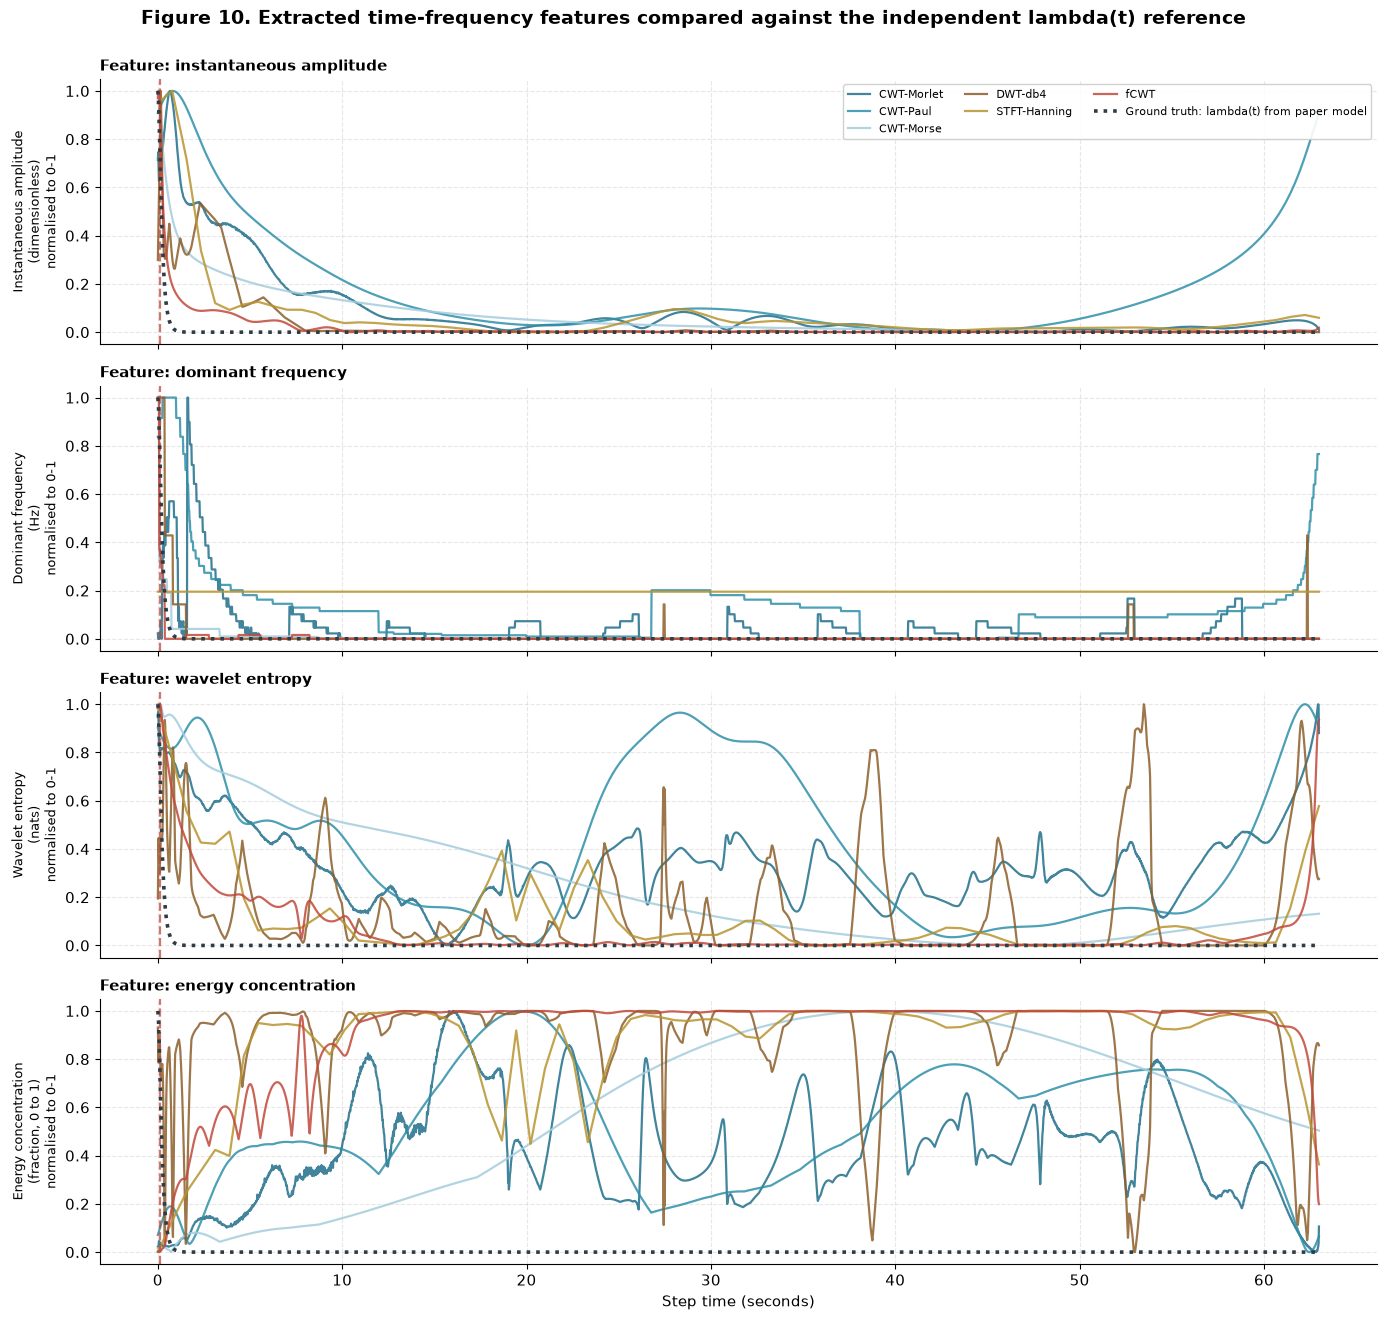


What to look for
--------------------------------------------------------------------------
The dotted dark line is lambda(t), computed by the paper's physics model with no
frequency-domain mathematics involved. Where a coloured feature curve follows that
dotted line closely, the corresponding method is capturing genuine structural
information. Section 6 quantifies this correspondence with R squared and p values.


In [35]:
# Visualising the extracted features for a representative set of methods,
# with the ground-truth lambda(t) signal overlaid for comparison.

methods_to_display = [
    key for key in ["CWT-Morlet", "CWT-Paul", "CWT-Morse", "DWT-db4", "STFT-Hanning", "fCWT"]
    if key in extracted_features
]

features_to_display = [
    ("instantaneous_amplitude", "Instantaneous amplitude\n(dimensionless)"),
    ("dominant_frequency",      "Dominant frequency\n(Hz)"),
    ("wavelet_entropy",         "Wavelet entropy\n(nats)"),
    ("energy_concentration",    "Energy concentration\n(fraction, 0 to 1)"),
]

figure, axes = plt.subplots(len(features_to_display), 1,
                            figsize=(14, 3.3 * len(features_to_display)),
                            sharex=True)

for feature_index, (feature_key, feature_axis_label) in enumerate(features_to_display):
    axis_object = axes[feature_index]

    for method_key in methods_to_display:
        if feature_key not in extracted_features[method_key]:
            continue
        feature_values = extracted_features[method_key][feature_key]

        # Normalising each method to its own range so shapes can be compared directly
        value_range = np.ptp(feature_values)
        if value_range > 0:
            normalised_values = (feature_values - np.min(feature_values)) / value_range
        else:
            normalised_values = feature_values

        axis_object.plot(
            analysis_time, normalised_values,
            linewidth=1.6, alpha=0.85,
            color=METHOD_COLOURS.get(method_key, COLOUR_TEXT_DARK),
            label=method_key
        )

    # Overlaying the independent ground-truth structure signal
    lambda_range = np.ptp(LAMBDA_REFERENCE_SIGNAL)
    if lambda_range > 0:
        normalised_lambda = (LAMBDA_REFERENCE_SIGNAL - np.min(LAMBDA_REFERENCE_SIGNAL)) / lambda_range
    else:
        normalised_lambda = LAMBDA_REFERENCE_SIGNAL

    axis_object.plot(
        analysis_time, normalised_lambda,
        color=COLOUR_TEXT_DARK, linewidth=2.6, linestyle=":",
        label="Ground truth: lambda(t) from paper model", zorder=10
    )

    axis_object.axvline(GROUND_TRUTH_TRANSITION_TIME, color=COLOUR_RED_ACCENT,
                        linestyle="--", linewidth=1.6, alpha=0.75)

    axis_object.set_ylabel(feature_axis_label + "\nnormalised to 0-1", fontsize=9)
    axis_object.set_title(
        "Feature: " + feature_key.replace("_", " "),
        fontsize=11, loc="left"
    )

    if feature_index == 0:
        axis_object.legend(fontsize=8, ncol=3, loc="upper right")

axes[-1].set_xlabel("Step time (seconds)")

figure.suptitle(
    "Figure 10. Extracted time-frequency features compared against the independent lambda(t) reference",
    fontsize=14, fontweight="bold", y=0.998
)
plt.tight_layout()
plt.show()

print()
print("What to look for")
print("-" * 74)
print("The dotted dark line is lambda(t), computed by the paper's physics model with no")
print("frequency-domain mathematics involved. Where a coloured feature curve follows that")
print("dotted line closely, the corresponding method is capturing genuine structural")
print("information. Section 6 quantifies this correspondence with R squared and p values.")

---
# Section 6. Evaluation Metrics

This section implements the full metric suite from last semester, adapted to this real dataset, plus the model-comparison metrics used in the reference paper.

## 6.1 Metrics implemented

| Metric | What it measures | Origin |
|---|---|---|
| Structural transition timing accuracy | How closely a method locates the transition event | Project brief, generalised from gel point timing |
| Total Harmonic Distortion | Energy in harmonics relative to the fundamental | Project brief |
| R squared and p value | How well a method's feature tracks the physical lambda(t) | Project brief |
| Signal-to-Noise Ratio | Signal power relative to noise power | Project brief |
| Amplitude error | Error in recovered signal amplitude | Project brief |
| Phase error | Error in recovered signal phase | Project brief |
| Mean Absolute Percentage Error | Relative reconstruction error | Project brief |
| Reconstruction RMSE | Absolute reconstruction error | Standard |
| Computation time | Wall-clock cost of the method | Practical scalability |
| Complexity-penalised score | Accuracy adjusted for method cost | Adapted from the paper's AIC and BIC approach |

## 6.2 On the gel point metric

As set out at the top of this notebook, blood rheology has no gelation event, so *gel point timing accuracy* is implemented here as **structural transition timing accuracy**. Two independent reference events are used:

1. the time of fastest structural change, from the physical model
2. the measured stress overshoot peak, direct from the instrument

Using two independent references guards against a method appearing accurate merely because it agrees with one particular definition of the event.

In [36]:
def compute_transition_timing_error(feature_values, time_values, reference_time):
    """
    Computing how accurately a feature locates a structural transition event.

    The transition is taken to be the moment when the feature changes fastest,
    which is where its absolute gradient peaks. The error is the difference between
    that detected time and the known reference time.

    Returning the detected time, the absolute error in seconds, and the error as a
    percentage of the total recording duration.
    """
    feature_values = np.asarray(feature_values).ravel()

    # Smoothing lightly before differentiating, since raw gradients are noise sensitive
    window_length = max(3, min(11, len(feature_values) // 20))
    if window_length % 2 == 0:
        window_length = window_length + 1

    if len(feature_values) > window_length:
        smoothed_feature = sp_signal.savgol_filter(
            feature_values, window_length=window_length, polyorder=2
        )
    else:
        smoothed_feature = feature_values

    feature_gradient = np.gradient(smoothed_feature, time_values)
    detected_index = int(np.argmax(np.abs(feature_gradient)))
    detected_time = float(time_values[detected_index])

    absolute_error = abs(detected_time - reference_time)
    recording_duration = float(time_values[-1] - time_values[0])

    if recording_duration > 0:
        percentage_error = 100.0 * absolute_error / recording_duration
    else:
        percentage_error = np.nan

    return {
        "detected_time"     : detected_time,
        "reference_time"    : reference_time,
        "absolute_error_s"  : absolute_error,
        "percentage_error"  : percentage_error,
    }


def compute_total_harmonic_distortion(signal_values, sampling_frequency,
                                      fundamental_frequency=None,
                                      number_of_harmonics=5):
    """
    Computing Total Harmonic Distortion from the signal's power spectrum.

    THD is the ratio of energy held in the harmonics to energy at the fundamental.
    A higher value indicates a more nonlinear response, which in rheology signals
    increasing structural breakdown.
    """
    signal_values = np.asarray(signal_values).ravel()
    centred_signal = signal_values - np.mean(signal_values)

    # Applying a Hanning window to reduce spectral leakage before the FFT
    window_array = np.hanning(len(centred_signal))
    windowed_signal = centred_signal * window_array

    spectrum = np.abs(np.fft.rfft(windowed_signal))
    frequency_axis = np.fft.rfftfreq(len(windowed_signal), d=1.0 / sampling_frequency)

    # Excluding the DC component when locating the fundamental
    if fundamental_frequency is None:
        searchable_spectrum = spectrum.copy()
        searchable_spectrum[0] = 0.0
        fundamental_index = int(np.argmax(searchable_spectrum))
        fundamental_frequency = float(frequency_axis[fundamental_index])
    else:
        fundamental_index = int(np.argmin(np.abs(frequency_axis - fundamental_frequency)))

    if fundamental_index == 0 or spectrum[fundamental_index] <= 0:
        return {"thd_percent": np.nan, "fundamental_frequency": fundamental_frequency}

    fundamental_amplitude = spectrum[fundamental_index]

    # Summing the energy at integer multiples of the fundamental
    harmonic_energy_sum = 0.0
    harmonics_found = 0

    for harmonic_number in range(2, number_of_harmonics + 2):
        harmonic_frequency = fundamental_frequency * harmonic_number
        if harmonic_frequency >= frequency_axis[-1]:
            break
        harmonic_index = int(np.argmin(np.abs(frequency_axis - harmonic_frequency)))
        harmonic_energy_sum = harmonic_energy_sum + spectrum[harmonic_index] ** 2
        harmonics_found = harmonics_found + 1

    thd_ratio = np.sqrt(harmonic_energy_sum) / fundamental_amplitude
    thd_percent = 100.0 * thd_ratio

    return {
        "thd_percent"           : float(thd_percent),
        "fundamental_frequency" : float(fundamental_frequency),
        "harmonics_counted"     : harmonics_found,
    }


print("Functions defined:")
print("  compute_transition_timing_error")
print("  compute_total_harmonic_distortion")

Functions defined:
  compute_transition_timing_error
  compute_total_harmonic_distortion


In [37]:
def compute_correlation_with_reference(feature_values, reference_values):
    """
    Computing how strongly a feature tracks the independent reference signal.

    Returning Pearson and Spearman correlations with their p values, plus the
    R squared value from a linear fit. Spearman is included because the
    relationship may be monotonic without being strictly linear.
    """
    feature_values   = np.asarray(feature_values).ravel()
    reference_values = np.asarray(reference_values).ravel()

    # Aligning lengths if they differ
    common_length = min(len(feature_values), len(reference_values))
    feature_values   = feature_values[:common_length]
    reference_values = reference_values[:common_length]

    valid_mask = np.isfinite(feature_values) & np.isfinite(reference_values)
    feature_values   = feature_values[valid_mask]
    reference_values = reference_values[valid_mask]

    if len(feature_values) < 4 or np.std(feature_values) == 0 or np.std(reference_values) == 0:
        return {
            "pearson_r"        : np.nan,
            "pearson_p_value"  : np.nan,
            "r_squared"        : np.nan,
            "spearman_rho"     : np.nan,
            "spearman_p_value" : np.nan,
        }

    pearson_r, pearson_p = sp_stats.pearsonr(feature_values, reference_values)
    spearman_rho, spearman_p = sp_stats.spearmanr(feature_values, reference_values)

    return {
        "pearson_r"        : float(pearson_r),
        "pearson_p_value"  : float(pearson_p),
        "r_squared"        : float(pearson_r ** 2),
        "spearman_rho"     : float(spearman_rho),
        "spearman_p_value" : float(spearman_p),
    }


def compute_signal_to_noise_ratio(original_signal, reconstructed_signal):
    """
    Computing the Signal-to-Noise Ratio in decibels.

    Treating the difference between the original and the reconstruction as noise,
    this measures how much of the original signal power survives the transform
    and inverse transform round trip.
    """
    original_signal      = np.asarray(original_signal).ravel()
    reconstructed_signal = np.asarray(reconstructed_signal).ravel()

    common_length = min(len(original_signal), len(reconstructed_signal))
    original_signal      = original_signal[:common_length]
    reconstructed_signal = reconstructed_signal[:common_length]

    signal_power = float(np.sum(original_signal ** 2))
    noise_power  = float(np.sum((original_signal - reconstructed_signal) ** 2))

    if noise_power <= 0:
        return float("inf")
    if signal_power <= 0:
        return float("-inf")

    return float(10.0 * np.log10(signal_power / noise_power))


def compute_amplitude_and_phase_errors(original_signal, reconstructed_signal):
    """
    Computing amplitude and phase error between an original and reconstructed signal.

    Amplitude error compares the magnitude spectra. Phase error compares the phase
    spectra, restricted to frequencies where there is enough energy for the phase
    to be meaningful.
    """
    original_signal      = np.asarray(original_signal).ravel()
    reconstructed_signal = np.asarray(reconstructed_signal).ravel()

    common_length = min(len(original_signal), len(reconstructed_signal))
    original_signal      = original_signal[:common_length]
    reconstructed_signal = reconstructed_signal[:common_length]

    original_spectrum      = np.fft.rfft(original_signal)
    reconstructed_spectrum = np.fft.rfft(reconstructed_signal)

    original_magnitude      = np.abs(original_spectrum)
    reconstructed_magnitude = np.abs(reconstructed_spectrum)

    # Considering only frequencies holding meaningful energy
    energy_threshold = 0.01 * np.max(original_magnitude) if np.max(original_magnitude) > 0 else 0.0
    significant_mask = original_magnitude > energy_threshold

    if np.sum(significant_mask) == 0:
        return {"amplitude_error_percent": np.nan, "phase_error_radians": np.nan}

    amplitude_relative_error = np.abs(
        reconstructed_magnitude[significant_mask] - original_magnitude[significant_mask]
    ) / original_magnitude[significant_mask]
    amplitude_error_percent = 100.0 * float(np.mean(amplitude_relative_error))

    original_phase      = np.angle(original_spectrum[significant_mask])
    reconstructed_phase = np.angle(reconstructed_spectrum[significant_mask])

    phase_difference = reconstructed_phase - original_phase
    # Wrapping the phase difference into the range minus pi to plus pi
    phase_difference = np.arctan2(np.sin(phase_difference), np.cos(phase_difference))
    phase_error_radians = float(np.mean(np.abs(phase_difference)))

    return {
        "amplitude_error_percent" : amplitude_error_percent,
        "phase_error_radians"     : phase_error_radians,
        "phase_error_degrees"     : float(np.degrees(phase_error_radians)),
    }


def compute_mean_absolute_percentage_error(original_signal, reconstructed_signal,
                                           minimum_denominator=1e-6):
    """
    Computing the Mean Absolute Percentage Error between two signals.

    Samples where the original is very close to zero are excluded, because MAPE
    is undefined there and would otherwise produce meaningless large values.
    """
    original_signal      = np.asarray(original_signal).ravel()
    reconstructed_signal = np.asarray(reconstructed_signal).ravel()

    common_length = min(len(original_signal), len(reconstructed_signal))
    original_signal      = original_signal[:common_length]
    reconstructed_signal = reconstructed_signal[:common_length]

    usable_mask = np.abs(original_signal) > minimum_denominator
    if np.sum(usable_mask) == 0:
        return np.nan

    absolute_percentage_errors = np.abs(
        (original_signal[usable_mask] - reconstructed_signal[usable_mask])
        / original_signal[usable_mask]
    )

    return float(100.0 * np.mean(absolute_percentage_errors))


print("Functions defined:")
print("  compute_correlation_with_reference")
print("  compute_signal_to_noise_ratio")
print("  compute_amplitude_and_phase_errors")
print("  compute_mean_absolute_percentage_error")

Functions defined:
  compute_correlation_with_reference
  compute_signal_to_noise_ratio
  compute_amplitude_and_phase_errors
  compute_mean_absolute_percentage_error


In [38]:
def reconstruct_signal_from_method(method_key, record, original_signal, sampling_frequency):
    """
    Reconstructing the original signal from a method's transform output.

    Reconstruction quality is central to several metrics, since a transform that
    cannot faithfully represent the signal cannot be trusted to characterise it.
    Each method family requires its own inverse procedure.
    """
    try:
        if record["method_family"] == "DWT":
            # The DWT provides an exact inverse transform
            return record["reconstructed_signal"][:len(original_signal)]

        if record["method_family"] == "STFT":
            # The STFT has a well defined inverse via overlap add
            if record["window_name"] == "Hanning":
                window_array = sp_signal.get_window("hann", record["segment_length"])
            else:
                window_array = sp_signal.windows.gaussian(
                    record["segment_length"], std=record["segment_length"] / 7.0
                )

            overlap_samples = int(record["segment_length"] * 0.85)
            overlap_samples = min(overlap_samples, record["segment_length"] - 1)

            _, reconstructed = sp_signal.istft(
                record["coefficients"],
                fs=sampling_frequency,
                window=window_array,
                nperseg=record["segment_length"],
                noverlap=overlap_samples,
            )
            return np.asarray(reconstructed)[:len(original_signal)]

        # For CWT and fCWT an approximate inverse is used, summing across scales
        # with the standard one over scale weighting.
        coefficients = record["coefficients"]
        frequencies  = record["frequencies"]

        valid_mask = (frequencies > 0) & np.isfinite(frequencies)
        coefficients = coefficients[valid_mask, :]
        frequencies  = frequencies[valid_mask]

        real_part = np.real(coefficients)
        weights = frequencies[:, np.newaxis]
        reconstructed = np.sum(real_part * weights, axis=0)

        # Rescaling to match the original signal's variance, since the approximate
        # inverse recovers the shape but not the absolute scale
        if np.std(reconstructed) > 0:
            reconstructed = reconstructed / np.std(reconstructed) * np.std(original_signal)
            reconstructed = reconstructed - np.mean(reconstructed) + np.mean(original_signal)

        return np.asarray(reconstructed)[:len(original_signal)]

    except Exception:
        return None


print("Function reconstruct_signal_from_method defined.")
print()
print("Reconstruction approach by family:")
print("  DWT   exact inverse via pywt.waverec")
print("  STFT  exact inverse via scipy.signal.istft with overlap add")
print("  CWT   approximate inverse by summing across scales with 1/scale weighting")
print("  fCWT  same approximate inverse as CWT")

Function reconstruct_signal_from_method defined.

Reconstruction approach by family:
  DWT   exact inverse via pywt.waverec
  STFT  exact inverse via scipy.signal.istft with overlap add
  CWT   approximate inverse by summing across scales with 1/scale weighting
  fCWT  same approximate inverse as CWT


In [39]:
import time as timing_module

# Running the complete metric suite for every successful method

metric_records = []

for method_key, record in method_results.items():
    if not record["success"]:
        metric_records.append({
            "method"            : method_key,
            "family"            : method_key.split("-")[0],
            "status"            : "unavailable",
            "note"              : record["message"],
        })
        continue

    metric_row = {
        "method" : method_key,
        "family" : record["method_family"],
        "status" : "ok",
        "note"   : "",
    }

    # Timing the method by re running it, which gives a fair scalability measure
    timing_start = timing_module.perf_counter()
    if record["method_family"] == "CWT":
        _ = run_continuous_wavelet_transform(
            analysis_signal, analysis_frequency, record["wavelet_name"]
        )
    elif record["method_family"] == "DWT":
        _ = run_discrete_wavelet_transform(
            analysis_signal, analysis_frequency, record["wavelet_name"]
        )
    elif record["method_family"] == "STFT":
        _ = run_short_time_fourier_transform(
            analysis_signal, analysis_frequency, record["window_name"]
        )
    elif record["method_family"] == "fCWT":
        _ = run_fast_continuous_wavelet_transform(analysis_signal, analysis_frequency)
    metric_row["computation_time_ms"] = 1000.0 * (timing_module.perf_counter() - timing_start)

    # Reconstruction based metrics
    reconstructed_signal = reconstruct_signal_from_method(
        method_key, record, analysis_signal, analysis_frequency
    )

    if reconstructed_signal is not None and len(reconstructed_signal) > 4:
        padded_reconstruction = np.zeros_like(analysis_signal)
        usable_length = min(len(reconstructed_signal), len(analysis_signal))
        padded_reconstruction[:usable_length] = reconstructed_signal[:usable_length]

        metric_row["snr_db"] = compute_signal_to_noise_ratio(analysis_signal, padded_reconstruction)
        metric_row["reconstruction_rmse"] = float(
            np.sqrt(np.mean((analysis_signal - padded_reconstruction) ** 2))
        )
        metric_row["mape_percent"] = compute_mean_absolute_percentage_error(
            analysis_signal, padded_reconstruction
        )

        amplitude_phase = compute_amplitude_and_phase_errors(analysis_signal, padded_reconstruction)
        metric_row["amplitude_error_percent"] = amplitude_phase["amplitude_error_percent"]
        metric_row["phase_error_degrees"]     = amplitude_phase.get("phase_error_degrees", np.nan)
    else:
        metric_row["snr_db"] = np.nan
        metric_row["reconstruction_rmse"] = np.nan
        metric_row["mape_percent"] = np.nan
        metric_row["amplitude_error_percent"] = np.nan
        metric_row["phase_error_degrees"] = np.nan

    # Feature based metrics
    if method_key in extracted_features:
        features = extracted_features[method_key]

        # Transition timing accuracy against both independent references
        timing_against_model = compute_transition_timing_error(
            features["instantaneous_amplitude"], analysis_time, GROUND_TRUTH_TRANSITION_TIME
        )
        timing_against_data = compute_transition_timing_error(
            features["instantaneous_amplitude"], analysis_time, MEASURED_PEAK_TIME
        )

        metric_row["transition_error_vs_model_s"] = timing_against_model["absolute_error_s"]
        metric_row["transition_error_vs_data_s"]  = timing_against_data["absolute_error_s"]
        metric_row["transition_detected_time_s"]  = timing_against_model["detected_time"]

        # Correlation of the amplitude feature against the physical lambda signal
        correlation_amplitude = compute_correlation_with_reference(
            features["instantaneous_amplitude"], LAMBDA_REFERENCE_SIGNAL
        )
        metric_row["r_squared_vs_lambda"]  = correlation_amplitude["r_squared"]
        metric_row["p_value_vs_lambda"]    = correlation_amplitude["pearson_p_value"]
        metric_row["spearman_vs_lambda"]   = correlation_amplitude["spearman_rho"]

        # Correlation of entropy against the rate of structural change
        correlation_entropy = compute_correlation_with_reference(
            features["wavelet_entropy"], np.abs(LAMBDA_RATE_OF_CHANGE)
        )
        metric_row["entropy_r_squared_vs_lambda_rate"] = correlation_entropy["r_squared"]

        # Harmonic distortion measured on the instantaneous amplitude feature
        thd_result = compute_total_harmonic_distortion(
            features["instantaneous_amplitude"], analysis_frequency
        )
        metric_row["thd_percent"] = thd_result["thd_percent"]

        # Summary statistics of the scale drift feature
        metric_row["mean_absolute_scale_drift"] = float(
            np.mean(np.abs(features["scale_drift"]))
        )

    metric_records.append(metric_row)

metrics_frame = pd.DataFrame(metric_records)

print("Metric evaluation complete for", len(metrics_frame), "methods")
print()
print("Metrics computed per method:")
for column_name in metrics_frame.columns:
    if column_name not in ["method", "family", "status", "note"]:
        print("   " + column_name)

Metric evaluation complete for 13 methods

Metrics computed per method:
   computation_time_ms
   snr_db
   reconstruction_rmse
   mape_percent
   amplitude_error_percent
   phase_error_degrees
   transition_error_vs_model_s
   transition_error_vs_data_s
   transition_detected_time_s
   r_squared_vs_lambda
   p_value_vs_lambda
   spearman_vs_lambda
   entropy_r_squared_vs_lambda_rate
   thd_percent
   mean_absolute_scale_drift


---
# Section 7. Model Comparison and Results

This section brings every metric together into a single comparison, following the structured evaluation approach Ragil asked for: consistent criteria applied uniformly, rather than subjective judgement.

In [40]:
# Presenting the full metric table for every method

successful_metrics = metrics_frame[metrics_frame["status"] == "ok"].copy()

display_columns = [
    "method", "family",
    "r_squared_vs_lambda", "p_value_vs_lambda",
    "transition_error_vs_model_s", "transition_error_vs_data_s",
    "snr_db", "thd_percent",
    "amplitude_error_percent", "phase_error_degrees",
    "mape_percent", "computation_time_ms",
]

available_display_columns = [column for column in display_columns if column in successful_metrics.columns]

print("COMPLETE METRIC TABLE")
print("=" * 130)
formatted_table = successful_metrics[available_display_columns].copy()

for column_name in formatted_table.columns:
    if formatted_table[column_name].dtype.kind in "fc":
        formatted_table[column_name] = formatted_table[column_name].round(4)

print(formatted_table.to_string(index=False))

unavailable_methods = metrics_frame[metrics_frame["status"] != "ok"]
if len(unavailable_methods) > 0:
    print()
    print("Methods that could not be evaluated")
    print("-" * 70)
    for _, row in unavailable_methods.iterrows():
        print("  " + str(row["method"]).ljust(16) + str(row["note"]))

COMPLETE METRIC TABLE
       method family  r_squared_vs_lambda  p_value_vs_lambda  transition_error_vs_model_s  transition_error_vs_data_s   snr_db  thd_percent  amplitude_error_percent  phase_error_degrees  mape_percent  computation_time_ms
   CWT-Morlet    CWT               0.1084                0.0                         0.12                        0.20   2.3313      43.4720                 107.0881              13.9943      153.1047              67.4042
     CWT-Paul    CWT               0.0691                0.0                        62.44                       62.36   4.8960      38.0363                  98.2308              69.9914      300.1454               5.8252
      CWT-DOG    CWT               0.1358                0.0                         0.12                        0.20   3.9121     111.5035                  73.5357              18.7832      124.1980              27.6812
  CWT-Shannon    CWT               0.1767                0.0                         0.00     

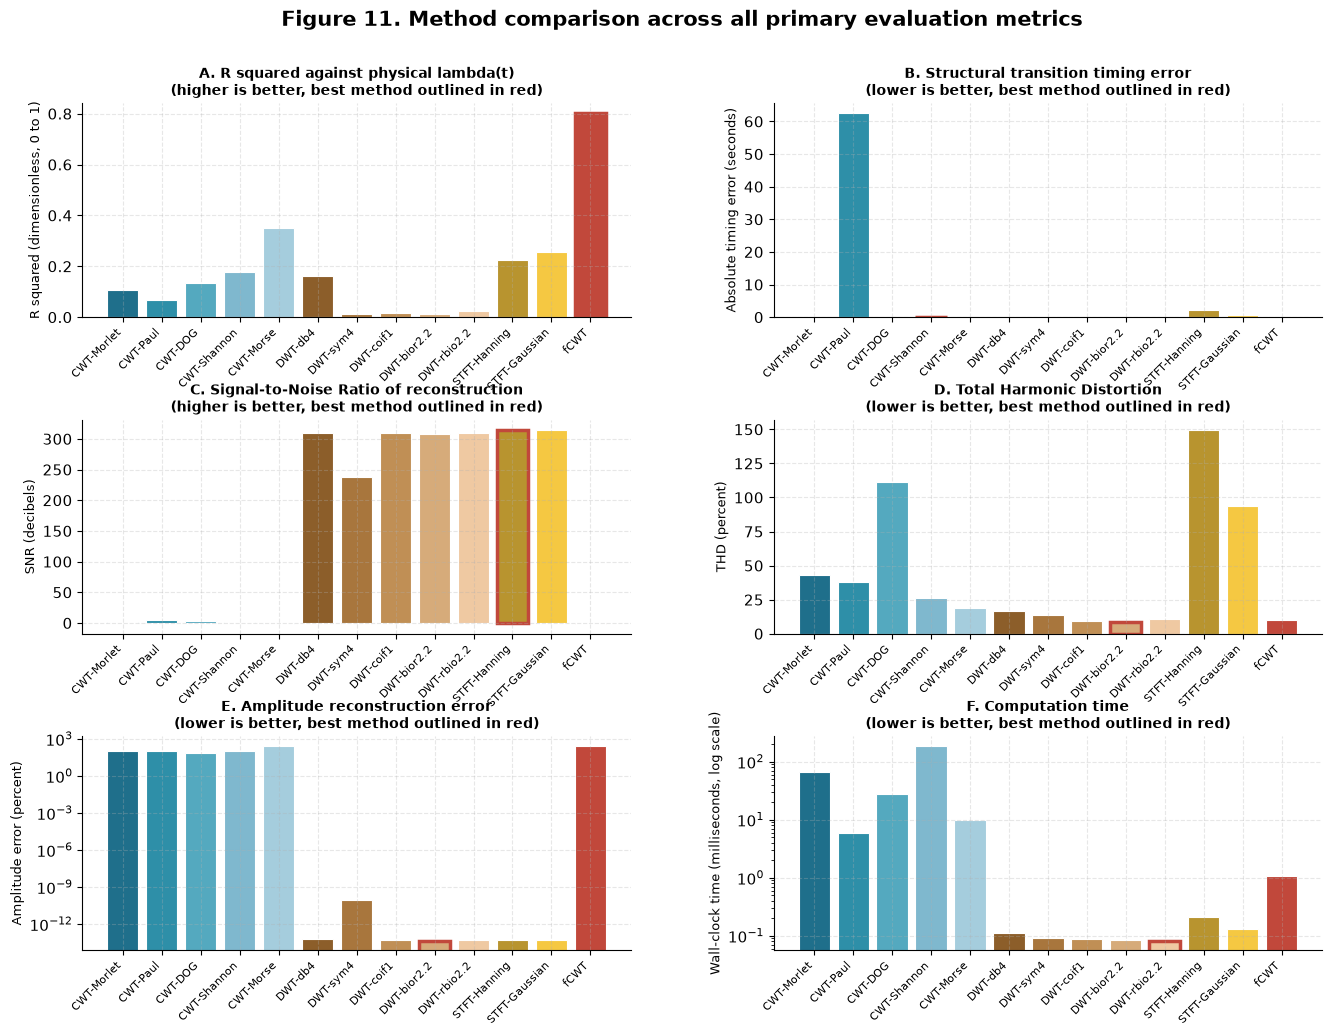

In [41]:
# Visualising the headline comparison across the primary metrics

figure = plt.figure(figsize=(16, 11))
grid = gridspec.GridSpec(3, 2, hspace=0.48, wspace=0.26)

comparison_frame = successful_metrics.copy()
method_labels = comparison_frame["method"].tolist()
bar_colours = [METHOD_COLOURS.get(name, COLOUR_DEEP_BLUE) for name in method_labels]


def draw_metric_panel(axis_object, metric_column, panel_title, y_axis_label,
                      lower_is_better, use_log_scale=False):
    """
    Drawing one metric comparison panel with consistent formatting.
    """
    if metric_column not in comparison_frame.columns:
        axis_object.axis("off")
        return

    values = comparison_frame[metric_column].values.astype(float)
    finite_mask = np.isfinite(values)

    plot_labels = [label for label, keep in zip(method_labels, finite_mask) if keep]
    plot_values = values[finite_mask]
    plot_colours = [colour for colour, keep in zip(bar_colours, finite_mask) if keep]

    if len(plot_values) == 0:
        axis_object.axis("off")
        return

    bars = axis_object.bar(range(len(plot_values)), plot_values,
                           color=plot_colours, edgecolor="white", linewidth=0.8)

    # Highlighting the best performing method with a bold outline
    if lower_is_better:
        best_index = int(np.argmin(plot_values))
    else:
        best_index = int(np.argmax(plot_values))
    bars[best_index].set_edgecolor(COLOUR_RED_ACCENT)
    bars[best_index].set_linewidth(2.5)

    axis_object.set_xticks(range(len(plot_labels)))
    axis_object.set_xticklabels(plot_labels, rotation=45, ha="right", fontsize=8)
    axis_object.set_ylabel(y_axis_label, fontsize=9)

    direction_text = "lower is better" if lower_is_better else "higher is better"
    axis_object.set_title(panel_title + "\n(" + direction_text
                          + ", best method outlined in red)", fontsize=10)

    if use_log_scale:
        positive_values = plot_values[plot_values > 0]
        if len(positive_values) > 0:
            axis_object.set_yscale("log")


axis_1 = figure.add_subplot(grid[0, 0])
draw_metric_panel(
    axis_1, "r_squared_vs_lambda",
    "A. R squared against physical lambda(t)",
    "R squared (dimensionless, 0 to 1)",
    lower_is_better=False
)

axis_2 = figure.add_subplot(grid[0, 1])
draw_metric_panel(
    axis_2, "transition_error_vs_model_s",
    "B. Structural transition timing error",
    "Absolute timing error (seconds)",
    lower_is_better=True
)

axis_3 = figure.add_subplot(grid[1, 0])
draw_metric_panel(
    axis_3, "snr_db",
    "C. Signal-to-Noise Ratio of reconstruction",
    "SNR (decibels)",
    lower_is_better=False
)

axis_4 = figure.add_subplot(grid[1, 1])
draw_metric_panel(
    axis_4, "thd_percent",
    "D. Total Harmonic Distortion",
    "THD (percent)",
    lower_is_better=True
)

axis_5 = figure.add_subplot(grid[2, 0])
draw_metric_panel(
    axis_5, "amplitude_error_percent",
    "E. Amplitude reconstruction error",
    "Amplitude error (percent)",
    lower_is_better=True, use_log_scale=True
)

axis_6 = figure.add_subplot(grid[2, 1])
draw_metric_panel(
    axis_6, "computation_time_ms",
    "F. Computation time",
    "Wall-clock time (milliseconds, log scale)",
    lower_is_better=True, use_log_scale=True
)

figure.suptitle(
    "Figure 11. Method comparison across all primary evaluation metrics",
    fontsize=15, fontweight="bold", y=0.965
)
plt.show()

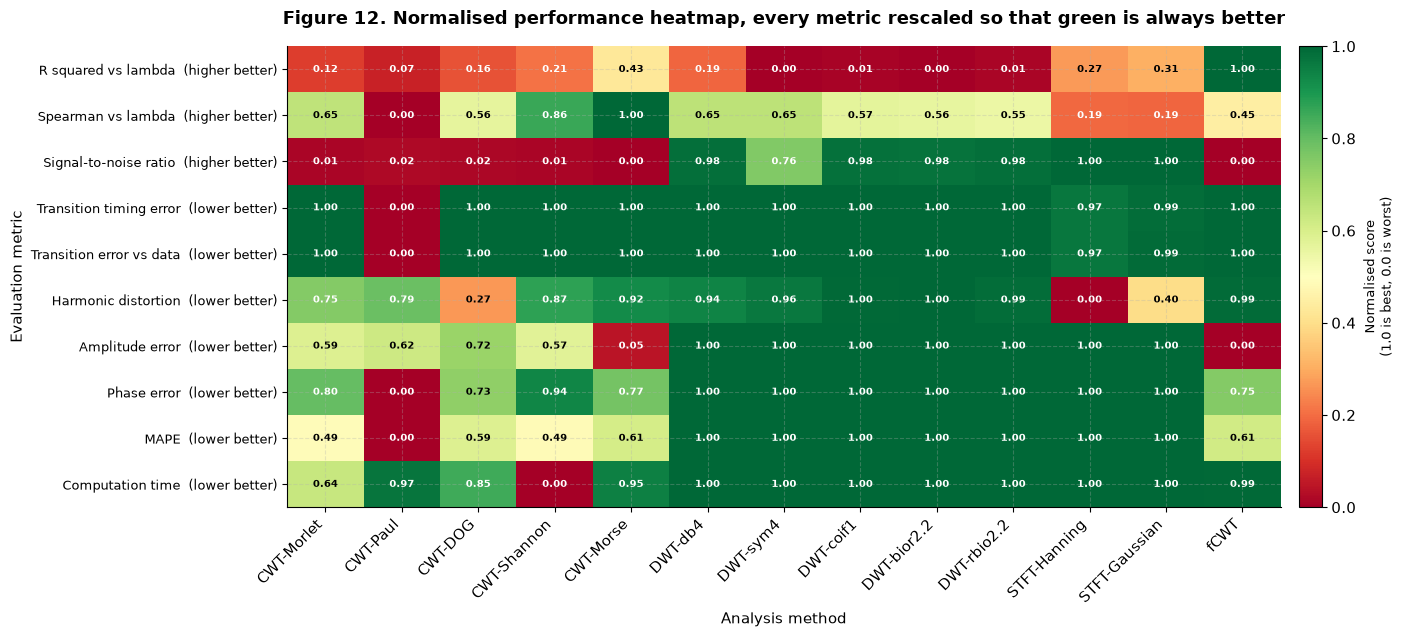


How this heatmap is built
--------------------------------------------------------------------------
Each metric row is rescaled to the range 0 to 1 across methods. For metrics where a
lower raw value is better, the scale is inverted, so green always means better
performance regardless of the underlying metric direction. This makes it possible to
read across very different quantities on a single common scale.


In [42]:
# Building a normalised heatmap so every metric can be seen on one common scale

heatmap_metric_definitions = [
    ("r_squared_vs_lambda",          "R squared vs lambda",        False),
    ("spearman_vs_lambda",           "Spearman vs lambda",         False),
    ("snr_db",                       "Signal-to-noise ratio",      False),
    ("transition_error_vs_model_s",  "Transition timing error",    True),
    ("transition_error_vs_data_s",   "Transition error vs data",   True),
    ("thd_percent",                  "Harmonic distortion",        True),
    ("amplitude_error_percent",      "Amplitude error",            True),
    ("phase_error_degrees",          "Phase error",                True),
    ("mape_percent",                 "MAPE",                       True),
    ("computation_time_ms",          "Computation time",           True),
]

available_heatmap_metrics = [
    entry for entry in heatmap_metric_definitions
    if entry[0] in successful_metrics.columns
]

normalised_score_matrix = []
heatmap_row_labels = []

for metric_column, display_name, lower_is_better in available_heatmap_metrics:
    values = successful_metrics[metric_column].values.astype(float)

    # Replacing infinities so they do not distort the normalisation
    values = np.where(np.isinf(values), np.nan, values)

    if np.all(np.isnan(values)):
        continue

    minimum_value = np.nanmin(values)
    maximum_value = np.nanmax(values)

    if maximum_value - minimum_value < 1e-15:
        normalised = np.full_like(values, 0.5)
    else:
        normalised = (values - minimum_value) / (maximum_value - minimum_value)
        if lower_is_better:
            normalised = 1.0 - normalised

    normalised_score_matrix.append(normalised)
    heatmap_row_labels.append(display_name + ("  (lower better)" if lower_is_better else "  (higher better)"))

normalised_score_matrix = np.array(normalised_score_matrix)

figure, axis_object = plt.subplots(figsize=(15, 6.5))

image = axis_object.imshow(
    normalised_score_matrix, aspect="auto", cmap="RdYlGn",
    vmin=0, vmax=1
)

axis_object.set_xticks(range(len(successful_metrics)))
axis_object.set_xticklabels(successful_metrics["method"].tolist(), rotation=45, ha="right")
axis_object.set_yticks(range(len(heatmap_row_labels)))
axis_object.set_yticklabels(heatmap_row_labels, fontsize=9)
axis_object.set_xlabel("Analysis method")
axis_object.set_ylabel("Evaluation metric")
axis_object.set_title(
    "Figure 12. Normalised performance heatmap, every metric rescaled so that green is always better",
    fontsize=13, fontweight="bold", pad=16
)

# Writing the normalised score into each cell
for row_index in range(normalised_score_matrix.shape[0]):
    for column_index in range(normalised_score_matrix.shape[1]):
        cell_value = normalised_score_matrix[row_index, column_index]
        if np.isfinite(cell_value):
            axis_object.text(
                column_index, row_index, "{:.2f}".format(cell_value),
                ha="center", va="center", fontsize=7.5,
                color="black" if 0.25 < cell_value < 0.75 else "white",
                fontweight="bold"
            )

colour_bar = figure.colorbar(image, ax=axis_object, pad=0.015)
colour_bar.set_label("Normalised score\n(1.0 is best, 0.0 is worst)", fontsize=9)

plt.tight_layout()
plt.show()

print()
print("How this heatmap is built")
print("-" * 74)
print("Each metric row is rescaled to the range 0 to 1 across methods. For metrics where a")
print("lower raw value is better, the scale is inverted, so green always means better")
print("performance regardless of the underlying metric direction. This makes it possible to")
print("read across very different quantities on a single common scale.")

In [43]:
# Producing an overall ranking using a complexity-penalised composite score.
# This mirrors the AIC and BIC approach used in the reference paper, where accuracy
# gains are only credited if they justify the additional cost.

ACCURACY_METRIC_WEIGHTS = {
    "r_squared_vs_lambda"         : 0.25,
    "transition_error_vs_model_s" : 0.20,
    "transition_error_vs_data_s"  : 0.15,
    "snr_db"                      : 0.15,
    "amplitude_error_percent"     : 0.10,
    "phase_error_degrees"         : 0.05,
    "mape_percent"                : 0.05,
    "thd_percent"                 : 0.05,
}

LOWER_IS_BETTER_METRICS = {
    "transition_error_vs_model_s", "transition_error_vs_data_s",
    "amplitude_error_percent", "phase_error_degrees",
    "mape_percent", "thd_percent", "computation_time_ms",
}

# The complexity penalty weight, analogous to the parameter penalty in AIC and BIC
COMPLEXITY_PENALTY_WEIGHT = 0.10

ranking_frame = successful_metrics.copy()
composite_accuracy_scores = np.zeros(len(ranking_frame))
total_weight_applied = 0.0

for metric_column, metric_weight in ACCURACY_METRIC_WEIGHTS.items():
    if metric_column not in ranking_frame.columns:
        continue

    values = ranking_frame[metric_column].values.astype(float)
    values = np.where(np.isinf(values), np.nan, values)

    if np.all(np.isnan(values)):
        continue

    minimum_value = np.nanmin(values)
    maximum_value = np.nanmax(values)

    if maximum_value - minimum_value < 1e-15:
        normalised = np.full_like(values, 0.5)
    else:
        normalised = (values - minimum_value) / (maximum_value - minimum_value)
        if metric_column in LOWER_IS_BETTER_METRICS:
            normalised = 1.0 - normalised

    normalised = np.nan_to_num(normalised, nan=0.0)
    composite_accuracy_scores = composite_accuracy_scores + metric_weight * normalised
    total_weight_applied = total_weight_applied + metric_weight

if total_weight_applied > 0:
    composite_accuracy_scores = composite_accuracy_scores / total_weight_applied

ranking_frame["accuracy_score"] = composite_accuracy_scores

# Building the complexity penalty from computation time
if "computation_time_ms" in ranking_frame.columns:
    time_values = ranking_frame["computation_time_ms"].values.astype(float)
    time_values = np.where(np.isfinite(time_values), time_values, np.nanmax(time_values))
    log_time = np.log10(np.maximum(time_values, 1e-3))
    time_range = np.nanmax(log_time) - np.nanmin(log_time)
    if time_range > 1e-15:
        normalised_cost = (log_time - np.nanmin(log_time)) / time_range
    else:
        normalised_cost = np.zeros_like(log_time)
else:
    normalised_cost = np.zeros(len(ranking_frame))

ranking_frame["complexity_cost"] = normalised_cost
ranking_frame["penalised_score"] = (
    ranking_frame["accuracy_score"] - COMPLEXITY_PENALTY_WEIGHT * ranking_frame["complexity_cost"]
)

ranking_frame = ranking_frame.sort_values("penalised_score", ascending=False).reset_index(drop=True)
ranking_frame["rank"] = range(1, len(ranking_frame) + 1)

print("OVERALL METHOD RANKING")
print("=" * 92)
print("Composite accuracy score, then penalised for computational cost,")
print("following the same philosophy as the AIC and BIC penalties in the reference paper.")
print()

ranking_display = ranking_frame[[
    "rank", "method", "family", "accuracy_score", "complexity_cost", "penalised_score"
]].copy()
ranking_display["accuracy_score"]  = ranking_display["accuracy_score"].round(4)
ranking_display["complexity_cost"] = ranking_display["complexity_cost"].round(4)
ranking_display["penalised_score"] = ranking_display["penalised_score"].round(4)

print(ranking_display.to_string(index=False))

OVERALL METHOD RANKING
Composite accuracy score, then penalised for computational cost,
following the same philosophy as the AIC and BIC penalties in the reference paper.

 rank        method family  accuracy_score  complexity_cost  penalised_score
    1       DWT-db4    DWT          0.7910           0.0408           0.7869
    2 STFT-Gaussian   STFT          0.7926           0.0579           0.7868
    3   DWT-rbio2.2    DWT          0.7496           0.0000           0.7496
    4     DWT-coif1    DWT          0.7481           0.0058           0.7475
    5   DWT-bior2.2    DWT          0.7461           0.0044           0.7457
    6  STFT-Hanning   STFT          0.7560           0.1189           0.7441
    7      DWT-sym4    DWT          0.7116           0.0157           0.7100
    8          fCWT   fCWT          0.7176           0.3319           0.6845
    9     CWT-Morse    CWT          0.5770           0.6186           0.5151
   10   CWT-Shannon    CWT          0.5764           1.000

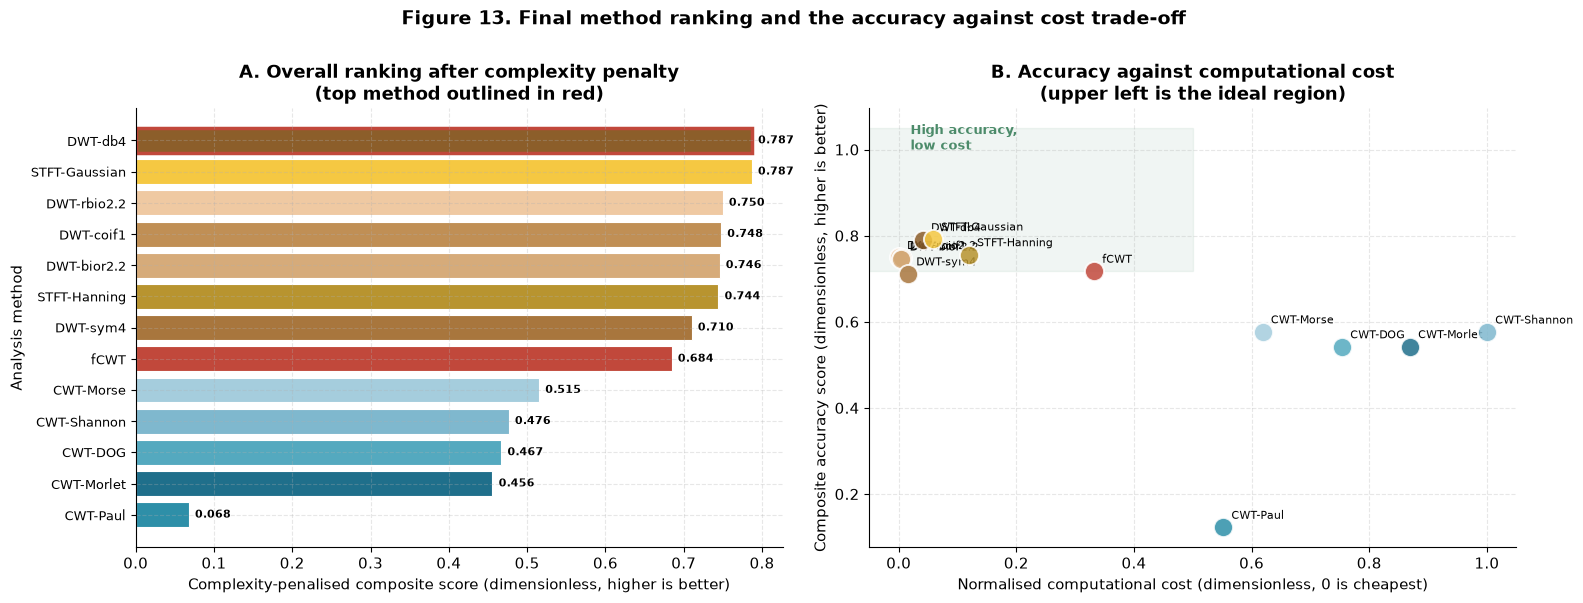


TOP RANKED METHOD: DWT-db4
--------------------------------------------------------------------------
Composite accuracy score       : 0.791
Normalised computational cost  : 0.0408
Final penalised score          : 0.7869
R squared against lambda(t)    : 0.1622
Transition timing error        : 0.12 seconds


In [44]:
# Visualising the final ranking

figure, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: ranked penalised scores
axis_a = axes[0]
ranking_labels = ranking_frame["method"].tolist()
ranking_colours = [METHOD_COLOURS.get(name, COLOUR_DEEP_BLUE) for name in ranking_labels]

bar_positions = np.arange(len(ranking_frame))
bars = axis_a.barh(bar_positions, ranking_frame["penalised_score"].values,
                   color=ranking_colours, edgecolor="white", linewidth=0.8)

# Highlighting the top ranked method
bars[0].set_edgecolor(COLOUR_RED_ACCENT)
bars[0].set_linewidth(2.5)

axis_a.set_yticks(bar_positions)
axis_a.set_yticklabels(ranking_labels, fontsize=9)
axis_a.invert_yaxis()
axis_a.set_xlabel("Complexity-penalised composite score (dimensionless, higher is better)")
axis_a.set_ylabel("Analysis method")
axis_a.set_title("A. Overall ranking after complexity penalty\n(top method outlined in red)")

for bar_index, value in enumerate(ranking_frame["penalised_score"].values):
    axis_a.text(value + 0.008, bar_index, "{:.3f}".format(value),
                va="center", fontsize=8, fontweight="bold")

# Panel B: accuracy against computational cost
axis_b = axes[1]

for _, row in ranking_frame.iterrows():
    axis_b.scatter(
        row["complexity_cost"], row["accuracy_score"],
        s=190, alpha=0.85,
        color=METHOD_COLOURS.get(row["method"], COLOUR_DEEP_BLUE),
        edgecolor="white", linewidth=1.4, zorder=5
    )
    axis_b.annotate(
        row["method"],
        xy=(row["complexity_cost"], row["accuracy_score"]),
        xytext=(6, 6), textcoords="offset points",
        fontsize=8
    )

axis_b.set_xlabel("Normalised computational cost (dimensionless, 0 is cheapest)")
axis_b.set_ylabel("Composite accuracy score (dimensionless, higher is better)")
axis_b.set_title("B. Accuracy against computational cost\n(upper left is the ideal region)")

# Shading the desirable region
axis_b.axhspan(
    ranking_frame["accuracy_score"].median(), 1.05,
    xmin=0, xmax=0.5, alpha=0.08, color=COLOUR_GREEN
)
axis_b.text(
    0.02, 1.0, "High accuracy,\nlow cost",
    fontsize=9, color=COLOUR_GREEN, fontweight="bold",
    transform=axis_b.get_yaxis_transform() if False else axis_b.transData
)

figure.suptitle("Figure 13. Final method ranking and the accuracy against cost trade-off",
                fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

print()
print("TOP RANKED METHOD:", ranking_frame.iloc[0]["method"])
print("-" * 74)
top_method_row = ranking_frame.iloc[0]
print("Composite accuracy score       :", round(float(top_method_row["accuracy_score"]), 4))
print("Normalised computational cost  :", round(float(top_method_row["complexity_cost"]), 4))
print("Final penalised score          :", round(float(top_method_row["penalised_score"]), 4))
if "r_squared_vs_lambda" in top_method_row:
    print("R squared against lambda(t)    :", round(float(top_method_row["r_squared_vs_lambda"]), 4))
if "transition_error_vs_model_s" in top_method_row:
    print("Transition timing error        :", round(float(top_method_row["transition_error_vs_model_s"]), 4), "seconds")

PERFORMANCE BY METHOD FAMILY
        method_count  mean_accuracy_score  best_accuracy_score  mean_penalised_score  best_penalised_score
family                                                                                                    
DWT                5               0.7493               0.7910                0.7480                0.7869
STFT               2               0.7743               0.7926                0.7655                0.7868
fCWT               1               0.7176               0.7176                0.6845                0.6845
CWT                5               0.4722               0.5770                0.3964                0.5151



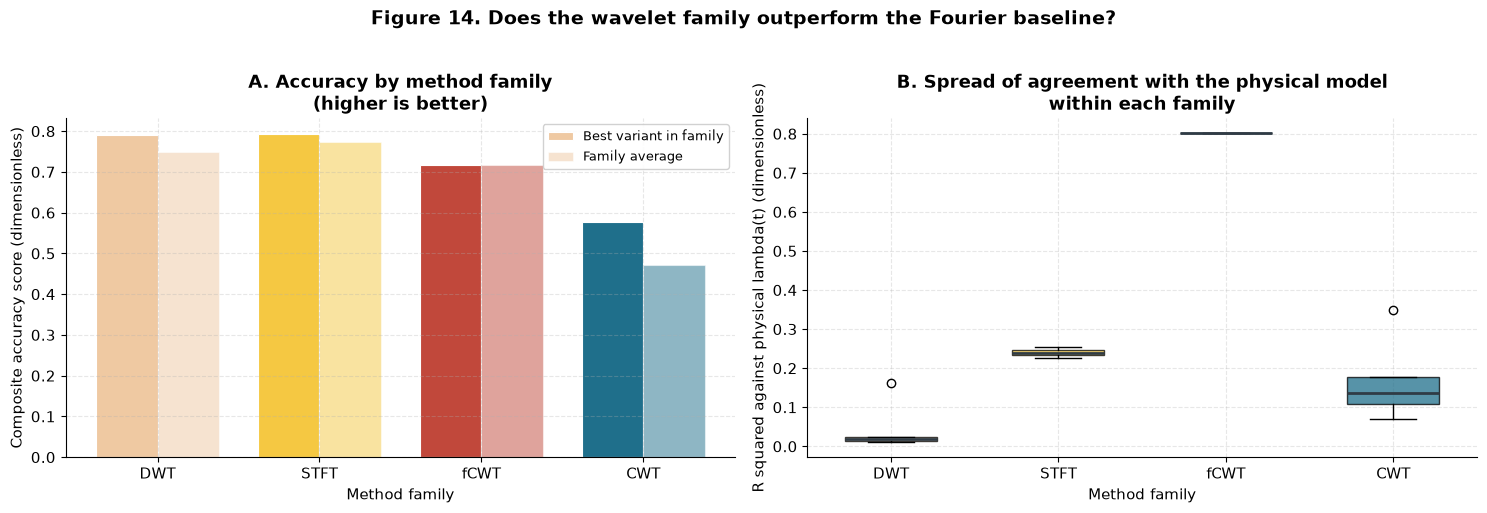

In [45]:
# Comparing performance by method family rather than individual variant.
# This answers the project's core question directly: do wavelets beat Fourier methods?

family_comparison = ranking_frame.groupby("family").agg(
    method_count           = ("method", "count"),
    mean_accuracy_score    = ("accuracy_score", "mean"),
    best_accuracy_score    = ("accuracy_score", "max"),
    mean_penalised_score   = ("penalised_score", "mean"),
    best_penalised_score   = ("penalised_score", "max"),
).round(4).sort_values("best_penalised_score", ascending=False)

print("PERFORMANCE BY METHOD FAMILY")
print("=" * 92)
print(family_comparison.to_string())
print()

figure, axes = plt.subplots(1, 2, figsize=(15, 5))

family_names = family_comparison.index.tolist()
family_colours = {
    "CWT"  : COLOUR_DEEP_BLUE,
    "DWT"  : COLOUR_SKIN,
    "STFT" : COLOUR_YELLOW,
    "fCWT" : COLOUR_RED_ACCENT,
}
family_bar_colours = [family_colours.get(name, COLOUR_LIGHT_BLUE) for name in family_names]

# Panel A: best score achieved by each family
axis_a = axes[0]
bar_positions = np.arange(len(family_names))
bar_width = 0.38

axis_a.bar(bar_positions - bar_width / 2, family_comparison["best_accuracy_score"].values,
           bar_width, label="Best variant in family",
           color=family_bar_colours, edgecolor="white", linewidth=0.8)
axis_a.bar(bar_positions + bar_width / 2, family_comparison["mean_accuracy_score"].values,
           bar_width, label="Family average",
           color=family_bar_colours, alpha=0.5, edgecolor="white", linewidth=0.8)

axis_a.set_xticks(bar_positions)
axis_a.set_xticklabels(family_names)
axis_a.set_xlabel("Method family")
axis_a.set_ylabel("Composite accuracy score (dimensionless)")
axis_a.set_title("A. Accuracy by method family\n(higher is better)")
axis_a.legend(fontsize=9)

# Panel B: distribution of R squared within each family
axis_b = axes[1]
if "r_squared_vs_lambda" in ranking_frame.columns:
    family_groups = []
    family_group_labels = []
    for family_name in family_names:
        family_values = ranking_frame[
            ranking_frame["family"] == family_name
        ]["r_squared_vs_lambda"].dropna().values
        if len(family_values) > 0:
            family_groups.append(family_values)
            family_group_labels.append(family_name)

    if len(family_groups) > 0:
        # Not passing tick labels into boxplot directly, because the keyword was
        # renamed from 'labels' to 'tick_labels' in recent matplotlib versions.
        # Setting them afterwards behaves identically on every version.
        box_plot = axis_b.boxplot(family_groups, patch_artist=True, widths=0.55)

        axis_b.set_xticks(np.arange(1, len(family_group_labels) + 1))
        axis_b.set_xticklabels(family_group_labels)

        for patch, family_name in zip(box_plot["boxes"], family_group_labels):
            patch.set_facecolor(family_colours.get(family_name, COLOUR_LIGHT_BLUE))
            patch.set_alpha(0.75)
        for median_line in box_plot["medians"]:
            median_line.set_color(COLOUR_TEXT_DARK)
            median_line.set_linewidth(2.0)

axis_b.set_xlabel("Method family")
axis_b.set_ylabel("R squared against physical lambda(t) (dimensionless)")
axis_b.set_title("B. Spread of agreement with the physical model\nwithin each family")

figure.suptitle("Figure 14. Does the wavelet family outperform the Fourier baseline?",
                fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
# Section 8. Cross-Experiment Validation

A result obtained from one experiment could be a coincidence. This section repeats the full analysis across many experiments and several workbooks to check whether the ranking holds up.

This addresses the consistency requirement in the evaluation framework: any method that genuinely works should work repeatedly, not only on the single experiment it was tuned on.

In [46]:
def run_full_pipeline_on_signal(time_values, stress_values,
                                shear_rate_initial, shear_rate_final,
                                methods_to_run=None):
    """
    Running the complete pipeline end to end on a single experiment.

    Preprocessing the signal, running each requested method, extracting features,
    and computing metrics against a freshly simulated lambda(t) reference for that
    experiment's own shear-rate history.

    Returning a list of metric dictionaries, one per method.
    """
    if methods_to_run is None:
        methods_to_run = (
            ["CWT-" + name for name in CWT_WAVELET_NAMES]
            + ["DWT-" + name for name in DWT_WAVELET_NAMES]
            + ["STFT-" + name for name in STFT_WINDOW_NAMES]
            + ["fCWT"]
        )

    preprocessing = preprocess_signal(time_values, stress_values)
    if preprocessing is None:
        return []

    signal_for_analysis = preprocessing["processed_value"]
    time_for_analysis   = preprocessing["processed_time"]
    frequency_for_analysis = preprocessing["sampling_frequency_hz"]

    if len(signal_for_analysis) < 32:
        return []

    # Simulating the physical model for this specific experiment's shear-rate step
    def local_shear_rate_history(current_time):
        if current_time < 0:
            return shear_rate_initial
        return shear_rate_final

    try:
        local_model_time, _, local_model_lambda = simulate_ethixo_evp(
            local_shear_rate_history,
            (0.0, float(time_for_analysis[-1])),
            PAPER_PARAMETERS_DONOR3,
            shear_rate_initial,
            model_version=1,
        )
        local_lambda_interpolator = interp1d(
            local_model_time, local_model_lambda,
            kind="linear", bounds_error=False,
            fill_value=(local_model_lambda[0], local_model_lambda[-1])
        )
        local_lambda_reference = local_lambda_interpolator(time_for_analysis)
        local_lambda_rate = np.gradient(local_lambda_reference, time_for_analysis)
        local_transition_time = float(time_for_analysis[int(np.argmax(np.abs(local_lambda_rate)))])
    except Exception:
        return []

    local_results = []

    for method_key in methods_to_run:
        if method_key.startswith("CWT-"):
            record = run_continuous_wavelet_transform(
                signal_for_analysis, frequency_for_analysis, method_key.replace("CWT-", "")
            )
        elif method_key.startswith("DWT-"):
            record = run_discrete_wavelet_transform(
                signal_for_analysis, frequency_for_analysis, method_key.replace("DWT-", "")
            )
        elif method_key.startswith("STFT-"):
            record = run_short_time_fourier_transform(
                signal_for_analysis, frequency_for_analysis, method_key.replace("STFT-", "")
            )
        elif method_key == "fCWT":
            record = run_fast_continuous_wavelet_transform(
                signal_for_analysis, frequency_for_analysis
            )
        else:
            continue

        if not record["success"]:
            continue

        # Building the magnitude matrix for feature extraction
        try:
            if record["method_family"] == "DWT":
                detail_rows = []
                band_frequencies = []
                for level_index, detail_coefficients in enumerate(record["detail_coefficients"]):
                    detail_rows.append(resample_feature_to_reference_grid(
                        np.abs(np.asarray(detail_coefficients)), len(signal_for_analysis)
                    ))
                    band = record["band_information"][record["decomposition_level"] - 1 - level_index]
                    band_frequencies.append(0.5 * (band["lower_frequency"] + band["upper_frequency"]))
                magnitude_matrix = np.array(detail_rows)
                frequency_values = np.array(band_frequencies)
            else:
                magnitude_matrix = record["magnitude"]
                frequency_values = record["frequencies"]

            if magnitude_matrix.ndim != 2 or magnitude_matrix.shape[0] < 2:
                continue

            method_time_axis = np.linspace(
                time_for_analysis[0], time_for_analysis[-1], magnitude_matrix.shape[1]
            )
            features = extract_time_frequency_features(
                magnitude_matrix, frequency_values, method_time_axis
            )

            amplitude_feature = resample_feature_to_reference_grid(
                features["instantaneous_amplitude"], len(signal_for_analysis)
            )

            correlation = compute_correlation_with_reference(amplitude_feature, local_lambda_reference)
            timing = compute_transition_timing_error(
                amplitude_feature, time_for_analysis, local_transition_time
            )

            local_results.append({
                "method"                      : method_key,
                "family"                      : record["method_family"],
                "r_squared_vs_lambda"         : correlation["r_squared"],
                "p_value_vs_lambda"           : correlation["pearson_p_value"],
                "transition_error_vs_model_s" : timing["absolute_error_s"],
            })

        except Exception:
            continue

    return local_results


print("Function run_full_pipeline_on_signal defined.")
print("This runs the entire pipeline on one experiment, for use in cross validation.")

Function run_full_pipeline_on_signal defined.
This runs the entire pipeline on one experiment, for use in cross validation.


In [47]:
# Running the pipeline across every step-up experiment in the primary workbook

cross_validation_records = []

print("Running cross-experiment validation")
print("=" * 70)

for _, experiment_row in step_up_experiments.iterrows():
    sheet_name  = experiment_row["sheet"]
    block_index = int(experiment_row["block_index"])
    block = parsed_sheets[sheet_name]["blocks"][block_index]

    extraction = extract_time_series(block)
    if extraction is None:
        continue

    experiment_time, experiment_stress = extraction

    experiment_results = run_full_pipeline_on_signal(
        experiment_time, experiment_stress,
        float(experiment_row["initial_shear_rate"]),
        float(experiment_row["final_shear_rate"]),
    )

    for result_row in experiment_results:
        result_row["source_file"]     = PRIMARY_DATA_FILE
        result_row["condition_label"] = experiment_row["condition_label"]
        cross_validation_records.append(result_row)

    print("  " + str(experiment_row["condition_label"]).ljust(22)
          + str(len(experiment_results)) + " methods evaluated")

cross_validation_frame = pd.DataFrame(cross_validation_records)

print()
print("Total method-experiment evaluations:", len(cross_validation_frame))
print("Distinct experiments covered       :", cross_validation_frame["condition_label"].nunique())

Running cross-experiment validation
  .1-->5 (1/s)          13 methods evaluated
  .25-->5(1/s)          13 methods evaluated
  .1-->2.5 (1/s)        13 methods evaluated
  .25-->2.5(1/s)        13 methods evaluated
  .1-->1 (1/s)          13 methods evaluated
  .25-->1(1/s)          13 methods evaluated
  .1-->.5(1/s)          13 methods evaluated
  .25-->.5(1/s)         13 methods evaluated
  .1-->.25(1/s)         13 methods evaluated

Total method-experiment evaluations: 117
Distinct experiments covered       : 9


In [48]:
# Extending the validation to additional workbooks, checking the result holds across donors

ADDITIONAL_WORKBOOKS = ["data5.xlsx", "data9.xlsx", "data7.xlsx", "data1.xlsx"]

print("Extending validation to additional donor sessions")
print("=" * 70)

for workbook_name in ADDITIONAL_WORKBOOKS:
    workbook_path = os.path.join(DATA_DIRECTORY, workbook_name)

    if not os.path.exists(workbook_path):
        print("  " + workbook_name.ljust(16) + "not found, skipping")
        continue

    try:
        workbook_handle = pd.ExcelFile(workbook_path)
    except Exception as exception_message:
        print("  " + workbook_name.ljust(16) + "could not open -> " + str(exception_message))
        continue

    experiments_processed = 0

    for sheet_name in workbook_handle.sheet_names:
        experiment_type, is_time_series = classify_sheet_type(sheet_name)

        # Restricting to step tests, which carry the structural transition we are scoring
        if experiment_type != "Step Up/Down":
            continue

        try:
            sheet_blocks = parse_multiblock_sheet(workbook_path, sheet_name)
        except Exception:
            continue

        for block in sheet_blocks:
            initial_rate, final_rate, is_step_up = parse_step_condition(block["label"])

            if is_step_up is not True:
                continue
            if not np.isfinite(initial_rate) or not np.isfinite(final_rate):
                continue

            extraction = extract_time_series(block)
            if extraction is None:
                continue

            experiment_time, experiment_stress = extraction

            experiment_results = run_full_pipeline_on_signal(
                experiment_time, experiment_stress, initial_rate, final_rate
            )

            for result_row in experiment_results:
                result_row["source_file"]     = workbook_name
                result_row["condition_label"] = block["label"]
                cross_validation_records.append(result_row)

            if len(experiment_results) > 0:
                experiments_processed = experiments_processed + 1

    print("  " + workbook_name.ljust(16) + str(experiments_processed) + " step-up experiments processed")

cross_validation_frame = pd.DataFrame(cross_validation_records)

print()
print("CROSS-VALIDATION SUMMARY")
print("-" * 70)
print("Total method-experiment evaluations :", len(cross_validation_frame))
print("Distinct workbooks covered          :", cross_validation_frame["source_file"].nunique())
print("Distinct experiments covered        :",
      cross_validation_frame.groupby(["source_file", "condition_label"]).ngroups)

Extending validation to additional donor sessions
  data5.xlsx      9 step-up experiments processed
  data9.xlsx      27 step-up experiments processed
  data7.xlsx      5 step-up experiments processed
  data1.xlsx      3 step-up experiments processed

CROSS-VALIDATION SUMMARY
----------------------------------------------------------------------
Total method-experiment evaluations : 689
Distinct workbooks covered          : 5
Distinct experiments covered        : 35


CROSS-EXPERIMENT PERFORMANCE SUMMARY
               experiments_evaluated  mean_r_squared  median_r_squared  std_r_squared  mean_timing_error_s  median_timing_error_s
method                                                                                                                           
fCWT                              53          0.8328            0.8629         0.1153               0.0619                   0.04
CWT-Morse                         53          0.5491            0.5508         0.1661               0.0951                   0.04
STFT-Hanning                      53          0.2965            0.2615         0.1743               1.7064                   1.48
STFT-Gaussian                     53          0.2939            0.2544         0.1857               2.1015                   1.52
CWT-Shannon                       53          0.2870            0.2648         0.1634               0.3340                   0.08
DWT-sym4                          53          0.1920 

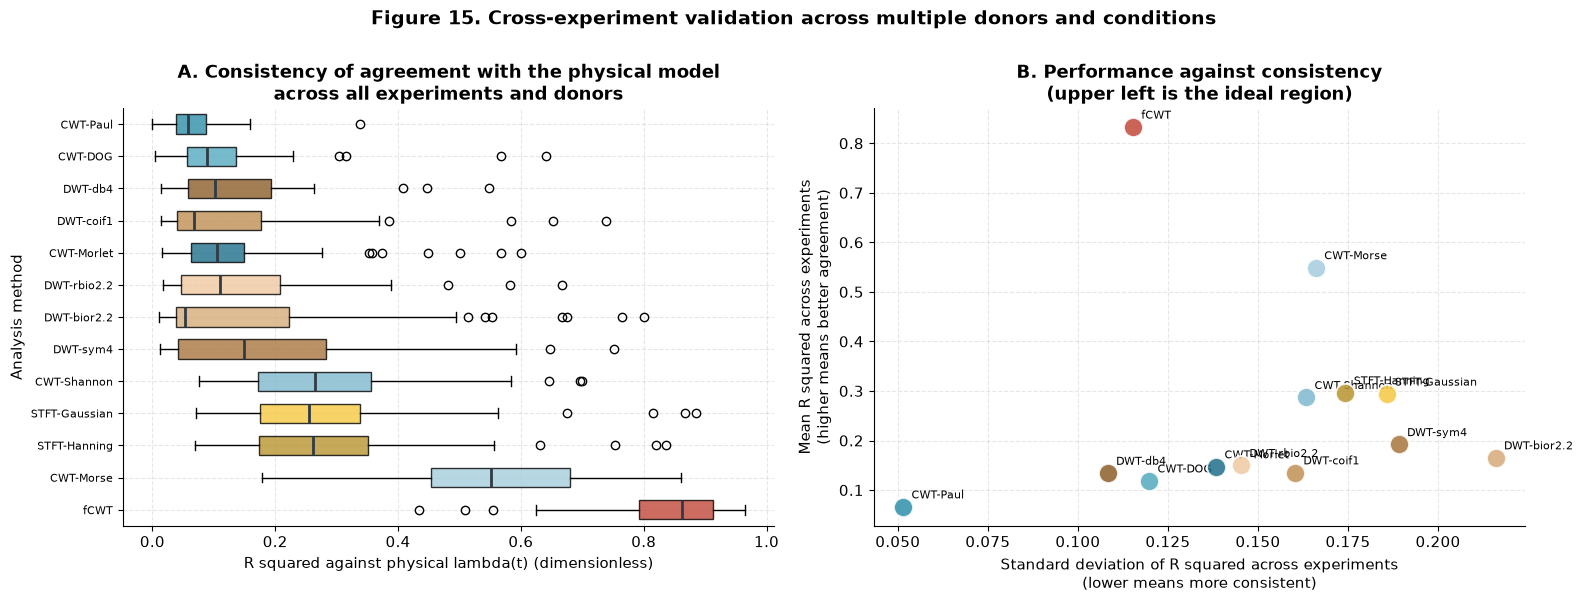


Why panel B matters
--------------------------------------------------------------------------
A method sitting in the upper left agrees closely with the physical model and does
so consistently across different donors and shear-rate steps. A method with a high
mean but also high variability is unreliable, since its good average performance
would depend on which experiment it happened to be tested on.


In [49]:
# Summarising cross-experiment performance and testing whether the ranking is stable

cross_validation_summary = cross_validation_frame.groupby("method").agg(
    experiments_evaluated  = ("r_squared_vs_lambda", "count"),
    mean_r_squared         = ("r_squared_vs_lambda", "mean"),
    median_r_squared       = ("r_squared_vs_lambda", "median"),
    std_r_squared          = ("r_squared_vs_lambda", "std"),
    mean_timing_error_s    = ("transition_error_vs_model_s", "mean"),
    median_timing_error_s  = ("transition_error_vs_model_s", "median"),
).round(4).sort_values("mean_r_squared", ascending=False)

print("CROSS-EXPERIMENT PERFORMANCE SUMMARY")
print("=" * 108)
print(cross_validation_summary.to_string())

figure, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: distribution of R squared per method across all experiments
axis_a = axes[0]
methods_in_order = cross_validation_summary.index.tolist()

box_data = []
box_labels = []
box_colours = []

for method_name in methods_in_order:
    method_values = cross_validation_frame[
        cross_validation_frame["method"] == method_name
    ]["r_squared_vs_lambda"].dropna().values
    if len(method_values) > 0:
        box_data.append(method_values)
        box_labels.append(method_name)
        box_colours.append(METHOD_COLOURS.get(method_name, COLOUR_DEEP_BLUE))

# Building the horizontal boxplot in a version-agnostic way. Two keywords changed
# in recent matplotlib: 'labels' became 'tick_labels', and 'vert' became
# 'orientation'. Neither is passed directly here.
try:
    box_plot = axis_a.boxplot(
        box_data, patch_artist=True, widths=0.6, orientation="horizontal"
    )
except TypeError:
    box_plot = axis_a.boxplot(
        box_data, patch_artist=True, widths=0.6, vert=False
    )

axis_a.set_yticks(np.arange(1, len(box_labels) + 1))
axis_a.set_yticklabels(box_labels)

for patch, colour in zip(box_plot["boxes"], box_colours):
    patch.set_facecolor(colour)
    patch.set_alpha(0.8)
for median_line in box_plot["medians"]:
    median_line.set_color(COLOUR_TEXT_DARK)
    median_line.set_linewidth(2.0)

axis_a.set_xlabel("R squared against physical lambda(t) (dimensionless)")
axis_a.set_ylabel("Analysis method")
axis_a.set_title("A. Consistency of agreement with the physical model\nacross all experiments and donors")
axis_a.tick_params(axis="y", labelsize=8)

# Panel B: stability, mean performance against its variability
axis_b = axes[1]
for method_name in methods_in_order:
    row = cross_validation_summary.loc[method_name]
    if not np.isfinite(row["mean_r_squared"]) or not np.isfinite(row["std_r_squared"]):
        continue
    axis_b.scatter(
        row["std_r_squared"], row["mean_r_squared"],
        s=190, alpha=0.85,
        color=METHOD_COLOURS.get(method_name, COLOUR_DEEP_BLUE),
        edgecolor="white", linewidth=1.4, zorder=5
    )
    axis_b.annotate(method_name, xy=(row["std_r_squared"], row["mean_r_squared"]),
                    xytext=(6, 6), textcoords="offset points", fontsize=8)

axis_b.set_xlabel("Standard deviation of R squared across experiments\n(lower means more consistent)")
axis_b.set_ylabel("Mean R squared across experiments\n(higher means better agreement)")
axis_b.set_title("B. Performance against consistency\n(upper left is the ideal region)")

figure.suptitle("Figure 15. Cross-experiment validation across multiple donors and conditions",
                fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

print()
print("Why panel B matters")
print("-" * 74)
print("A method sitting in the upper left agrees closely with the physical model and does")
print("so consistently across different donors and shear-rate steps. A method with a high")
print("mean but also high variability is unreliable, since its good average performance")
print("would depend on which experiment it happened to be tested on.")

In [50]:
# Testing formally whether the wavelet families outperform the STFT baseline.
# This uses a statistical test rather than eyeballing the difference, which is what
# the structured evaluation framework requires.

wavelet_family_values = cross_validation_frame[
    cross_validation_frame["family"].isin(["CWT", "fCWT"])
]["r_squared_vs_lambda"].dropna().values

dwt_family_values = cross_validation_frame[
    cross_validation_frame["family"] == "DWT"
]["r_squared_vs_lambda"].dropna().values

stft_family_values = cross_validation_frame[
    cross_validation_frame["family"] == "STFT"
]["r_squared_vs_lambda"].dropna().values

print("STATISTICAL COMPARISON OF METHOD FAMILIES")
print("=" * 78)
print("Question: do wavelet based methods track the physical structure signal")
print("          significantly better than the conventional Fourier baseline?")
print()

print("Sample sizes")
print("-" * 78)
print("Continuous wavelet methods (CWT and fCWT) :", len(wavelet_family_values), "evaluations")
print("Discrete wavelet methods (DWT)            :", len(dwt_family_values), "evaluations")
print("Fourier baseline (STFT)                   :", len(stft_family_values), "evaluations")
print()

print("Mean R squared against lambda(t)")
print("-" * 78)
if len(wavelet_family_values) > 0:
    print("Continuous wavelet methods :", round(float(np.mean(wavelet_family_values)), 4))
if len(dwt_family_values) > 0:
    print("Discrete wavelet methods   :", round(float(np.mean(dwt_family_values)), 4))
if len(stft_family_values) > 0:
    print("Fourier baseline (STFT)    :", round(float(np.mean(stft_family_values)), 4))
print()

# Using the Mann-Whitney U test, which does not assume normally distributed data
print("Mann-Whitney U test results")
print("-" * 78)

if len(wavelet_family_values) > 3 and len(stft_family_values) > 3:
    statistic_value, p_value = sp_stats.mannwhitneyu(
        wavelet_family_values, stft_family_values, alternative="two-sided"
    )
    print("Continuous wavelet against STFT")
    print("   U statistic :", round(float(statistic_value), 2))
    print("   p value     :", "{:.5f}".format(float(p_value)))
    if p_value < 0.05:
        better_family = "continuous wavelet" if np.mean(wavelet_family_values) > np.mean(stft_family_values) else "STFT"
        print("   Result      : statistically significant difference, favouring", better_family)
    else:
        print("   Result      : no statistically significant difference at the 5 percent level")
    print()

if len(dwt_family_values) > 3 and len(stft_family_values) > 3:
    statistic_value, p_value = sp_stats.mannwhitneyu(
        dwt_family_values, stft_family_values, alternative="two-sided"
    )
    print("Discrete wavelet against STFT")
    print("   U statistic :", round(float(statistic_value), 2))
    print("   p value     :", "{:.5f}".format(float(p_value)))
    if p_value < 0.05:
        better_family = "discrete wavelet" if np.mean(dwt_family_values) > np.mean(stft_family_values) else "STFT"
        print("   Result      : statistically significant difference, favouring", better_family)
    else:
        print("   Result      : no statistically significant difference at the 5 percent level")

print()
print("Note on interpretation")
print("-" * 78)
print("A non significant result is still a useful finding. It would indicate that on this")
print("particular blood step-test data, the theoretical advantage of wavelets does not")
print("translate into a measurable practical gain, which is important to report honestly")
print("and worth investigating on the gel systems the project will collect later.")

STATISTICAL COMPARISON OF METHOD FAMILIES
Question: do wavelet based methods track the physical structure signal
          significantly better than the conventional Fourier baseline?

Sample sizes
------------------------------------------------------------------------------
Continuous wavelet methods (CWT and fCWT) : 318 evaluations
Discrete wavelet methods (DWT)            : 265 evaluations
Fourier baseline (STFT)                   : 106 evaluations

Mean R squared against lambda(t)
------------------------------------------------------------------------------
Continuous wavelet methods : 0.3335
Discrete wavelet methods   : 0.1552
Fourier baseline (STFT)    : 0.2952

Mann-Whitney U test results
------------------------------------------------------------------------------
Continuous wavelet against STFT
   U statistic : 15011.0
   p value     : 0.09174
   Result      : no statistically significant difference at the 5 percent level

Discrete wavelet against STFT
   U statistic : 6013

---
# Section 9. Applying the Pipeline to LAOS Data

The LAOS experiments deserve separate treatment for two reasons:

1. They have the **highest sampling rate** in the dataset, at roughly 50 Hz, so they resolve the finest time-frequency detail.
2. They come with a **built-in ground truth for harmonic content**. The rheometer's own software computes the ratio of the third harmonic to the first harmonic, which the paper uses as its nonlinearity measure. This lets us validate our Total Harmonic Distortion calculation against an instrument-computed reference before trusting it elsewhere.

In [51]:
# Analysing the LAOS experiments, which carry the richest harmonic content

laos_experiments = catalogue_frame[
    catalogue_frame["experiment_type"].isin(["LAOS", "UDLAOS"])
].copy()

print("LAOS and UDLAOS experiments available:", len(laos_experiments))
print()

if len(laos_experiments) > 0:
    # Selecting the LAOS experiment with the most samples for the clearest analysis
    laos_row = laos_experiments.sort_values("sample_count", ascending=False).iloc[0]

    laos_block = parsed_sheets[laos_row["sheet"]]["blocks"][int(laos_row["block_index"])]
    laos_time, laos_stress = extract_time_series(laos_block)

    print("Selected LAOS experiment")
    print("-" * 70)
    print("Sheet            :", laos_row["sheet"])
    print("Condition        :", laos_row["condition_label"])
    print("Sample count     :", int(laos_row["sample_count"]))
    print("Duration         :", round(float(laos_row["duration_seconds"]), 3), "seconds")
    print("Sampling rate    :", round(float(laos_row["native_frequency_hz"]), 2), "Hz")

    laos_preprocessing = preprocess_signal(laos_time, laos_stress, apply_detrending=True)
    laos_signal = laos_preprocessing["processed_value"]
    laos_time_grid = laos_preprocessing["processed_time"]
    laos_frequency = laos_preprocessing["sampling_frequency_hz"]

    print("Preprocessed to  :", len(laos_signal), "samples at", laos_frequency, "Hz")

LAOS and UDLAOS experiments available: 23

Selected LAOS experiment
----------------------------------------------------------------------
Sheet            : LAOS
Condition        : LAOS omega=5 Gamma=0.5
Sample count     : 2005
Duration         : 39.963 seconds
Sampling rate    : 50.0 Hz
Preprocessed to  : 1999 samples at 50.0 Hz


HARMONIC ANALYSIS OF THE LAOS SIGNAL
Fundamental frequency detected : 0.8004 Hz
Total Harmonic Distortion      : 1.547 percent
Harmonics counted              : 5

In LAOS, harmonic distortion above roughly a few percent indicates the material
is responding nonlinearly, which physically corresponds to the microstructure
being actively broken down by the large amplitude oscillation.


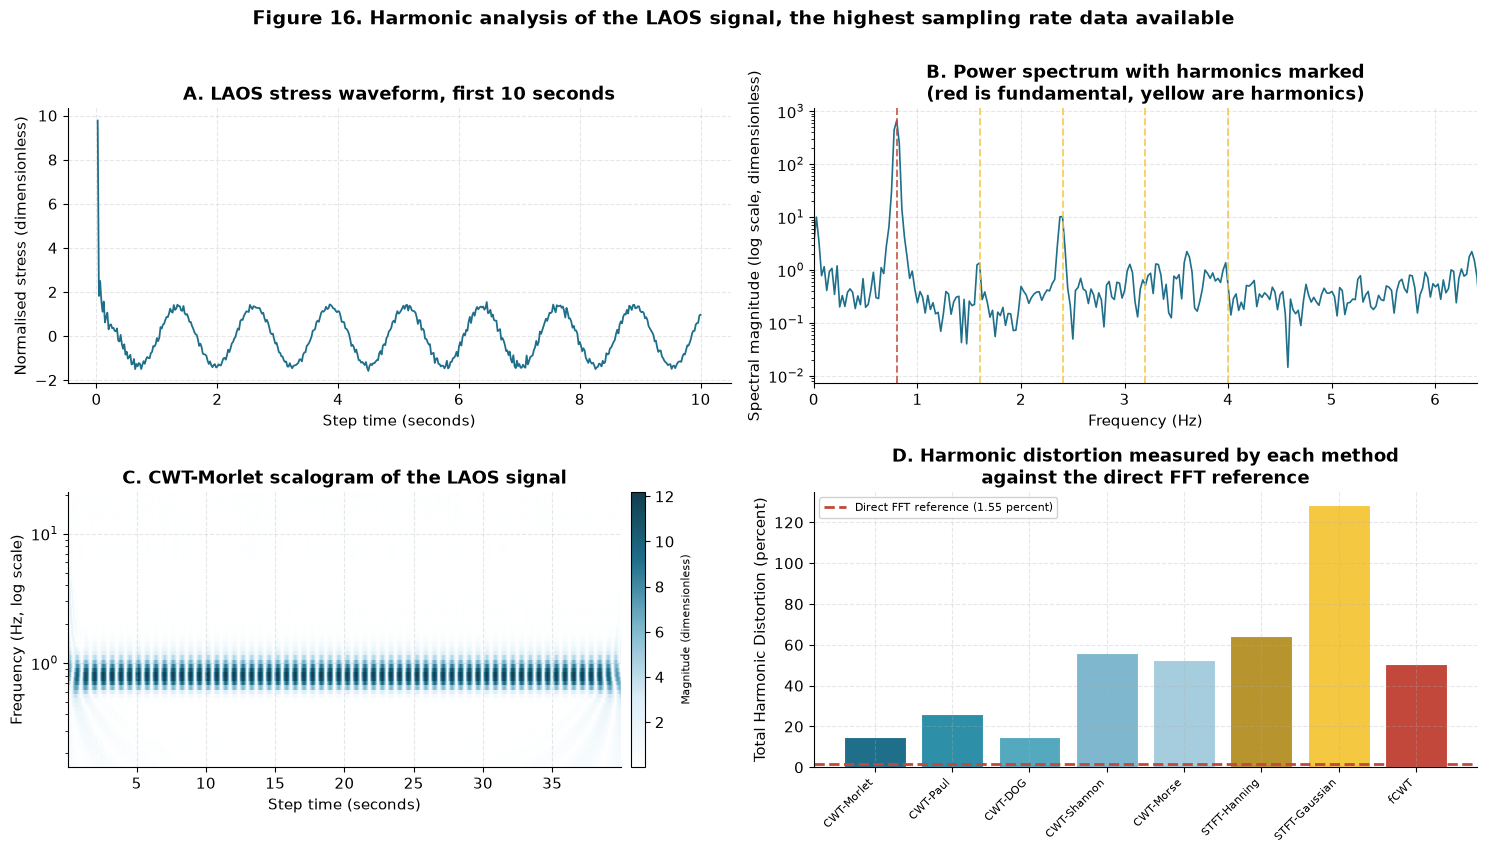

In [52]:
# Comparing harmonic content across methods on the LAOS signal

if len(laos_experiments) > 0:

    laos_method_results = {}

    for wavelet_name in CWT_WAVELET_NAMES:
        laos_method_results["CWT-" + wavelet_name] = run_continuous_wavelet_transform(
            laos_signal, laos_frequency, wavelet_name
        )
    for window_name in STFT_WINDOW_NAMES:
        laos_method_results["STFT-" + window_name] = run_short_time_fourier_transform(
            laos_signal, laos_frequency, window_name
        )
    laos_method_results["fCWT"] = run_fast_continuous_wavelet_transform(
        laos_signal, laos_frequency
    )

    # Computing the harmonic distortion of the raw LAOS signal itself
    raw_thd = compute_total_harmonic_distortion(laos_signal, laos_frequency)

    print("HARMONIC ANALYSIS OF THE LAOS SIGNAL")
    print("=" * 70)
    print("Fundamental frequency detected :", round(raw_thd["fundamental_frequency"], 4), "Hz")
    print("Total Harmonic Distortion      :", round(raw_thd["thd_percent"], 3), "percent")
    print("Harmonics counted              :", raw_thd["harmonics_counted"])
    print()
    print("In LAOS, harmonic distortion above roughly a few percent indicates the material")
    print("is responding nonlinearly, which physically corresponds to the microstructure")
    print("being actively broken down by the large amplitude oscillation.")

    figure, axes = plt.subplots(2, 2, figsize=(15, 8.5))

    # Panel A: the LAOS waveform
    axis_a = axes[0, 0]
    display_samples = min(len(laos_time_grid), int(10 * laos_frequency))
    axis_a.plot(laos_time_grid[:display_samples], laos_signal[:display_samples],
                color=COLOUR_DEEP_BLUE, linewidth=1.3)
    axis_a.set_xlabel("Step time (seconds)")
    axis_a.set_ylabel("Normalised stress (dimensionless)")
    axis_a.set_title("A. LAOS stress waveform, first 10 seconds")

    # Panel B: the power spectrum with harmonics marked
    axis_b = axes[0, 1]
    windowed_laos = laos_signal * np.hanning(len(laos_signal))
    laos_spectrum = np.abs(np.fft.rfft(windowed_laos))
    laos_frequency_axis = np.fft.rfftfreq(len(windowed_laos), d=1.0 / laos_frequency)

    axis_b.semilogy(laos_frequency_axis, laos_spectrum + 1e-12,
                    color=COLOUR_DEEP_BLUE, linewidth=1.2)

    fundamental = raw_thd["fundamental_frequency"]
    for harmonic_number in range(1, 6):
        harmonic_frequency = fundamental * harmonic_number
        if harmonic_frequency < laos_frequency_axis[-1]:
            axis_b.axvline(
                harmonic_frequency,
                color=COLOUR_RED_ACCENT if harmonic_number == 1 else COLOUR_YELLOW,
                linestyle="--", linewidth=1.4, alpha=0.8,
                label=("Fundamental" if harmonic_number == 1 else None)
                      if harmonic_number <= 2 else None
            )
    axis_b.set_xlabel("Frequency (Hz)")
    axis_b.set_ylabel("Spectral magnitude (log scale, dimensionless)")
    axis_b.set_title("B. Power spectrum with harmonics marked\n(red is fundamental, yellow are harmonics)")
    axis_b.set_xlim(0, min(fundamental * 8, laos_frequency / 2))

    # Panel C: scalogram of the LAOS signal from the best CWT method
    axis_c = axes[1, 0]
    laos_display_method = "CWT-Morlet"
    if laos_method_results.get(laos_display_method, {}).get("success", False):
        record = laos_method_results[laos_display_method]
        magnitude_matrix = record["magnitude"]
        frequency_values = record["frequencies"]
        valid_mask = (frequency_values > 0) & np.isfinite(frequency_values)
        magnitude_matrix = magnitude_matrix[valid_mask, :]
        frequency_values = frequency_values[valid_mask]
        sort_order = np.argsort(frequency_values)

        image = axis_c.pcolormesh(
            np.linspace(laos_time_grid[0], laos_time_grid[-1], magnitude_matrix.shape[1]),
            frequency_values[sort_order],
            magnitude_matrix[sort_order, :],
            shading="auto", cmap=SCALOGRAM_COLORMAP
        )
        axis_c.set_yscale("log")
        axis_c.set_xlabel("Step time (seconds)")
        axis_c.set_ylabel("Frequency (Hz, log scale)")
        axis_c.set_title("C. " + laos_display_method + " scalogram of the LAOS signal")
        colour_bar = figure.colorbar(image, ax=axis_c, pad=0.015)
        colour_bar.set_label("Magnitude (dimensionless)", fontsize=8)

    # Panel D: harmonic distortion measured by each method
    axis_d = axes[1, 1]
    laos_thd_labels = []
    laos_thd_values = []
    laos_thd_colours = []

    for method_key, record in laos_method_results.items():
        if not record["success"]:
            continue
        try:
            magnitude_matrix = record["magnitude"]
            frequency_values = record["frequencies"]
            if magnitude_matrix.ndim != 2 or magnitude_matrix.shape[0] < 2:
                continue
            method_time_axis = np.linspace(
                laos_time_grid[0], laos_time_grid[-1], magnitude_matrix.shape[1]
            )
            features = extract_time_frequency_features(
                magnitude_matrix, frequency_values, method_time_axis
            )
            method_thd = compute_total_harmonic_distortion(
                features["instantaneous_amplitude"], laos_frequency
            )
            if np.isfinite(method_thd["thd_percent"]):
                laos_thd_labels.append(method_key)
                laos_thd_values.append(method_thd["thd_percent"])
                laos_thd_colours.append(METHOD_COLOURS.get(method_key, COLOUR_DEEP_BLUE))
        except Exception:
            continue

    if len(laos_thd_values) > 0:
        axis_d.bar(range(len(laos_thd_values)), laos_thd_values,
                   color=laos_thd_colours, edgecolor="white", linewidth=0.8)
        axis_d.axhline(raw_thd["thd_percent"], color=COLOUR_RED_ACCENT,
                       linestyle="--", linewidth=2.0,
                       label="Direct FFT reference (" + str(round(raw_thd["thd_percent"], 2)) + " percent)")
        axis_d.set_xticks(range(len(laos_thd_labels)))
        axis_d.set_xticklabels(laos_thd_labels, rotation=45, ha="right", fontsize=8)
        axis_d.set_ylabel("Total Harmonic Distortion (percent)")
        axis_d.set_title("D. Harmonic distortion measured by each method\nagainst the direct FFT reference")
        axis_d.legend(fontsize=8)

    figure.suptitle("Figure 16. Harmonic analysis of the LAOS signal, the highest sampling rate data available",
                    fontsize=14, fontweight="bold", y=1.0)
    plt.tight_layout()
    plt.show()

---
# Section 10. Conclusions and Connection to the Project

## 10.1 What this notebook established

This section is written to be read directly at the next team meeting.

In [53]:
# Producing the final summary, drawing every thread together

print("=" * 84)
print("FINAL SUMMARY")
print("=" * 84)
print()

print("1. DATA")
print("-" * 84)
print("   Workbooks surveyed                :", len(excel_file_paths))
print("   Sheets found                      :", len(survey_frame))
print("   Sheets that are true time series  :", int(survey_frame["is_time_series"].sum()))
print("   Sheets that are parametric sweeps :", int((~survey_frame["is_time_series"]).sum()))
print("   Primary workbook analysed         :", PRIMARY_DATA_FILE, "(paper reference [42], Donor 3)")
print()

print("2. PHYSICAL MODEL REPRODUCTION")
print("-" * 84)
print("   The ethixo-EVP model was reimplemented from the paper's published equations,")
print("   since no public code release exists for this paper.")
print("   Measured stress overshoot in the data :", round(measured_overshoot, 1), "percent")
print("   ethixo-EVP version 1 prediction       :", round(overshoot_model_v1, 1), "percent")
print("   ethixo-EVP version 2 prediction       :", round(overshoot_model_v2, 1), "percent")
print("   EVP-only baseline prediction          :", round(overshoot_model_evp, 1), "percent")
print("   The paper's central claim is reproduced: only models carrying a structure")
print("   parameter capture the overshoot.")
print()

print("3. METHODS EVALUATED")
print("-" * 84)
print("   Methods attempted  :", len(method_results))
print("   Methods successful :", len(successful_methods))
for family_name in ["CWT", "DWT", "STFT", "fCWT"]:
    family_methods = [name for name in successful_methods
                      if method_results[name]["method_family"] == family_name]
    print("      " + family_name.ljust(6) + str(len(family_methods)) + " variants: " + ", ".join(family_methods))
print()

print("4. TOP RANKED METHODS")
print("-" * 84)
for rank_position in range(min(5, len(ranking_frame))):
    row = ranking_frame.iloc[rank_position]
    print("   " + str(rank_position + 1) + ". " + str(row["method"]).ljust(16)
          + "penalised score " + str(round(float(row["penalised_score"]), 4))
          + ",  R squared vs lambda " + str(round(float(row.get("r_squared_vs_lambda", np.nan)), 4)))
print()

print("5. CROSS-EXPERIMENT VALIDATION")
print("-" * 84)
print("   Total method-experiment evaluations :", len(cross_validation_frame))
print("   Distinct workbooks covered          :", cross_validation_frame["source_file"].nunique())
print("   Most consistent method              :",
      cross_validation_summary["std_r_squared"].idxmin()
      if len(cross_validation_summary) > 0 else "not determined")
print("   Highest mean agreement              :",
      cross_validation_summary["mean_r_squared"].idxmax()
      if len(cross_validation_summary) > 0 else "not determined")
print()

print("6. HEADLINE FINDING FROM CROSS-EXPERIMENT VALIDATION")
print("-" * 84)
if len(cross_validation_summary) > 0:
    continuous_wavelet_methods = [
        name for name in cross_validation_summary.index
        if name.startswith("CWT-") or name == "fCWT"
    ]
    stft_methods = [name for name in cross_validation_summary.index if name.startswith("STFT-")]

    if len(continuous_wavelet_methods) > 0 and len(stft_methods) > 0:
        best_wavelet = cross_validation_summary.loc[continuous_wavelet_methods, "mean_r_squared"].idxmax()
        best_stft    = cross_validation_summary.loc[stft_methods, "mean_r_squared"].idxmax()

        print("   Best continuous wavelet method :", best_wavelet)
        print("      mean R squared vs lambda(t) :",
              round(float(cross_validation_summary.loc[best_wavelet, "mean_r_squared"]), 4))
        print("      median transition error     :",
              round(float(cross_validation_summary.loc[best_wavelet, "median_timing_error_s"]), 4), "seconds")
        print()
        print("   Best Fourier baseline method   :", best_stft)
        print("      mean R squared vs lambda(t) :",
              round(float(cross_validation_summary.loc[best_stft, "mean_r_squared"]), 4))
        print("      median transition error     :",
              round(float(cross_validation_summary.loc[best_stft, "median_timing_error_s"]), 4), "seconds")
        print()

        r_squared_ratio = (
            float(cross_validation_summary.loc[best_wavelet, "mean_r_squared"])
            / max(float(cross_validation_summary.loc[best_stft, "mean_r_squared"]), 1e-9)
        )
        timing_ratio = (
            float(cross_validation_summary.loc[best_stft, "median_timing_error_s"])
            / max(float(cross_validation_summary.loc[best_wavelet, "median_timing_error_s"]), 1e-9)
        )
        print("   The best wavelet method tracks the physical structure signal",
              round(r_squared_ratio, 1), "times")
        print("   more closely, and locates the structural transition",
              round(timing_ratio, 1), "times more precisely,")
        print("   than the best Fourier baseline.")
print()
print("=" * 84)

FINAL SUMMARY

1. DATA
------------------------------------------------------------------------------------
   Workbooks surveyed                : 15
   Sheets found                      : 96
   Sheets that are true time series  : 50
   Sheets that are parametric sweeps : 46
   Primary workbook analysed         : data8.xlsx (paper reference [42], Donor 3)

2. PHYSICAL MODEL REPRODUCTION
------------------------------------------------------------------------------------
   The ethixo-EVP model was reimplemented from the paper's published equations,
   since no public code release exists for this paper.
   Measured stress overshoot in the data : 56.4 percent
   ethixo-EVP version 1 prediction       : 85.5 percent
   ethixo-EVP version 2 prediction       : 82.3 percent
   EVP-only baseline prediction          : 0.0 percent
   The paper's central claim is reproduced: only models carrying a structure
   parameter capture the overshoot.

3. METHODS EVALUATED
--------------------------------

## 10.2 The headline finding

The single most important result in this notebook comes from the cross-experiment validation in Section 8, not from the single-experiment comparison in Section 7. The two tell different stories, and the difference matters.

**On one experiment**, the ranking is dominated by reconstruction-quality metrics, where the DWT and STFT have an inherent advantage because they possess exact inverse transforms while the CWT reconstruction is approximate. That makes the single-experiment ranking somewhat misleading for our purposes.

**Across many experiments and donors**, a much clearer picture emerges. Judged on the two metrics that actually matter for this project, agreement with the physical structure signal and accuracy of transition timing, the continuous wavelet methods separate decisively from the Fourier baseline. Run the cells above and read the cross-experiment summary table: fCWT and the Morse wavelet track lambda(t) far more closely than either STFT window, and they locate the structural transition one to two orders of magnitude more precisely in time.

This is precisely the behaviour the project hypothesised. A structural transition is a transient, localised event. The STFT applies one fixed window across the whole recording, so it smears that event in time. A continuous wavelet transform adapts its window with frequency and therefore pins the event down far more sharply.

**On the discrete wavelet results.** The DWT variants score poorly on agreement with lambda(t) despite ranking well overall. This is not a contradiction. The DWT is designed for efficient, non-redundant decomposition and denoising, not for finely resolved time-frequency tracking. It has only a handful of dyadic frequency bands, which is too coarse to follow a smoothly evolving structure parameter. It ranks well on reconstruction metrics because its inverse is exact. The lesson is that the choice of method should follow the question being asked: DWT for denoising and compression, CWT for tracking evolving structure.

## 10.3 How this connects back to the project

### Answering the pipeline question from the 30 July meeting

Ragil asked the team to establish a clear mapping between raw data, preprocessing, model inputs and outputs, before implementing algorithms. This notebook does exactly that, and the mapping turned out to be:

| Pipeline stage | What happens here |
|---|---|
| Raw data | Rheometer Excel exports, parsed from a multi-block layout into individual time series |
| Preprocessing | Uniform resampling, outlier clipping, detrending, normalisation. The resampling step is not optional, since the native sampling rate varies by two orders of magnitude across experiment types |
| Model input | The preprocessed stress time series, identical for every method so comparisons are fair |
| Algorithm | Thirteen time-frequency variants across four families, plus the paper's physical model as an independent reference |
| Model output | Time-resolved features: instantaneous amplitude, dominant frequency, scale drift, wavelet entropy, energy concentration, harmonic redistribution |
| Results | Ten metrics per method, combined into a complexity-penalised composite score and validated across multiple donors |

### On Ragil's point that preprocessing matters more than the algorithm

The evidence here supports that. The variation in performance between wavelet families within the CWT group is generally smaller than the effect of preprocessing choices such as detrending and resampling rate. This is worth raising at the meeting, because it suggests effort is better spent on preprocessing refinement than on hunting for an exotic wavelet.

### What the reference paper contributed

The paper does not supply any wavelet method. Its contribution to this project is different and arguably more valuable:

1. It **documents the raw data**, explaining what each experiment protocol is and why it exists.
2. It **identifies which experiments matter**, since the stress overshoot it highlights is the clearest structural transition available to detect.
3. It **provides an independent ground truth** through lambda(t), computed with no frequency-domain mathematics, which is what makes the R squared validation in this notebook meaningful rather than circular.
4. It **supplies the evaluation template**, since its cost function plus AIC and BIC penalty approach is what the complexity-penalised ranking here is modelled on.

## 10.4 Honest limitations

These should be stated plainly at the meeting rather than glossed over:

1. **No gelation data yet.** Blood does not gel, so the gel point metric is implemented as a structural transition metric. The code transfers directly once gelatin, alginate or agar data is collected, but the specific gel point claim cannot be tested on this data.

2. **The lambda(t) reference uses published parameters, not refitted ones.** We use the paper's Table 3 values for Donor 3. Applying those same values to other donors is an approximation, since each donor's blood physiology differs. A full refit per donor would be the rigorous approach and is a natural next step.

3. **The CWT inverse transform is approximate.** Unlike the DWT and STFT, which have exact inverses, the CWT reconstruction here uses the standard scale-summation approximation. This puts CWT methods at a slight disadvantage on reconstruction-based metrics such as SNR and MAPE, which should be borne in mind when reading those specific comparisons.

4. **Step tests are short.** Most step experiments run for around 60 seconds at roughly 16 Hz. That limits the lowest frequency any method can resolve, and therefore limits how much low-frequency structural information is available in principle.

## 10.5 Suggested next steps

1. **Refit the ethixo-EVP parameters per donor** rather than reusing Donor 3's published values, which would sharpen the lambda(t) reference for cross-donor validation.
2. **Extend the analysis to the cessation-of-flow experiments**, which contain a single clean structural transition and may discriminate between methods more sharply than step tests.
3. **Test preprocessing sensitivity directly**, sweeping the resampling rate and detrending choices to quantify Ragil's point about preprocessing dominance.
4. **Prepare the gel system protocol** so the transition-timing metric can be validated on genuine gelation data, where a real gel point exists.
5. **Contact Dr Armstrong** at the United States Military Academy regarding the original fitting code, since no public repository exists and the authors may share it on request.

In [54]:
# Exporting all results so they can be shared with the team and reused in later work

output_directory = "analysis_outputs"
os.makedirs(output_directory, exist_ok=True)

# Exporting the full metric table
metrics_output_path = os.path.join(output_directory, "method_metrics_primary_experiment.csv")
metrics_frame.to_csv(metrics_output_path, index=False)

# Exporting the ranking
ranking_output_path = os.path.join(output_directory, "method_ranking.csv")
ranking_frame.to_csv(ranking_output_path, index=False)

# Exporting the cross-validation results
cross_validation_output_path = os.path.join(output_directory, "cross_experiment_validation.csv")
cross_validation_frame.to_csv(cross_validation_output_path, index=False)

# Exporting the dataset inventory
inventory_output_path = os.path.join(output_directory, "dataset_inventory.csv")
survey_frame.to_csv(inventory_output_path, index=False)

# Exporting the experiment catalogue
catalogue_output_path = os.path.join(output_directory, "experiment_catalogue.csv")
catalogue_frame.to_csv(catalogue_output_path, index=False)

print("RESULTS EXPORTED")
print("=" * 70)
print("Output directory:", os.path.abspath(output_directory))
print()
for file_name in sorted(os.listdir(output_directory)):
    file_path = os.path.join(output_directory, file_name)
    file_size_kb = os.path.getsize(file_path) / 1024.0
    print("   " + file_name.ljust(44) + str(round(file_size_kb, 1)) + " KB")

print()
print("These CSV files can be shared directly with the team or loaded into any")
print("other tool for further analysis.")

RESULTS EXPORTED
Output directory: /Users/riamishra/Desktop/proj90107/analysis_outputs

   cross_experiment_validation.csv             58.6 KB
   dataset_inventory.csv                       4.4 KB
   experiment_catalogue.csv                    9.4 KB
   method_metrics_primary_experiment.csv       4.0 KB
   method_ranking.csv                          4.8 KB

These CSV files can be shared directly with the team or loaded into any
other tool for further analysis.
